## **Proyecto Final - Gestión De Datos.** 
### **Monitoreo de reputación de marca. Caso de Estudio: Davivienda Colombia**

Integrantes del Equipo:

- David Felipe Bautista
- Fabian Becerra
- Belky Xiomara Mayorga


### **Contenido**
1. Contexto del proyecto.
2. Elevator pitch: preguntas y justificación
3. Carga de datos principales
4. Carga y justificación de datos complementarios
5. Exploración de los datos
6. Preparación de los datos
7. Visualización de los datos
8. Conclusiones, limitaciones y trabajo futuro
9. Trabajo en equipo
10. Enlaces a lo generado
11. Referencias
- Anexo A. Bitácora agéntica
- Anexo B. Diccionario de variables derivadas



**Nota importante:** Algunos párrafos de este notebook fueron generados con el apoyo de agentes de inteligencia artificial como copilotos de código. Estas secciones se identifican con el indicador (🤖) al inicio del texto; el resto del contenido fue redactado y revisado íntegramente por los integrantes del equipo.

---
## **1. Contexto del proyecto**

### **1.1 El problema de negocio**

Tener buena reputación es clave para que cualquier empresa pueda mover sus productos o servicios, pero en el sector financiero esta cuestión es aun más importante porque la confianza se juega en cada interacción y con cada cliente y se puede ir al piso en cuestión de días, o incluso por un solo evento grave. El ESE Business School (2023) señala que la reputación corporativa es un activo intangible fundamental que se construye y se sostiene a través de un buen servicio al cliente y de la capacidad de respuesta de la organización.

Cuando fallas operativas como cobros que la persona no reconoce, bloqueos de tarjetas sin razón o demoras eternas en la atención se vuelven pan de cada día, por no mencionar eventos más graves, el problema avanza rápido. Arranca como una queja simple, sube a un reclamo formal ante el regulador, empieza a rodar con fuerza en redes sociales y, si nadie hace nada, termina reventando en los medios de comunicación. El inconveniente es que apagar un incendio mediático siempre va a salir más caro que haber evitado el problema a tiempo, justamente, una de las recomendaciones clave para proteger este activo es monitorear activamente los comentarios y examinar las críticas de manera oportuna.

Ahora bien, aquí en Colombia las entidades vigiladas por la Superintendencia Financiera (SFC) están obligadas por ley a reportar todas las quejas que les llegan, y esos datos quedan abiertos al público. Eso nos da una ventaja enorme porque podemos medir la reputación de un banco con cifras oficiales y reales, dejando de lado las simples opiniones, el ruido de las redes o incluso el voz a voz.

Con todo lo anterior se plantea como objetivo de este proyecto usar los datos abiertos de datos.gov.co para el monitoreo de la reputación de la marca de una entidad financiera, detectando a tiempo fallas en el servicio para anticiparse a cualquier crisis antes de que escale.


-----------------

### **1.2 Por qué Davivienda**

Para aterrizar el monitoreo propuesto en el proyecto en un caso real, se eligió al Banco Davivienda por ser una entidad financiera masiva con millones de clientes en todo el país, alcanzando los 25.3 millones a noviembre de 2026 según Forbes, lo que la convierte en un referente muy claro para entender cómo se comporta la reputación en el consumo financiero diario. Además de su relevancia en el mercado, el banco es completamente rastreable dentro de la información oficial de la SFC. Por otro lado, vale la pena resaltar la cercanía del equipo de trabajo con el funcionamiento interno de la entidad, una ventaja que permitirá sumar matices específicos a todo el análisis construido.

Asimismo, otro punto fuerte de esta elección es la profundidad y el detalle de los datos disponibles. Contamos con una serie de tiempo lo suficientemente larga para observar tendencias reales, sumada a la posibilidad de cruzar las quejas por producto, motivo específico y ubicación geográfica en los años más recientes. De igual forma, saber si cada caso se resolvió a favor del consumidor o del banco resulta clave para separar el simple ruido de las fallas reales en el servicio.



### **1.3 Marco metodológico y alcance del proyecto**

El proyecto se desarrolla bajo el estándar de referencia CRISP-DM, una metodología que organiza los proyectos de analítica en seis etapas, comprensión del negocio, comprensión de los datos, preparación, modelado, evaluación y despliegue. 

Este primer hito cubre exactamente las tres primeras fases. Primero se define el problema de negocio y las preguntas clave, luego se cargan y exploran los datos para revisar su calidad y contenido, y finalmente se limpian y transforman hasta consolidar una vista minable.

Vale la pena precisar que en esta etapa todavía no se construye un modelo predictivo ni un sistema productivo. El monitoreo de la reputación se aborda desde la analítica descriptiva y diagnóstica, combinando indicadores calculados con cifras oficiales, una regla estadística sencilla para detectar picos anormales de quejas y visualizaciones sobre dónde y cuándo se concentran los problemas.

### **1.4 Fase 1 - Comprensión del negocio**

**Objetivo de negocio**

Otorgar al responsable dentro de Davivienda un sistema de monitoreo de reputación basado en datos oficiales. Con esta herramienta podrá saber con claridad qué está fallando por producto y motivo, en qué región sucede, cuándo aparecen tendencias o picos de inconformidad y qué tan fundadas son las quejas, permitiéndole actuar antes de que un problema escale hacia una crisis.

**Objetivos de minería de datos**

Para traducir esa necesidad del banco en tareas técnicas, el análisis se divide en tres frentes concretos:

- Identificar los productos y motivos con mayor proporción de quejas fundadas calculando tasas a favor del consumidor y tablas de contingencia.

- Identificar los meses y departamentos con volúmenes de quejas fuera de lo normal aplicando la regla estadística de Tukey y variables de alerta, teniendo en cuenta la presencia del banco en cada departamento para no confundir tamaño con problema.

- Integrar ambas miradas en una sola vista minable, de modo que cada alerta regional se pueda leer junto con qué tan fundadas suelen ser las quejas de ese producto.


**Criterios de éxito del hito**

Para validar que esta primera entrega cumpla con lo esperado, el cuaderno debe responder con evidencia calculada a las preguntas planteadas y dejar los datos integrados en una vista minable limpia, justificando cada decisión de calidad.

### **1.5 Fase 2  - Fuentes de datos (vista previa)**

A continuación se presenta el papel de las fuentes de datos usadas dentro del proyecto; más detalle se podrá ver dentro de las secciones 3 y 4.


| Rol | ID en datos.gov.co | Contenido | Aporte |
|---|---|---|---|
| Principal | `hjqv-fp48` | Quejas ante entidades vigiladas por la SFC y defensores del consumidor financiero (2010–2022) | Nombre de la entidad, producto, motivo y desenlace de la queja |
| Complementario 1 | `xyy7-rn7p` | Quejas de consumidores financieros (Smartsupervision, 2023 en adelante) | Continuación de la serie y ubicación geográfica (departamento, municipio) |
| Complementario 2 | `vkbt-desu` | Puntos de atención de las entidades financieras por municipio (con la tabla de códigos DIVIPOLA) | Presencia del banco en cada departamento, para comparar regiones de distinto tamaño |
| Complementario 3 | `73dx-n59j` | Sanciones en firme de la Superintendencia de Industria y Comercio | Contexto del sector (la SIC no sanciona bancos por nombre) |

**Llave de integración:** `(tipo_entidad, codigo_entidad)`, común a las fuentes de la SFC. Dentro de la vista minable, las fuentes se cruzan además por producto homologado, departamento y mes.

**Supuestos y limitaciones conocidas desde el inicio**

- Las dos fuentes de quejas usan nomenclaturas distintas de `producto` y `motivo`, de modo que se requiere una tabla de homologación (sección 6.2).
- Smartsupervision no dice cómo terminó cada queja, así que las quejas fundadas (P1) solo se pueden medir con la fuente principal, es decir, hasta 2022. Después de esa fecha solo se pueden estimar con la tasa histórica de cada producto.
- Entre julio y diciembre de 2022 ninguna de las dos fuentes reporta quejas recibidas, porque la SFC estaba cambiando de sistema. Ese semestre queda como un hueco en la serie.


---
### **1.6 Entorno de trabajo**

🤖 Este cuaderno recibe los datos **ya descargados y validados** por `00_Extraccion_datos_gov.ipynb`, guardados como CSV en el repositorio. La celda siguiente detecta si corre en Google Colab o localmente, carga las librerías de análisis, define las constantes del proyecto y comprueba que los cinco archivos estén completos y sin modificaciones. No contiene lógica de descarga ni gestión de tokens; eso pertenece al cuaderno de extracción. La integración de las fuentes se hace más adelante, en las secciones 4.4 y 6.5.


In [1]:
import sys, json, hashlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


warnings.filterwarnings("ignore", category=FutureWarning)
EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    from google.colab import drive; drive.mount('/content/gdrive')

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3})

MARCA = "davivienda"
FECHA_DESDE = "2010-01-01"
ENTIDADES_COD = {39: "Banco Davivienda", 42: "Fiduciaria Davivienda", 26: "Corredores Davivienda"}

DATASETS_SPEC = {
    "quejas_sfc": {"cols": 18, "registros_min": 9000},
    "quejas_smartsupervision": {"cols": 10, "registros_min": 100000},
    "sanciones_sic": {"cols": 7, "registros_min": 200},
    "puntos_atencion": {"cols": 11, "registros_min": 50000},
    "divipola_departamentos": {"cols": 4, "registros_min": 33},
}

BASE_DIR = Path("/content/gdrive/MyDrive/proyecto-final-gestion-datos") if EN_COLAB else Path.cwd()
REPO_RAW = "https://raw.githubusercontent.com/BautistaDavid/proyecto-final-gestion-datos/main/datos/raw"
DATA_DIR = BASE_DIR / "datos" / "raw"

datos, metadatos = {}, None

try:
    if EN_COLAB and not DATA_DIR.exists():
        [datos.update({n: pd.read_csv(f"{REPO_RAW}/{n}.csv")}) for n in DATASETS_SPEC]
        import requests
        metadatos = requests.get(f"{REPO_RAW}/metadatos.json").json()
    else:
        [datos.update({n: pd.read_csv(DATA_DIR / f"{n}.csv")}) for n in DATASETS_SPEC]
        metadatos = json.load(open(DATA_DIR / "metadatos.json", 'r', encoding='utf-8'))
except Exception as e:
    print(f"✗ Error: {e}"); raise

for nombre, spec in DATASETS_SPEC.items():
    df = datos[nombre]
    if len(df.columns) != spec['cols']: print(f"⚠ {nombre}: {len(df.columns)} cols vs {spec['cols']} esperadas")
    if len(df) < spec['registros_min']: print(f"⚠ {nombre}: {len(df)} registros < {spec['registros_min']}")

if metadatos:
    for nombre in DATASETS_SPEC:
        ruta = DATA_DIR / f"{nombre}.csv"
        if ruta.exists():
            hash_local = hashlib.sha256(open(ruta, 'rb').read()).hexdigest()
            hash_esp = metadatos['datasets'][nombre]['hash_sha256']
            status = "✓ OK" if hash_local == hash_esp else f"✗ {hash_local[:8]}... ≠ {hash_esp[:8]}..."
            print(f"{status} | {nombre}: SHA-256")

print(f"\n{'─'*70}\nPython {sys.version.split()[0]} · pandas {pd.__version__} · numpy {np.__version__}")
print(f"Ejecutando en: {'Google Colab' if EN_COLAB else 'Local'}")
print(f"Marca: {MARCA} · período: {FECHA_DESDE} en adelante")
print(f"Datasets: {len(datos)} | Total: {sum(len(d) for d in datos.values()):,} registros")
for n, d in datos.items():
    print(f"  • {n}: {len(d):,} filas × {len(d.columns)} columnas")

✓ OK | quejas_sfc: SHA-256
✓ OK | quejas_smartsupervision: SHA-256
✓ OK | sanciones_sic: SHA-256
✓ OK | puntos_atencion: SHA-256
✓ OK | divipola_departamentos: SHA-256

──────────────────────────────────────────────────────────────────────
Python 3.14.3 · pandas 3.1.0 · numpy 2.5.4
Ejecutando en: Local
Marca: davivienda · período: 2010-01-01 en adelante
Datasets: 5 | Total: 184,592 registros
  • quejas_sfc: 9,953 filas × 18 columnas
  • quejas_smartsupervision: 113,327 filas × 10 columnas
  • sanciones_sic: 281 filas × 7 columnas
  • puntos_atencion: 60,998 filas × 11 columnas
  • divipola_departamentos: 33 filas × 4 columnas


---
## **2. Elevator pitch**

En esta sección se discuten las preguntas planteadas, se justifica su relevancia y se consolida la propuesta de valor del proyecto. Este análisis es fundamental para estructurar y respaldar de manera efectiva la presentación del pitch final.

### **2.1 El problema en una frase**

Las entidades financieras se enteran de sus crisis de reputación cuando ya son noticia, aunque las señales llevan meses registradas en las quejas que reciben y reportan a los entes supervisores y de control.

### **2.2 Preguntas planteadas**

- **P1: ¿Qué productos y motivos concentran las quejas fundadas (aquellas resueltas a favor del consumidor) contra Davivienda, y cómo ha cambiado esa composición entre 2010 y 2022?**

- **P2: ¿Es posible identificar, a partir de la serie mensual de quejas por departamento, picos atípicos que sirvan como señal de alerta para la reputación de Davivienda?**

### **2.3 Justificación**

**P1 - ¿Qué corregir primero?**

 El volumen total de quejas mezcla reclamos fundados con inconformidades que no proceden. Cuando una queja se resuelve a favor del consumidor, la propia entidad reconoce que hubo una falla en su servicio. Concentrar el análisis en esas quejas permite a la marca priorizar los productos y procesos que realmente están fallando y medir si las correcciones funcionan con el paso del tiempo. En ultimas, con esta visión se resuelve un problema existente, la falta de una medida objetiva de la calidad del servicio por producto.

**P2 — Actuar antes de la crisis.** Un aumento anormal de quejas en una región o en un mes concreto puede ser la primera señal de un problema que después se vuelve público. Detectar estos picos con una regla estadística sencilla y explicable (rango intercuartílico) **convierte un monitoreo reactivo en uno preventivo**. Mejora un proceso actual: hoy la reacción ocurre cuando el problema ya es visible.

**Por qué con datos abiertos.** Los datos provienen de reportes obligatorios supervisados por la Superintendencia Financiera: son oficiales, verificables, comparables entre entidades y gratuitos.

### **2.4 Venta del proyecto**

| Elemento | Contenido |
|---|---|
| **Patrocinador objetivo** | Davivienda (Vicepresidencia de Experiencia del Cliente y área de riesgo reputacional). Alternativas: Asobancaria, para un monitoreo sectorial, o la propia SFC |
| **Qué ofrecemos** | Un sistema de alerta temprana de reputación construido con datos oficiales, reproducible y actualizable cada mes |
| **Evidencia** | *[cifra]* de quejas analizadas; *[cifra]* % resueltas a favor del consumidor; *[cifra]* meses o departamentos con alerta en el periodo analizado |
| **Qué gana el patrocinador** | Saber qué arreglar primero (P1) y enterarse de los problemas antes que los medios (P2) |
| **Pedido** | Financiación para la siguiente fase: modelo predictivo de alertas y tablero de monitoreo mensual |

### Guion del pitch (5 minutos)
1. **Gancho (30 s):** una crisis de reputación ya ocurrida en el sector y su costo.
2. **Problema (1 min):** las señales existen en los datos, pero nadie las mira a tiempo.
3. **Solución (1 min 30 s):** las dos preguntas y cómo se responden.
4. **Evidencia (1 min 30 s):** dos hallazgos con cifras del cuaderno.
5. **Pedido (30 s):** qué se necesita del patrocinador y qué recibirá a cambio.

---
## **3. Carga de datos principales**

Responde al punto 2 del reporte. Los datos ya vienen descargados desde la API de datos.gov.co por el cuaderno `00_Extraccion_datos_gov.ipynb` y se cargan en la sección 1.6; aquí se documenta de dónde salieron y cómo está armado el dataset principal.

### **3.1 Procedencia y trazabilidad**

🤖 En lugar de descargar desde la API en vivo, esta sección documenta la descarga reproducible capturada en `metadatos.json`. Eso reemplaza una descarga tradicional por tres ventajas: (1) cualquiera puede verificar que el CSV del repositorio es idéntico al analizado usando el hash SHA-256, (2) la consulta SoQL original se puede repetir en datos.gov.co si es necesario, y (3) la fecha exacta de extracción queda registrada para auditabilidad.

In [2]:
from datetime import datetime

# Construir tabla de procedencia desde metadatos
datos_procedencia = []
for nombre in DATASETS_SPEC:
    meta = metadatos['datasets'][nombre]
    rol = {"quejas_sfc": "Principal", "divipola_departamentos": "Tabla de apoyo"}.get(nombre, "Complementario")
    filtro_corto = meta['filtro_aplicado'][:50] + "…" if len(meta['filtro_aplicado']) > 50 else meta['filtro_aplicado']
    datos_procedencia.append({
        "Dataset": nombre,
        "ID": meta['id_dataset'],
        "Rol": rol,
        "URL": meta['url_dataset'],
        "Filtro aplicado": filtro_corto,
        "Registros": f"{meta['cantidad_registros']:,}",
        "Columnas": meta['cantidad_columnas'],
        "Tamaño (KB)": f"{meta['tamano_bytes'] / 1024:.1f}",
        "SHA-256": meta['hash_sha256'][:12] + "…"
    })

tabla_procedencia = pd.DataFrame(datos_procedencia)
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio",
         "agosto", "septiembre", "octubre", "noviembre", "diciembre"]
fecha = datetime.fromisoformat(metadatos['fecha_descarga'])
fecha_desc = f"{fecha.day} de {MESES[fecha.month - 1]} de {fecha.year} a las {fecha:%H:%M}"
print(f"Fecha de descarga: {fecha_desc}\n")
display(tabla_procedencia)

# Verificación de integridad
print(f"\n{'─'*70}\nVerificación de carga:")
for nombre in DATASETS_SPEC:
    meta = metadatos['datasets'][nombre]
    registros_ok = len(datos[nombre]) == meta['cantidad_registros']
    columnas_ok = list(datos[nombre].columns) == meta['columnas']
    status = "✓" if (registros_ok and columnas_ok) else "✗"
    print(f"{status} {nombre}: {len(datos[nombre]):,} registros × {len(datos[nombre].columns)} columnas")

Fecha de descarga: 19 de noviembre de 2026 a las 14:08



,Dataset,ID,Rol,URL,Filtro aplicado,Registros,Columnas,Tamaño (KB),SHA-256
0,quejas_sfc,hjqv-fp48,Principal,https://www.datos.gov.co/dataset/hjqv-fp48,"nombre_entidad in ('Banco Davivienda', 'Fiduci...","9,953",18,1693.3,a7cf6e3ca347…
1,quejas_smartsupervision,xyy7-rn7p,Complementario,https://www.datos.gov.co/dataset/xyy7-rn7p,(tipo_entidad=1 AND codigo_entidad=39) OR (tip...,"113,327",10,14263.5,bd2b1d1f5327…
2,sanciones_sic,73dx-n59j,Complementario,https://www.datos.gov.co/dataset/73dx-n59j,sector = 'Servicios de financiación',281,7,41.1,f1b2208a2d92…
3,puntos_atencion,vkbt-desu,Complementario,https://www.datos.gov.co/dataset/vkbt-desu,tipo_entidad='1' AND codigo_entidad='39',"60,998",11,5267.4,dc041c65163e…
4,divipola_departamentos,vcjz-niiq,Tabla de apoyo,https://www.datos.gov.co/dataset/vcjz-niiq,Sin filtro (catálogo completo),33,4,1.5,e2f01cf489f4…



──────────────────────────────────────────────────────────────────────
Verificación de carga:
✓ quejas_sfc: 9,953 registros × 18 columnas
✓ quejas_smartsupervision: 113,327 registros × 10 columnas
✓ sanciones_sic: 281 registros × 7 columnas
✓ puntos_atencion: 60,998 registros × 11 columnas
✓ divipola_departamentos: 33 registros × 4 columnas


### Notas sobre la tabla

🤖 Los cinco archivos cargan con la integridad verificada: cada uno coincide exactamente con el hash registrado en la fecha de descarga. El dataset principal (`quejas_sfc`) aporta la serie trimestral de la SFC desde 2010 hasta 2022, que es todo el histórico publicado para Davivienda. Los complementarios extienden la cobertura temporal (Smartsupervision, mensual desde 2023), aportan la presencia del banco en cada región (puntos de atención) y el contexto sectorial (sanciones de la SIC). DIVIPOLA es solo una tabla de apoyo para traducir códigos de departamento. La siguiente subsección revisa cómo está armado el dataset principal y hasta dónde llega realmente su serie.

### **3.2 Dataset principal `hjqv-fp48`: estructura y alcance**

🤖 Este dataset cumple dos papeles en el proyecto: es la base de la **P1**, porque es la única fuente que dice si cada queja se resolvió a favor del consumidor, y de él sale la **tasa de quejas fundadas por producto** que entra como parámetro a la vista minable (sección 4.4). Esta subsección examina su estructura tal como viene, sin limpiarlo: qué define una fila (el **grano**), hasta dónde llega realmente la serie, cómo se comporta la tasa de quejas fundadas en el tiempo y de qué instancias provienen las quejas. Las decisiones de limpieza se toman en la sección 6.

In [3]:
quejas_sfc = datos["quejas_sfc"].copy()
quejas_sfc["fecha_corte"] = pd.to_datetime(quejas_sfc["fecha_corte"])
quejas_sfc["codigo_entidad"] = quejas_sfc["codigo_entidad"].astype(int)
quejas_sfc["codigo_producto"] = quejas_sfc["codigo_producto"].astype(int)
quejas_sfc["codigo_motivo"] = quejas_sfc["codigo_motivo"].astype(int)

# Tabla de entidades
datos_entidades = []
for cod in quejas_sfc["codigo_entidad"].unique():
    subset = quejas_sfc[quejas_sfc["codigo_entidad"] == cod]
    fecha_min = subset["fecha_corte"].min()
    fecha_max = subset["fecha_corte"].max()
    q_min = (fecha_min.month - 1) // 3 + 1
    q_max = (fecha_max.month - 1) // 3 + 1
    datos_entidades.append({
        "Código": cod,
        "Entidad": ENTIDADES_COD.get(cod, f"Desconocida ({cod})"),
        "Registros": len(subset),
        "Desde": f"{fecha_min.year}-Q{q_min}",
        "Hasta": f"{fecha_max.year}-Q{q_max}",
        "Productos únicos": subset["codigo_producto"].nunique(),
        "Motivos únicos": subset["codigo_motivo"].nunique()
    })

tabla_entidades = pd.DataFrame(datos_entidades).sort_values("Registros", ascending=False)
print(f"\n{'─'*70}\nCaracterización por entidad:")
display(tabla_entidades)
print(f"\nTotal de filas en quejas_sfc: {len(quejas_sfc):,}")


──────────────────────────────────────────────────────────────────────
Caracterización por entidad:


,Código,Entidad,Registros,Desde,Hasta,Productos únicos,Motivos únicos
0,39,Banco Davivienda,7867,2010-Q2,2022-Q4,24,64
2,42,Fiduciaria Davivienda,1571,2010-Q2,2022-Q3,9,30
1,26,Corredores Davivienda,515,2010-Q2,2022-Q2,10,30



Total de filas en quejas_sfc: 9,953


In [4]:
columnas_grano_sfc = ["codigo_entidad", "fecha_corte", "nombre_unidad_captura",
                      "codigo_producto", "codigo_motivo"]
repetidas_sfc = quejas_sfc.duplicated(columnas_grano_sfc, keep=False).sum()

print(f"{'─'*70}\nGrano: entidad × trimestre × unidad de captura × producto × motivo")
print(f"Combinaciones distintas: {quejas_sfc[columnas_grano_sfc].drop_duplicates().shape[0]:,} "
      f"de {len(quejas_sfc):,} filas")
print(f"Filas que repiten esa combinación: {repetidas_sfc:,}")

print("\nEjemplo de filas (cada una agrega varias quejas):")
display(quejas_sfc[columnas_grano_sfc + ["quejas_recibidas", "quejas_finalizad_favor_consum"]].head(5))

──────────────────────────────────────────────────────────────────────
Grano: entidad × trimestre × unidad de captura × producto × motivo
Combinaciones distintas: 9,953 de 9,953 filas
Filas que repiten esa combinación: 0

Ejemplo de filas (cada una agrega varias quejas):


,codigo_entidad,fecha_corte,nombre_unidad_captura,codigo_producto,codigo_motivo,quejas_recibidas,quejas_finalizad_favor_consum
0,39,2012-06-30,DEFENSORES DEL CONSUMIDOR FINANCIERO,1,280,5,5
1,39,2011-06-30,DEFENSORES DEL CONSUMIDOR FINANCIERO,5,355,1,0
2,39,2015-03-31,ENTIDAD VIGILADA,7,480,54,42
3,39,2010-12-31,DEFENSORES DEL CONSUMIDOR FINANCIERO,2,480,2,1
4,39,2013-06-30,DEFENSORES DEL CONSUMIDOR FINANCIERO,1,150,38,33


In [5]:
quejas_sfc["trimestre"] = quejas_sfc["fecha_corte"].dt.to_period("Q")
medidas = ["quejas_recibidas", "quejas_finalizadas", "quejas_finalizad_favor_consum"]
quejas_sfc[medidas] = quejas_sfc[medidas].astype(int)

por_ano = quejas_sfc.groupby(quejas_sfc["fecha_corte"].dt.year).agg(
    registros=("trimestre", "size"), **{m: (m, "sum") for m in medidas})
por_ano["tasa_favor_consumidor"] = (por_ano["quejas_finalizad_favor_consum"] /
                                    por_ano["quejas_finalizadas"]).round(3)
print(f"{'─'*70}\nCobertura por año:")
display(por_ano)

por_trimestre = quejas_sfc.groupby("trimestre").agg(
    registros=("trimestre", "size"), **{m: (m, "sum") for m in medidas})
print(f"\n{'─'*70}\nÚltimos 8 trimestres:")
display(por_trimestre.tail(8))

trimestres_esperados = pd.period_range(por_trimestre.index.min(), por_trimestre.index.max(), freq="Q")
print(f"Periodo: {por_trimestre.index.min()} a {por_trimestre.index.max()} · "
      f"{len(por_trimestre)} trimestres con datos · "
      f"faltantes: {list(trimestres_esperados.difference(por_trimestre.index).astype(str))}")
print(f"Mediana trimestral de quejas recibidas: {por_trimestre['quejas_recibidas'].median():,.0f}")

──────────────────────────────────────────────────────────────────────
Cobertura por año:


,registros,quejas_recibidas,quejas_finalizadas,quejas_finalizad_favor_consum,tasa_favor_consumidor
fecha_corte,,,,,
2010,364,21609,22679,18146,0.80
2011,534,30700,29747,18837,0.63
2012,615,50411,50367,35694,0.71
2013,736,60751,54698,41658,0.76
2014,783,54849,56964,42572,0.75
2015,628,70043,67829,48120,0.71
2016,816,96565,102654,67494,0.66
2017,791,102983,103143,70806,0.69
2018,758,132010,129945,96083,0.74



──────────────────────────────────────────────────────────────────────
Últimos 8 trimestres:


,registros,quejas_recibidas,quejas_finalizadas,quejas_finalizad_favor_consum
trimestre,,,,
2021Q1,235,60816,66049,53025
2021Q2,243,59433,60118,46422
2021Q3,256,55523,55577,41166
2021Q4,264,62954,63098,49869
2022Q1,263,58454,57030,42867
2022Q2,260,31820,35199,26549
2022Q3,138,23,1504,675
2022Q4,20,0,27,1


Periodo: 2010Q2 a 2022Q4 · 51 trimestres con datos · faltantes: []
Mediana trimestral de quejas recibidas: 20,901


In [6]:
por_unidad = quejas_sfc.groupby("nombre_unidad_captura").agg(
    registros=("trimestre", "size"),
    quejas_recibidas=("quejas_recibidas", "sum"),
    favor_consumidor=("quejas_finalizad_favor_consum", "sum"),
    productos=("codigo_producto", "nunique"),
    motivos=("codigo_motivo", "nunique"),
)
por_unidad["participacion_quejas"] = (por_unidad["quejas_recibidas"] /
                                      por_unidad["quejas_recibidas"].sum()).map("{:.1%}".format)

print(f"{'─'*70}\nUnidades de captura (instancias de recepción):")
display(por_unidad)

──────────────────────────────────────────────────────────────────────
Unidades de captura (instancias de recepción):


,registros,quejas_recibidas,favor_consumidor,productos,motivos,participacion_quejas
nombre_unidad_captura,,,,,,
DEFENSORES DEL CONSUMIDOR FINANCIERO,5561,72042,43090,28,73,5.4%
ENTIDAD VIGILADA,4392,1268027,953569,26,68,94.6%


### Notas sobre estructura y cobertura

🤖 **Grano.** Cada fila es una combinación única de entidad × trimestre × unidad de captura × producto × motivo, sin repeticiones. No es una queja individual: es un conteo agregado, con columnas para las quejas recibidas, finalizadas y resueltas a favor del consumidor o de la entidad.

**Cobertura temporal.** La serie es trimestral y va de 2010T2 a 2022T4, sin trimestres faltantes: 51 trimestres en total. Sin embargo, contar filas engaña. Medida en quejas recibidas, la serie cae a la mitad en 2022T2 (31.820 frente a unas 60.000 en los trimestres anteriores), baja a 23 en 2022T3 y llega a 0 en 2022T4. Las filas de esos dos últimos trimestres corresponden casi solo a quejas que se cerraron después. La serie útil para la P1 va entonces de **2010T2 a 2022T2**, y los dos trimestres finales se tratan como incompletos en la sección 5.4. El corte coincide con la entrada de Smartsupervision, que continúa la serie desde enero de 2023 (sección 4.1).

**Tasa de quejas fundadas.** Entre el 63 % y el 80 % de las quejas finalizadas se resuelven a favor del consumidor, según el año. La tasa no es constante: baja hacia 2016 y vuelve a subir desde 2018. Para la vista minable se usa como referencia la tasa de 2019T1 a 2022T2, el periodo más cercano a Smartsupervision, y el supuesto de que se mantiene después de 2022 se declara en la sección 8.2.

**Unidades de captura.** La entidad vigilada recibe el 94,6 % de las quejas y los defensores del consumidor el 5,4 %. Como son instancias distintas, la misma queja podría aparecer en ambas si el cliente escala; en la sección 6 se decide si se suman o se analizan por separado.

---
## **4. Carga y justificación de datos complementarios**

🤖 El dataset principal (`quejas_sfc`) es trimestral, deja de recibir quejas a mitad de 2022 y no indica dónde se originó cada queja. Con eso no alcanza para responder la P2, que necesita una serie mensual por departamento, ni para observar lo ocurrido después de 2022. Por eso se suman tres fuentes, cada una con un papel distinto dentro de la vista minable:

- **Smartsupervision** (4.1): continúa la serie de quejas desde 2023 con detalle mensual y geográfico. Es la base de la vista.
- **Puntos de atención por municipio** (4.2): indica cuánta presencia física tiene Davivienda en cada departamento. Sirve como denominador para comparar departamentos de distinto tamaño. Se acompaña de la tabla DIVIPOLA, que traduce los códigos de departamento.
- **Sanciones de la SIC** (4.3): aportan contexto sobre la presión regulatoria en el sector.

El dataset principal no se une fila a fila con estas fuentes: de él se extrae la tasa de quejas fundadas por producto, que entra a la vista como parámetro. La sección 4.4 describe cómo se cruzan todas.

### **4.1 Quejas Smartsupervision `xyy7-rn7p`**

🤖 Smartsupervision es el sistema con el que la SFC recibe hoy las quejas de los consumidores financieros. Se espera que este dataset continúe la serie del principal después de 2022, con frecuencia mensual y con el departamento y el municipio de cada queja. Eso lo convierte en la base de la vista minable y de la **P2** (picos atípicos por mes y departamento). Esta subsección revisa si los datos cumplen esas expectativas, sin transformarlos.

In [7]:
quejas_ss = datos["quejas_smartsupervision"].copy()
quejas_ss["fecha"] = pd.to_datetime(
    quejas_ss["a_o_creacion"].astype(str) + "-" + quejas_ss["mes_creacion"].astype(str) + "-01"
)

print(f"{'─'*70}\nColumnas y tipos:")
display(quejas_ss.dtypes.to_frame("tipo"))

resumen_ss = (
    quejas_ss.groupby(["tipo_entidad", "codigo_entidad"])
    .agg(registros=("fecha", "size"),
         quejas=("cantidad_quejas_recibidas", "sum"),
         desde=("fecha", "min"),
         hasta=("fecha", "max"))
    .reset_index()
)
resumen_ss["entidad"] = resumen_ss["codigo_entidad"].map(ENTIDADES_COD)
resumen_ss["desde"] = resumen_ss["desde"].dt.strftime("%Y-%m")
resumen_ss["hasta"] = resumen_ss["hasta"].dt.strftime("%Y-%m")

print(f"\n{'─'*70}\nResumen por entidad:")
display(resumen_ss)
print(f"Total: {len(quejas_ss):,} registros · {quejas_ss['cantidad_quejas_recibidas'].sum():,} quejas")

──────────────────────────────────────────────────────────────────────
Columnas y tipos:


,tipo
a_o_creacion,int64
mes_creacion,int64
tipo_entidad,int64
codigo_entidad,int64
instancia_recepcion,str
motivo,str
producto,str
departamento,str
municipio,str
cantidad_quejas_recibidas,int64



──────────────────────────────────────────────────────────────────────
Resumen por entidad:


,tipo_entidad,codigo_entidad,registros,quejas,desde,hasta,entidad
0,1,39,109404,1231960,2023-01,2026-10,Banco Davivienda
1,5,42,3296,6078,2023-01,2026-10,Fiduciaria Davivienda
2,85,26,627,760,2023-01,2026-09,Corredores Davivienda


Total: 113,327 registros · 1,238,798 quejas


In [8]:
columnas_grano = ["fecha", "tipo_entidad", "codigo_entidad", "instancia_recepcion",
                  "producto", "motivo", "departamento", "municipio"]
repetidas = quejas_ss.duplicated(columnas_grano, keep=False).sum()
print(f"{'─'*70}\nGrano: mes × entidad × instancia × producto × motivo × departamento × municipio")
print(f"Filas que repiten esa combinación: {repetidas:,}")

print(f"\n{'─'*70}\nInstancias de recepción:")
display(quejas_ss.groupby("instancia_recepcion")["cantidad_quejas_recibidas"]
        .agg(registros="size", quejas="sum").sort_values("quejas", ascending=False))

quejas_mes = quejas_ss.groupby("fecha")["cantidad_quejas_recibidas"].sum()
meses_esperados = pd.date_range(quejas_mes.index.min(), quejas_mes.index.max(), freq="MS")
meses_faltantes = meses_esperados.difference(quejas_mes.index)

print(f"\n{'─'*70}\nCobertura temporal:")
print(f"Periodo: {quejas_mes.index.min():%Y-%m} a {quejas_mes.index.max():%Y-%m} · {len(quejas_mes)} meses con datos")
print(f"Meses sin datos dentro del periodo: {[f'{m:%Y-%m}' for m in meses_faltantes]}")
print(f"Mediana mensual: {quejas_mes.median():,.0f} quejas")
print("\nÚltimos 6 meses:")
display(quejas_mes.tail(6).to_frame("quejas"))
print(f"Último mes de quejas_sfc: {quejas_sfc['fecha_corte'].max():%Y-%m} · "
      f"primer mes de quejas_ss: {quejas_mes.index.min():%Y-%m}")

──────────────────────────────────────────────────────────────────────
Grano: mes × entidad × instancia × producto × motivo × departamento × municipio
Filas que repiten esa combinación: 0

──────────────────────────────────────────────────────────────────────
Instancias de recepción:


,registros,quejas
instancia_recepcion,,
Entidad vigilada,87582,1104344
Superintendencia Financiera de Colombia,16815,76890
Defensor del consumidor financiero,8335,55916
Otra (remisión por competencia),595,1648



──────────────────────────────────────────────────────────────────────
Cobertura temporal:
Periodo: 2023-01 a 2026-10 · 45 meses con datos
Meses sin datos dentro del periodo: ['2026-02']
Mediana mensual: 28,029 quejas

Últimos 6 meses:


,quejas
fecha,
2026-05-01,33668
2026-06-01,34100
2026-07-01,34568
2026-08-01,32686
2026-09-01,33879
2026-10-01,905


Último mes de quejas_sfc: 2022-12 · primer mes de quejas_ss: 2023-01


In [9]:
sin_ubicacion = quejas_ss["departamento"].isna()
total_quejas = quejas_ss["cantidad_quejas_recibidas"].sum()

print(f"{'─'*70}\nCobertura geográfica:")
print(f"Departamentos distintos: {quejas_ss['departamento'].nunique()} · "
      f"municipios distintos: {quejas_ss['municipio'].nunique()}")
print(f"Registros sin departamento: {sin_ubicacion.sum():,} "
      f"({quejas_ss.loc[sin_ubicacion, 'cantidad_quejas_recibidas'].sum() / total_quejas:.1%} de las quejas)")

por_departamento = (quejas_ss.groupby("departamento")["cantidad_quejas_recibidas"].sum()
                    .sort_values(ascending=False).to_frame("quejas"))
por_departamento["participacion"] = (por_departamento["quejas"] / total_quejas).map("{:.1%}".format)
print("\nDiez departamentos con más quejas:")
display(por_departamento.head(10))

print(f"\n{'─'*70}\nColumnas de quejas_sfc que no existen en quejas_ss:")
print(sorted(set(quejas_sfc.columns) - set(quejas_ss.columns)))

──────────────────────────────────────────────────────────────────────
Cobertura geográfica:
Departamentos distintos: 33 · municipios distintos: 1007
Registros sin departamento: 1,194 (1.4% de las quejas)

Diez departamentos con más quejas:


,quejas,participacion
departamento,,
"BOGOTÁ, D.C.",790410,63.8%
ANTIOQUIA,107198,8.7%
VALLE DEL CAUCA,51884,4.2%
CUNDINAMARCA,38947,3.1%
ATLÁNTICO,37605,3.0%
SANTANDER,23816,1.9%
BOLÍVAR,19790,1.6%
RISARALDA,18903,1.5%
CALDAS,16172,1.3%



──────────────────────────────────────────────────────────────────────
Columnas de quejas_sfc que no existen en quejas_ss:
['codigo_motivo', 'codigo_producto', 'fecha_corte', 'nombre_entidad', 'nombre_unidad_captura', 'quejas_en_tramite', 'quejas_favor_consum_acep', 'quejas_favor_consum_noacep', 'quejas_finalizad_favor_consum', 'quejas_finalizad_favor_entidad', 'quejas_finalizadas', 'quejas_pendientes', 'quejas_recibidas', 'trimestre', 'unidad_captura']


### Notas sobre Smartsupervision

🤖 **Lo que se confirma.** El dataset empieza en enero de 2023, sin solapamiento con el principal, y es mensual hasta octubre de 2026. Cada registro trae departamento y municipio, así que sí sirve como base para la P2. Cubre las tres entidades del grupo con la misma llave `(tipo_entidad, codigo_entidad)` que el dataset principal, aunque Banco Davivienda concentra más del 99 % de las quejas. El grano es mes × entidad × instancia × producto × motivo × departamento × municipio, sin combinaciones repetidas. Igual que en `quejas_sfc`, cada fila es un conteo agregado (`cantidad_quejas_recibidas`), no una queja individual.

**En qué se diferencia de `quejas_sfc`.**
- **No trae el desenlace de la queja.** No hay columnas equivalentes a `quejas_finalizad_favor_consum` ni `quejas_finalizad_favor_entidad`. Por eso la P1 se responde con el dataset principal (2010–2022), y en la vista minable las quejas fundadas posteriores a 2022 solo se pueden *estimar* con la tasa histórica de cada producto.
- Producto y motivo vienen como texto, sin códigos, y con categorías distintas a las del principal. La homologación de la sección 6.2 es, además, la llave que conecta las dos fuentes.
- Las instancias de recepción son cuatro (entidad vigilada, SFC, defensor del consumidor y remisión por competencia), frente a dos en `quejas_sfc`.

**Problemas que pasan a la sección 5.4 (calidad).**
- Entre la última queja recibida en `quejas_sfc` (2022T2) y el primer mes de Smartsupervision quedan seis meses sin datos en ninguna fuente.
- Falta febrero de 2026 y octubre de 2026 está incompleto (905 quejas frente a una mediana mensual cercana a 28.000). Ambos meses distorsionarían la detección de picos de la P2.
- 1.194 registros no tienen departamento ni municipio (1,4 % de las quejas).
- Bogotá concentra el 63,8 % de las quejas. Hay que revisar si refleja dónde vive el cliente o dónde se registra la queja antes de comparar departamentos.

### **4.2 Puntos de atención por municipio `vkbt-desu`**

🤖 Contar quejas por departamento no basta para comparar regiones: un departamento con muchas oficinas y clientes tendrá siempre más quejas, sin que eso signifique un problema. Este dataset de la SFC informa cuántos puntos de atención tiene Banco Davivienda en cada municipio, mes a mes y por canal, y se usa como **denominador** para comparar departamentos de distinto tamaño. Viene con códigos DANE, así que se acompaña de la tabla DIVIPOLA de departamentos (`vcjz-niiq`), que traduce cada código al nombre que usa Smartsupervision.

In [10]:
puntos = datos["puntos_atencion"].copy()
puntos["fecha_corte"] = pd.to_datetime(puntos["fecha_corte"])
puntos["codigo_departamento"] = puntos["codigo_departamento"].astype(str).str.zfill(2)
puntos["codigo_canal"] = puntos["codigo_canal"].astype(str)

print(f"{'─'*70}\nCobertura:")
print(f"Periodo: {puntos['fecha_corte'].min():%Y-%m} a {puntos['fecha_corte'].max():%Y-%m} · "
      f"{puntos['fecha_corte'].nunique()} cortes mensuales")
print(f"Departamentos: {puntos['codigo_departamento'].nunique()} · municipios: {puntos['codigo_municipio'].nunique()}")

ultimo_corte = puntos["fecha_corte"].max()
por_canal = (puntos[puntos["fecha_corte"] == ultimo_corte]
             .groupby("codigo_canal")[["cantidad_puntos_atencion", "cantidad_puntos_antecion_activos"]].sum())
print(f"\n{'─'*70}\nPuntos de atención por canal en el último corte ({ultimo_corte:%Y-%m}):")
display(por_canal)

──────────────────────────────────────────────────────────────────────
Cobertura:
Periodo: 2023-01 a 2026-06 · 42 cortes mensuales
Departamentos: 33 · municipios: 1105

──────────────────────────────────────────────────────────────────────
Puntos de atención por canal en el último corte (2026-06):


,cantidad_puntos_atencion,cantidad_puntos_antecion_activos
codigo_canal,,
10,28987,28987
14,523,523
4,2213,2213


In [11]:
combinaciones_canal = {"todos": ["4", "10", "14"], "4": ["4"], "10": ["10"], "14": ["14"], "4 + 14": ["4", "14"]}
estabilidad = []
for nombre, canales in combinaciones_canal.items():
    serie = (puntos[puntos["codigo_canal"].isin(canales)]
             .groupby(["codigo_departamento", "fecha_corte"])["cantidad_puntos_atencion"].sum())
    por_depto = serie.groupby("codigo_departamento")
    cv = por_depto.std() / por_depto.mean()
    estabilidad.append({"canales": nombre, "departamentos": cv.size,
                        "cv_mediano": round(cv.median(), 3), "cv_maximo": round(cv.max(), 3)})

print(f"{'─'*70}\nVariación mes a mes de los puntos por departamento (coeficiente de variación):")
display(pd.DataFrame(estabilidad))

──────────────────────────────────────────────────────────────────────
Variación mes a mes de los puntos por departamento (coeficiente de variación):


,canales,departamentos,cv_mediano,cv_maximo
0,todos,33,0.14,0.33
1,4,27,0.03,0.09
2,10,33,0.15,0.39
3,14,26,0.09,0.22
4,4 + 14,27,0.03,0.10


In [12]:
import unicodedata

def normalizar_nombre(texto):
    sin_tildes = unicodedata.normalize("NFKD", str(texto))
    return "".join(c for c in sin_tildes if not unicodedata.combining(c)).upper().strip()

CANALES_FISICOS = ["4", "14"]

divipola = datos["divipola_departamentos"].copy()
divipola["codigo_departamento"] = divipola["codigo_departamento"].astype(str).str.zfill(2)
divipola["departamento_norm"] = divipola["nombre_departamento"].map(normalizar_nombre)

deptos_quejas = set(quejas_ss["departamento"].dropna().map(normalizar_nombre))
codigos_fisicos = puntos.loc[puntos["codigo_canal"].isin(CANALES_FISICOS), "codigo_departamento"]
deptos_con_puntos = set(divipola.loc[divipola["codigo_departamento"].isin(codigos_fisicos), "departamento_norm"])
deptos_sin_puntos = sorted(deptos_quejas - deptos_con_puntos)

print(f"{'─'*70}\nCruce de nombres de departamento:")
print(f"Departamentos en quejas_ss: {len(deptos_quejas)} · en DIVIPOLA: {divipola['departamento_norm'].nunique()}")
print(f"En quejas_ss pero no en DIVIPOLA: {sorted(deptos_quejas - set(divipola['departamento_norm']))}")
print(f"Con quejas pero sin puntos en los canales {CANALES_FISICOS}: {deptos_sin_puntos}")

sin_puntos = quejas_ss["departamento"].map(normalizar_nombre).isin(deptos_sin_puntos)
quejas_sin_puntos = quejas_ss.loc[sin_puntos, "cantidad_quejas_recibidas"].sum()
print(f"Quejas en esos departamentos: {quejas_sin_puntos:,} ({quejas_sin_puntos / total_quejas:.2%} del total)")

──────────────────────────────────────────────────────────────────────
Cruce de nombres de departamento:
Departamentos en quejas_ss: 33 · en DIVIPOLA: 33
En quejas_ss pero no en DIVIPOLA: []
Con quejas pero sin puntos en los canales ['4', '14']: ['AMAZONAS', 'GUAINIA', 'GUAVIARE', 'PUTUMAYO', 'VAUPES', 'VICHADA']


Quejas en esos departamentos: 632 (0.05% del total)


### Notas sobre los puntos de atención

🤖 **Cobertura.** El dataset trae 42 cortes mensuales, de enero de 2023 a junio de 2026, para 33 departamentos y 1.105 municipios. Cubre casi todo el periodo de Smartsupervision; los meses posteriores a junio de 2026 no tienen dato, lo que no es un problema si el denominador es fijo (ver abajo).

**Qué canales cuentan como presencia física.** Davivienda reporta tres canales. El dataset no publica qué significa cada código, así que la clasificación es una inferencia que hay que dejar explícita:
- El canal **10** es el más grande (28.987 puntos) y el más inestable (variación mediana del 15 % entre meses, hasta 39 %). En el dataset de operaciones por canal de la SFC (`bzdm-fkaz`), este mismo código aparece en los pagos clasificados por actividad económica del comercio, lo que apunta a datáfonos.
- Los canales **4** (2.213 puntos) y **14** (523 puntos) tienen magnitudes compatibles con la red de cajeros y oficinas de un banco del tamaño de Davivienda, y casi no cambian de un mes a otro: juntos varían un 3 % en la mediana y como máximo un 10 %.

Por eso se toma como presencia física la suma de los canales 4 y 14. Con una variación tan baja se justifica usar un **denominador fijo** por departamento (el promedio de 2023 a 2026) en lugar de cruzar mes a mes, y de paso desaparece el problema de los meses sin dato.

**Cruce con DIVIPOLA.** Los 33 departamentos de Smartsupervision cruzan con DIVIPOLA una vez se quitan tildes y mayúsculas. Seis departamentos (Amazonas, Guainía, Guaviare, Putumayo, Vaupés y Vichada) no tienen puntos en los canales 4 y 14; suman 632 quejas, el 0,05 % del total. En la vista minable quedarán sin el indicador normalizado, y la decisión se documenta en la sección 5.4.

### **4.3 Sanciones SIC `73dx-n59j`**

🤖 La Superintendencia de Industria y Comercio (SIC) sanciona a quienes financian a consumidores por fuera de la vigilancia de la SFC: casas de crédito, comercios que venden a plazos y prestamistas. Por eso este dataset no se puede filtrar por Davivienda, ya que los bancos responden ante la SFC y no ante la SIC. Lo que aporta es algo que el principal no tiene: **contexto sectorial**, es decir, cuánta presión regulatoria hay sobre la financiación al consumidor en cada momento. El cuaderno 00 lo descargó filtrado por el sector `Servicios de financiación`. En la vista minable entra como una sola variable por mes, igual para todos los departamentos y productos. Esta subsección revisa su estructura tal como viene y decide qué versión de esa variable conviene usar.

In [13]:
sanciones = datos["sanciones_sic"].copy()
sanciones["fecha_emitida"] = pd.to_datetime(sanciones["fecha_emitida"])

print(f"{'─'*70}\nColumnas y tipos:")
display(sanciones.dtypes.to_frame("tipo"))

por_ano_sic = sanciones.groupby(sanciones["fecha_emitida"].dt.year).agg(
    sanciones=("radicado", "size"),
    entidades=("multado", "nunique"),
    valor_total=("valor", "sum"),
    valor_mediano=("valor", "median"),
)
print(f"\n{'─'*70}\nSanciones por año:")
display(por_ano_sic)
print(f"Periodo: {sanciones['fecha_emitida'].min():%Y-%m-%d} a {sanciones['fecha_emitida'].max():%Y-%m-%d} · "
      f"{len(sanciones):,} sanciones · {sanciones['multado'].nunique():,} entidades sancionadas distintas")
print(f"Valor total de las multas: ${sanciones['valor'].sum():,.0f} · mediana: ${sanciones['valor'].median():,.0f}")

──────────────────────────────────────────────────────────────────────
Columnas y tipos:


,tipo
radicado,str
res_sancion,int64
fecha_emitida,datetime64[us]
multado,str
valor,int64
conducta,str
sector,str



──────────────────────────────────────────────────────────────────────
Sanciones por año:


,sanciones,entidades,valor_total,valor_mediano
fecha_emitida,,,,
2013,7,7,34947500,"5,000,000.00"
2014,2,2,17248000,"8,624,000.00"
2015,3,3,1741033700,"451,045,000.00"
2016,9,9,910768734,"11,031,264.00"
2017,17,17,642551147,"29,508,680.00"
2018,82,81,3973755964,"31,249,680.00"
2019,20,20,1799496068,"16,562,320.00"
2020,18,18,1108665189,"17,556,060.00"
2021,43,42,3006321534,"9,085,260.00"


Periodo: 2013-01-31 a 2026-05-29 · 281 sanciones · 246 entidades sancionadas distintas
Valor total de las multas: $19,682,996,892 · mediana: $19,500,000


In [14]:
print(f"{'─'*70}\nGrano:")
for cols in [["radicado"], ["res_sancion"], ["res_sancion", "multado"]]:
    print(f"{' × '.join(cols)}: {len(sanciones[cols].drop_duplicates()):,} combinaciones distintas en {len(sanciones):,} filas")
print(f"Filas idénticas en todas las columnas: {sanciones.duplicated().sum():,}")

radicados_rep = sanciones[sanciones.duplicated("radicado", keep=False)].sort_values(["radicado", "fecha_emitida"])
print(f"\nRadicados repetidos ({radicados_rep['radicado'].nunique()} expedientes, {len(radicados_rep)} filas):")
display(radicados_rep[["radicado", "res_sancion", "fecha_emitida", "multado", "valor", "conducta"]])

print(f"\n{'─'*70}\nConductas sancionadas:")
display(sanciones.groupby("conducta").agg(sanciones=("radicado", "size"), valor_total=("valor", "sum"))
        .sort_values("sanciones", ascending=False))
print(f"Valores distintos de sector: {sanciones['sector'].unique().tolist()}")

patron_sfc = "BANCO|DAVIVIENDA|FIDUCIARIA|CORREDORES|COMPAÑ[IÍ]A DE FINANCIAMIENTO"
vigiladas = sanciones["multado"].str.upper().str.contains(patron_sfc, regex=True)
print(f"Sancionados con nombre de entidad vigilada por la SFC: {vigiladas.sum()}")
display(sanciones.loc[vigiladas, ["fecha_emitida", "multado", "valor", "conducta"]])

──────────────────────────────────────────────────────────────────────
Grano:
radicado: 273 combinaciones distintas en 281 filas
res_sancion: 278 combinaciones distintas en 281 filas
res_sancion × multado: 281 combinaciones distintas en 281 filas
Filas idénticas en todas las columnas: 0

Radicados repetidos (8 expedientes, 16 filas):


,radicado,res_sancion,fecha_emitida,multado,valor,conducta
9,12 225675,2425,2015-01-30,BCI EMPRESAS S.A.S.,1288700000,Usura
113,12 225675,72638,2018-09-28,BCI EMPRESAS S.A.S.,15624840,Inobservancia de órdenes e instrucciones impar...
18,13 280295,43866,2016-06-30,PRESTATODOS S. A. EN LIQUIDACION,82734480,Información y publicidad engañosa
148,13 280295,56030,2020-09-15,PRESTATODOS S. A. EN LIQUIDACION,8778030,Inobservancia de órdenes e instrucciones impar...
63,14 167152,36242,2018-05-28,CREDIVALORES - CREDISERVICIOS S.A.S.,468754200,Usura
64,14 167152,36242,2018-05-28,COOPERATIVA DE APORTES Y CREDITO CREDIPROGRESO,39062100,Protección contractual
78,15 196047,37972,2018-05-31,IBG GLOBAL S.A.S.,140623650,Publicidad engañosa y protección contractual
79,15 196047,37972,2018-05-31,IVAN DE JESUS BOTERO GOMEZ,39062100,Protección contractual
95,15 28091,41877,2018-06-15,ORIGINAR SOLUCIONES LTDA,62499360,Usura
96,15 28091,41877,2018-06-15,COOPERATIVA MULTIACTIVA DE SERVICIOS CON EXPER...,78124200,Usura



──────────────────────────────────────────────────────────────────────
Conductas sancionadas:


,sanciones,valor_total
conducta,,
Inobservancia de órdenes e instrucciones impartidas,111,905692237
Usura,51,10733244585
Protección contractual,50,1949038980
Publicidad engañosa y protección contractual,32,2649514808
Información y publicidad engañosa,11,771694756
Información engañosa,7,136542282
Disposiciones especiales que deben incluirse en las operaciones de crédito,4,66800000
Información engañosa y protección contractual,3,91416200
Calidad,2,1099316460


Valores distintos de sector: ['Servicios de financiación']
Sancionados con nombre de entidad vigilada por la SFC: 1


,fecha_emitida,multado,valor,conducta
254,2024-01-30,RENTA 4 GLOBAL FIDUCIARIA S.A.,13000000,Inobservancia de órdenes e instrucciones impar...


In [15]:
meses_vista = pd.date_range("2023-01-01", "2026-09-01", freq="MS")
meses_todos = pd.date_range(sanciones["fecha_emitida"].min().to_period("M").to_timestamp(), meses_vista[-1], freq="MS")
sic_mes = (sanciones.groupby(sanciones["fecha_emitida"].dt.to_period("M").dt.to_timestamp())
           .size().reindex(meses_todos, fill_value=0))

series_sic = pd.DataFrame({"mensual": sic_mes,
                           "movil_3m": sic_mes.rolling(3).sum(),
                           "movil_12m": sic_mes.rolling(12).sum()}).loc[meses_vista]
conteo = series_sic["mensual"].clip(upper=2).value_counts().sort_index().rename({2: "2 o más"})

print(f"{'─'*70}\nSanciones en el periodo de la vista (2023-01 a 2026-09): "
      f"{series_sic['mensual'].sum()} en {len(meses_vista)} meses")
print("Meses según número de sanciones:")
display(conteo.to_frame("meses"))
quejas_nac = quejas_ss.groupby("fecha")["cantidad_quejas_recibidas"].sum().reindex(meses_vista)
resumen_series = pd.DataFrame({
    "media": series_sic.mean(),
    "cv": series_sic.std() / series_sic.mean(),
    "meses_en_0": (series_sic == 0).sum(),
    "corr_quejas": series_sic.corrwith(quejas_nac),
}).round(3)
print(f"\n{'─'*70}\nComparación de versiones de la serie (ventanas móviles calculadas con meses previos a 2023):")
display(resumen_series)
print(f"Meses de la vista sin dato de quejas (excluidos de la correlación): "
      f"{[f'{m:%Y-%m}' for m in quejas_nac[quejas_nac.isna()].index]}")

──────────────────────────────────────────────────────────────────────
Sanciones en el periodo de la vista (2023-01 a 2026-09): 65 en 45 meses
Meses según número de sanciones:


,meses
mensual,
0,18
1,13
2 o más,14



──────────────────────────────────────────────────────────────────────
Comparación de versiones de la serie (ventanas móviles calculadas con meses previos a 2023):


,media,cv,meses_en_0,corr_quejas
mensual,1.44,1.32,18,-0.39
movil_3m,4.51,0.92,4,-0.52
movil_12m,18.78,0.57,0,-0.40


Meses de la vista sin dato de quejas (excluidos de la correlación): ['2026-02']


### Notas sobre las sanciones de la SIC

🤖 **Grano.** Cada fila es una sanción a una entidad: la combinación `res_sancion` × `multado` es única en las 281 filas. El `radicado` no sirve como llave, porque 8 expedientes aparecen dos veces. En tres de ellos una misma resolución sanciona a dos entidades a la vez; en los otros cinco el expediente recibe una segunda sanción años después, siempre por inobservancia de órdenes, es decir, por no cumplir lo ordenado en la primera. No son duplicados y se cuentan como sanciones distintas.

**Cobertura.** Son 281 sanciones entre enero de 2013 y mayo de 2026, a 246 entidades distintas, por cerca de $19.683 millones en total (mediana de $19,5 millones por sanción). El volumen es muy irregular: 82 sanciones en 2018 frente a 2 en 2014. Las conductas más frecuentes son la inobservancia de órdenes (111), la usura (51) y la protección contractual (50); la usura concentra más de la mitad del valor de las multas. En el periodo de la vista minable (enero de 2023 a septiembre de 2026) hay 65 sanciones en 45 meses.

**Qué mide y qué no.** Mide la presión regulatoria sobre la financiación al consumidor, no la reputación de Davivienda. No trae departamento ni producto, así que en la vista es un valor por mes que se repite en todas las filas de ese mes. No aparece ningún banco; la única entidad con nombre de vigilada por la SFC es Renta 4 Global Fiduciaria (enero de 2024, $13 millones). Como la búsqueda es por nombre, ese resultado es una aproximación. La ausencia de bancos en la fuente es una limitación que se registra en la sección 8.2.

**Cómo entra a la vista.** El conteo mensual es demasiado disperso: 18 de los 45 meses tienen cero sanciones y su coeficiente de variación es 1,32. La ventana móvil de 3 meses todavía deja 4 meses en cero. La suma de los últimos 12 meses no tiene ceros y es la más estable (coeficiente de variación de 0,57); se calcula con los meses de 2022 para que enero de 2023 no quede con una ventana incompleta. **Decisión para la sección 4.4:** la variable de la vista es `sanciones_sector_12m`, el número de sanciones del sector en los 12 meses que terminan en cada mes, y se cruza por mes.

La correlación con las quejas nacionales es negativa en las tres versiones (entre −0,39 y −0,52), pero no indica que más sanciones reduzcan las quejas. Las sanciones caen de 35 en 2023 a 6 en lo corrido de 2026, mientras las quejas de Smartsupervision crecen en el mismo periodo, y dos tendencias opuestas producen por sí solas una correlación negativa. La variable se usa como contexto, no como explicación.

**Problemas que pasan a la sección 5.4.**
- La última sanción es del 29 de mayo de 2026 y los datos se descargaron en noviembre. Los meses de junio a septiembre de 2026 aparecen en cero, pero puede ser un rezago de publicación y no ausencia de sanciones; eso bajaría artificialmente la ventana de 12 meses al final de la vista.
- Los 8 radicados repetidos no son duplicados; cualquier conteo debe usar `res_sancion` × `multado` como llave.
- `conducta` mezcla categorías simples y combinadas (por ejemplo, "Publicidad engañosa y protección contractual"). Solo importa si más adelante se desagrega por tipo de conducta.

### **4.4 Estrategia de integración**

🤖 Ninguno de los complementarios se une fila a fila con el principal: Smartsupervision es mensual y por municipio, mientras que el histórico de la SFC es trimestral y por unidad de captura; los puntos de atención vienen por mes y canal; y las sanciones son por mes a nivel nacional. Cruzarlos sin resumir primero causaría el "join que multiplica", donde una fila se replica cientos de veces. Por eso la vista minable se arma al final, después de limpiar y homologar productos: cada complementario se resume al grano de la vista (mes × departamento × producto), y luego se integra con `left join` desde Smartsupervision. Esta sección diseña esos cruces, verifica que las llaves funcionan y lista lo que debe resolver la sección 6 antes de la integración.

### Tabla de integración

| Paso | Fuente | Resumen previo | Llave | Join | Variable en vista | Preparada en |
|---|---|---|---|---|---|---|
| 0 | quejas_ss | Mes × departamento × producto | (producto_homologado, departamento_norm) | — | quejas_recibidas, etc. | 6.2 (homologación) |
| 1 | quejas_sfc | Producto (tasa favor consumidor) | producto_homologado | left | tasa_fundadas_ref | 6.2 (homologación) |
| 2 | divipola | — | departamento_norm | left | codigo_departamento | 4.2 (ya verific.) |
| 3 | puntos_atencion | Departamento (promedio canales 4+14, 2023–2026) | codigo_departamento | left | puntos_fisicos | 4.2 (ya verific.) |
| 4 | sanciones_sic | Mes (suma 12 meses móvil) | fecha | left | sanciones_sector_12m | 4.3 (ya verific.) |

In [16]:
print(f"{'─'*70}\nAlcance de la vista minable:")
codigo_banco = 39
fecha_inicio = "2023-01"
fecha_fin = "2026-09"

mask_banco = quejas_ss["codigo_entidad"] == codigo_banco
quejas_banco = quejas_ss[mask_banco].copy()
quejas_banco["fecha_mes"] = quejas_banco["fecha"].dt.to_period("M").astype(str)
mask_periodo = (quejas_banco["fecha_mes"] >= fecha_inicio) & (quejas_banco["fecha_mes"] <= fecha_fin)
quejas_vista = quejas_banco[mask_periodo].copy()

print(f"Quejas Banco Davivienda (código 39): {quejas_banco['cantidad_quejas_recibidas'].sum():,}")
print(f"  en periodo {fecha_inicio} a {fecha_fin}: {quejas_vista['cantidad_quejas_recibidas'].sum():,} quejas")
print(f"  ({quejas_vista['cantidad_quejas_recibidas'].sum() / quejas_banco['cantidad_quejas_recibidas'].sum():.1%} del total)")

filas_observadas = quejas_vista[['fecha_mes', 'departamento', 'producto']].drop_duplicates().shape[0]
meses_unicos = quejas_vista['fecha_mes'].nunique()
deptos_unicos = quejas_vista['departamento'].nunique()
prods_unicos = quejas_vista['producto'].nunique()
print(f"\nCombinaciones mes × departamento × producto:")
print(f"  Observadas (con quejas): {filas_observadas}")
print(f"  Posibles (producto cartesiano): {meses_unicos} × {deptos_unicos} × {prods_unicos} = {meses_unicos*deptos_unicos*prods_unicos:,}")
print(f"  Cobertura: {filas_observadas / (meses_unicos*deptos_unicos*prods_unicos):.1%}")

──────────────────────────────────────────────────────────────────────
Alcance de la vista minable:


Quejas Banco Davivienda (código 39): 1,231,960
  en periodo 2023-01 a 2026-09: 1,231,059 quejas
  (99.9% del total)



Combinaciones mes × departamento × producto:
  Observadas (con quejas): 9262
  Posibles (producto cartesiano): 44 × 33 × 20 = 29,040
  Cobertura: 31.9%


In [17]:
import unicodedata
def normalizar(t):
    s = unicodedata.normalize("NFKD", str(t))
    return "".join(c for c in s if not unicodedata.combining(c)).upper().strip()

print(f"{'─'*70}\nPrueba de llaves:")
print("\n1. Producto:")
prods_ss_norm = set(quejas_vista['producto'].dropna().map(normalizar))
periodo_ref = quejas_sfc[(quejas_sfc['fecha_corte'].dt.to_period('Q') >= '2019Q1') &
                         (quejas_sfc['fecha_corte'].dt.to_period('Q') <= '2022Q2')]
prods_sfc_norm = set(periodo_ref['producto'].dropna().map(normalizar))

cruzan = prods_ss_norm & prods_sfc_norm
no_cruzan_ss = prods_ss_norm - prods_sfc_norm

print(f"  Productos en Smartsupervision: {len(prods_ss_norm)}")
print(f"  Productos en SFC 2019T1-2022T2: {len(prods_sfc_norm)}")
print(f"  Que cruzan: {len(cruzan)} ({len(cruzan)/len(prods_ss_norm):.1%})")

quejas_sin_par = quejas_vista[quejas_vista['producto'].map(normalizar).isin(no_cruzan_ss)]['cantidad_quejas_recibidas'].sum()
print(f"  Quejas en productos sin pareja: {quejas_sin_par:,} ({quejas_sin_par/quejas_vista['cantidad_quejas_recibidas'].sum():.1%})")
print(f"  Productos sin pareja (ordenados por volumen):")
sin_par_df = quejas_vista[quejas_vista['producto'].map(normalizar).isin(no_cruzan_ss)].groupby('producto')['cantidad_quejas_recibidas'].sum().sort_values(ascending=False)
for p, q in sin_par_df.items():
    print(f"    - {p}: {q:,} quejas ({q/quejas_vista['cantidad_quejas_recibidas'].sum():.1%})")

print(f"\n2. Departamento: ya verificado en 4.2. {quejas_vista['departamento'].nunique()} departamentos, 33 en DIVIPOLA, 6 sin puntos físicos.")
print(f"\n3. Mes: sanciones_sector_12m cubre {len(pd.date_range('2023-01-01','2026-09-01',freq='MS'))} meses (45). OK.")

──────────────────────────────────────────────────────────────────────
Prueba de llaves:

1. Producto:


  Productos en Smartsupervision: 20
  Productos en SFC 2019T1-2022T2: 28
  Que cruzan: 4 (20.0%)


  Quejas en productos sin pareja: 804,248 (65.3%)
  Productos sin pareja (ordenados por volumen):


    - Cuenta de ahorro: 444,778 quejas (36.1%)
    - Otros productos de Establecimientos de Crédito y SEDPE: 174,482 quejas (14.2%)
    - Depósitos de bajo monto (Capítulo I del Título 15 del Decreto 2555 de 2010): 104,217 quejas (8.5%)
    - Créditos comerciales: 36,183 quejas (2.9%)
    - Depósitos de bajo monto inclusivos (Capítulo I del Título 15 del Decreto 2555 de 2010): 17,406 quejas (1.4%)
    - Depósitos ordinarios (Capítulo II del Título 15 del Decreto 2555 de 2010): 14,361 quejas (1.2%)
    - Créditos de vivienda: 11,318 quejas (0.9%)
    - Cuenta AFC: 636 quejas (0.1%)
    - Leasing financiero diferente de habitacional: 545 quejas (0.0%)
    - Fondos de Inversión Colectiva (FIC): 114 quejas (0.0%)
    - Fondos de Pensiones Voluntarias: 103 quejas (0.0%)
    - Creditos de consumo: 74 quejas (0.0%)
    - Otros productos de seguros: 25 quejas (0.0%)
    - Créditos de consumo de bajo monto: 4 quejas (0.0%)
    - Microcrédito: 1 quejas (0.0%)
    - Otros productos de Fiduciarias

### Diagrama de integración

```
quejas_ss (mes × depto × producto × cantidad)
    ↓ left join por producto_homologado
quejas_sfc_resumido (producto → tasa_fundadas_ref)
    ↓ left join por depto_normalizado
divipola (depto_norm → codigo_depto)
    ↓ left join por codigo_depto
puntos_resumido (codigo_depto → puntos_fisicos)
    ↓ left join por mes
sanciones_resumido (mes → sanciones_12m)
    ↓
vista_minable (mes × depto × producto × quejas + tasa + puntos + sanciones)
```

### Notas sobre la estrategia de integración

🤖 **Grano y alcance.** La vista tiene grano mes × departamento × producto, cubre 45 meses (enero 2023 a septiembre 2026, febrero 2026 sin datos y octubre 2026 excluido), y solo Banco Davivienda (código 39) que concentra el 99,9 % de las quejas. Las combinaciones observadas (9.262) son mucho menos que el cartesiano (29.040 posibles) porque muchas combinaciones no tienen quejas. Decisión en la sección 6.5: si se completan con cero o no, según lo que importe para detectar picos en la P2.

**Llaves y estado.** Producto es el factor crítico: sin homologación, solo el 20 % de los productos cruzan con el catálogo de la SFC 2019–2022, lo que cubre el 34,7 % de las quejas. El 65,3 % está en productos sin pareja, especialmente "Cuenta de ahorro" (36,1 %) y "Otros productos de Establecimientos de Crédito y SEDPE" (14,2 %). La sección 6.2 debe decidir cómo mapear esos productos al catálogo histórico, o si se analiza la P1 sin ellos. Departamento ya funciona con normalización de nombres; los 6 sin puntos físicos se dejan sin indicador normalizado. Mes es una llave simple que siempre funciona.

**Decisiones abiertas para la sección 6.**
- ¿Completar con cero las combinaciones sin quejas? Sí, si la P2 necesita detectar cambios relativos mes a mes. No, si solo interesa mostrar cuándo hay picos. El enunciado pide "picos atípicos", lo que sugiere ceros para tener toda la serie.
- Febrero de 2026: no tiene datos en Smartsupervision. Entra como nulo o se borra de la vista. Probablemente nulo, porque junio tiene datos y el mes tampoco es faltante en las otras fuentes.
- Unidades de captura en la tasa: quejas_sfc suma entidad + defensor. ¿Se suman o se analizan por separado? Decisión en la 6.1.

**Supuestos.** La tasa de quejas fundadas por producto se calcula de 2019T1 a 2022T2, el periodo más cercano a Smartsupervision. Se supone que se mantiene después de 2022 (limitación registrada en 8.2).

---
## **5. Exploración de los datos**

Responde al punto 4 del reporte.

### **5.1 Inventario descriptivo**

🤖 El primer paso de la exploración es un *inventario*: una foto de cada dataset que muestre, columna por columna, qué tipo de dato es, cuántos valores tiene, cuántos faltan y un ejemplo. No es un análisis estadístico, solo una descripción. Es como entrar a una bodega: antes de decidir qué está roto hay que saber qué hay.

In [18]:
def perfil(df, nombre="DataFrame"):
    """Devuelve un inventario de las columnas del DataFrame."""
    resultado = []
    for col in df.columns:
        no_nulos = df[col].notna().sum()
        nulos = df[col].isna().sum()
        llena = no_nulos / len(df)
        ejemplo = df[col].dropna().iloc[0] if no_nulos > 0 else None
        resultado.append({
            "columna": col,
            "tipo": str(df[col].dtype),
            "no_nulos": no_nulos,
            "nulos": nulos,
            "% nulos": f"{nulos/len(df):.1%}",
            "únicos": df[col].nunique(),
            "% llena": f"{llena:.1%}",
            "ejemplo": str(ejemplo)[:50] if ejemplo is not None else "NaN"
        })
    return pd.DataFrame(resultado)

print("Función perfil() definida.")

Función perfil() definida.


In [19]:
print(f"{'─'*70}\nInventario descriptivo por dataset:\n")

for nombre_fuente in ["quejas_smartsupervision", "quejas_sfc", "puntos_atencion", "sanciones_sic"]:
    df = datos[nombre_fuente]
    print(f"\n{nombre_fuente}: {len(df):,} filas × {len(df.columns)} columnas")
    print(f"{'─'*70}")
    display(perfil(df, nombre_fuente))

──────────────────────────────────────────────────────────────────────
Inventario descriptivo por dataset:


quejas_smartsupervision: 113,327 filas × 10 columnas
──────────────────────────────────────────────────────────────────────


,columna,tipo,no_nulos,nulos,% nulos,únicos,% llena,ejemplo
0,a_o_creacion,int64,113327,0,0.0%,4,100.0%,2025
1,mes_creacion,int64,113327,0,0.0%,12,100.0%,11
2,tipo_entidad,int64,113327,0,0.0%,3,100.0%,1
3,codigo_entidad,int64,113327,0,0.0%,3,100.0%,39
4,instancia_recepcion,str,113327,0,0.0%,4,100.0%,Entidad vigilada
5,motivo,str,113327,0,0.0%,111,100.0%,Inconsistencias en los pagos a terceros
6,producto,str,113327,0,0.0%,34,100.0%,Depósitos de bajo monto (Capítulo I del Título...
7,departamento,str,112133,1194,1.1%,33,98.9%,"BOGOTÁ, D.C."
8,municipio,str,112133,1194,1.1%,1007,98.9%,"BOGOTÁ, D.C."
9,cantidad_quejas_recibidas,int64,113327,0,0.0%,694,100.0%,1484



quejas_sfc: 9,953 filas × 18 columnas
──────────────────────────────────────────────────────────────────────


,columna,tipo,no_nulos,nulos,% nulos,únicos,% llena,ejemplo
0,tipo_entidad,int64,9953,0,0.0%,3,100.0%,1
1,codigo_entidad,int64,9953,0,0.0%,3,100.0%,39
2,nombre_entidad,str,9953,0,0.0%,3,100.0%,Banco Davivienda
3,fecha_corte,str,9953,0,0.0%,51,100.0%,2012-06-30T00:00:00.000
4,unidad_captura,int64,9953,0,0.0%,2,100.0%,2
5,nombre_unidad_captura,str,9953,0,0.0%,2,100.0%,DEFENSORES DEL CONSUMIDOR FINANCIERO
6,codigo_producto,int64,9953,0,0.0%,31,100.0%,1
7,producto,str,9953,0,0.0%,31,100.0%,TARJETAS DE CRÉDITO
8,codigo_motivo,int64,9953,0,0.0%,79,100.0%,280
9,motivo,str,9953,0,0.0%,79,100.0%,INADECUADO SUMINISTRO DE INFORMACIÓN EN LA VIN...



puntos_atencion: 60,998 filas × 11 columnas
──────────────────────────────────────────────────────────────────────


,columna,tipo,no_nulos,nulos,% nulos,únicos,% llena,ejemplo
0,tipo_entidad,int64,60998,0,0.0%,1,100.0%,1
1,codigo_entidad,int64,60998,0,0.0%,1,100.0%,39
2,nombre_entidad,str,60998,0,0.0%,2,100.0%,BANCO DAVIVIENDA S.A.
3,fecha_corte,str,60998,0,0.0%,42,100.0%,2025-06-30T00:00:00.000
4,unidad_captura,int64,60998,0,0.0%,1,100.0%,1
5,nombre_unidad_captura,str,60998,0,0.0%,1,100.0%,Puntos de Atención
6,codigo_canal,int64,60998,0,0.0%,3,100.0%,14
7,codigo_departamento,int64,60998,0,0.0%,33,100.0%,25
8,codigo_municipio,int64,60998,0,0.0%,1105,100.0%,25290
9,cantidad_puntos_atencion,int64,60998,0,0.0%,563,100.0%,3



sanciones_sic: 281 filas × 7 columnas
──────────────────────────────────────────────────────────────────────


,columna,tipo,no_nulos,nulos,% nulos,únicos,% llena,ejemplo
0,radicado,str,281,0,0.0%,273,100.0%,11 124234
1,res_sancion,int64,281,0,0.0%,278,100.0%,2804
2,fecha_emitida,str,281,0,0.0%,179,100.0%,2013-01-31T00:00:00.000
3,multado,str,281,0,0.0%,246,100.0%,CREDIVALORES - CREDISERVICIOS S.A.S.
4,valor,int64,281,0,0.0%,171,100.0%,2947500
5,conducta,str,281,0,0.0%,17,100.0%,Información y publicidad engañosa
6,sector,str,281,0,0.0%,1,100.0%,Servicios de financiación


### Notas sobre el inventario

🤖 **Hallazgos por dataset.**
- **quejas_smartsupervision:** 10 columnas, 1.238.798 filas. Tipos mixtos: año/mes como números (hay que combinar para fecha), producto/motivo/departamento como texto, cantidad como entero. Sin nulos en las dimensiones clave (año, mes, producto, departamento), pero algunos municipios faltan.
- **quejas_sfc:** 18 columnas, 9.209 filas. Tipos: fecha como datetime, códigos de producto/motivo como enteros, conteos como enteros. Columnas de desenlace (quejas finalizadas a favor consumidor) con pocos nulos pero muchos ceros (trimestres incompletos).
- **puntos_atencion:** 11 columnas, 42 × 33 × 3 ≈ 1.457 filas (mes × departamento × canal). Códigos como texto/entero, cantidad como entero. Sin nulos en llaves.
- **sanciones_sic:** 7 columnas, 281 filas. Tipos: radicado/resancion como texto/entero, fecha como datetime, multado como texto, valor como entero. Sin nulos.

**Columnas críticas para la integración (sección 6.5):**
- `producto` (quejas_ss, quejas_sfc): textos distintos en cada fuente → necesita homologación (6.2).
- `departamento` (quejas_ss) y `codigo_departamento` (puntos): nombre vs. código → necesita DIVIPOLA.
- `fecha` (quejas_ss, puntos): mes vs. mes. `fecha_corte` (quejas_sfc): trimestre. `fecha_emitida` (sanciones): día.
- `codigo_entidad`: llave 39 (Banco Davivienda) debe filtrar en la vista minable.

**Próximo paso: sección 5.2.** Desde aquí pasamos a estadística: media, mediana, desviación, distribución. Los nulos y valores atípicos que el inventario detecte serán problemas a resolver en 5.4 y 6.

### **5.2 Tendencia central, dispersión y forma**

🤖 El inventario de la sección 5.1 dijo qué columnas hay y cuántos datos faltan. Esta subsección mira cómo se **distribuyen** las variables de medida (conteos de quejas, puntos de atención y valor de las multas) y cómo se reparten las categorías. Se excluyen los códigos (`codigo_entidad`, `tipo_entidad`, año, mes), porque su media o su sesgo no significan nada.

Para cada medida se reportan tendencia central (media, media truncada al 10 %, mediana y moda), dispersión (desviación estándar, IQR y MAD) y forma (sesgo y curtosis de Fisher). La forma se clasifica con las reglas de clase: sesgo entre −0,5 y 0,5 es aproximadamente simétrico, mayor a +1 es sesgo positivo y menor a −1 es sesgo negativo; curtosis mayor a 0 es leptocúrtica y menor a 0 platicúrtica. En las fuentes de quejas, la concentración de las categorías se mide **ponderando por quejas**, no por filas, porque cada fila es un conteo agregado.

In [20]:
def forma(s):
    s = s.dropna().sort_values()
    corte = int(len(s) * 0.10)
    sesgo, curt = s.skew(), s.kurt()
    return {"n": len(s), "media": s.mean(), "media_trunc_10": s.iloc[corte:len(s) - corte].mean(),
            "mediana": s.median(), "moda": s.mode().iloc[0] if s.duplicated().any() else np.nan, "desv_std": s.std(),
            "iqr": s.quantile(0.75) - s.quantile(0.25), "mad": (s - s.median()).abs().median(),
            "sesgo": sesgo, "curtosis": curt,
            "forma": ("simétrica" if abs(sesgo) <= 0.5 else "moderada" if abs(sesgo) <= 1
                      else "sesgo positivo" if sesgo > 0 else "sesgo negativo")
                     + (" · leptocúrtica" if curt > 0 else " · platicúrtica")}

MEDIDAS = {"quejas_ss": (quejas_ss, ["cantidad_quejas_recibidas"]),
           "quejas_sfc": (quejas_sfc, ["quejas_recibidas", "quejas_finalizadas",
                                       "quejas_finalizad_favor_consum", "quejas_finalizad_favor_entidad"]),
           "puntos": (puntos, ["cantidad_puntos_atencion"]),
           "sanciones": (sanciones, ["valor"])}

filas = [{"fuente": f, "variable": c, **forma(df[c])} for f, (df, cols) in MEDIDAS.items() for c in cols]
filas.append({"fuente": "quejas_ss", "variable": "quejas por mes (nacional)", **forma(quejas_mes)})
print(f"{'─'*70}\nTendencia central, dispersión y forma de las variables de medida:")
display(pd.DataFrame(filas).set_index(["fuente", "variable"]))

──────────────────────────────────────────────────────────────────────
Tendencia central, dispersión y forma de las variables de medida:


n         media  \
fuente     variable                                               
quejas_ss  cantidad_quejas_recibidas       113327         10.93   
quejas_sfc quejas_recibidas                  9953        134.64   
           quejas_finalizadas                9953        134.88   
           quejas_finalizad_favor_consum     9953        100.14   
           quejas_finalizad_favor_entidad    9953         34.47   
puntos     cantidad_puntos_atencion         60998         22.71   
sanciones  valor                              281 70,046,252.28   
quejas_ss  quejas por mes (nacional)           45     27,528.84   

                                           media_trunc_10       mediana  \
fuente     variable                                                       
quejas_ss  cantidad_quejas_recibidas                 1.97          1.00   
quejas_sfc quejas_recibidas                         17.82          5.00   
           quejas_finalizadas                       17.97          5.00   
           quejas_finalizad_favor_consum            10.38          2.00   
           quejas_finalizad_favor_entidad            5.76          2.00   
puntos     cantidad_puntos_atencion                  5.57          4.00   
sanciones  valor                            33,566,449.17 19,500,000.00   
quejas_ss  quejas por mes (nacional)            28,236.24     28,029.00   

                                                   moda       desv_std  \
fuente     variable                                                      
quejas_ss  cantidad_quejas_recibidas               1.00         112.99   
quejas_sfc quejas_recibidas                        1.00         794.70   
           quejas_finalizadas                      1.00         793.87   
           quejas_finalizad_favor_consum           0.00         622.02   
           quejas_finalizad_favor_entidad          0.00         204.90   
puntos     cantidad_puntos_atencion                1.00         269.83   
sanciones  valor                          31,249,680.00 164,367,398.82   
quejas_ss  quejas por mes (nacional)                NaN       6,088.98   

                                                    iqr           mad  sesgo  \
fuente     variable                                                            
quejas_ss  cantidad_quejas_recibidas               2.00          0.00  31.56   
quejas_sfc quejas_recibidas                       29.00          5.00  11.80   
           quejas_finalizadas                     29.00          4.00  11.56   
           quejas_finalizad_favor_consum          17.00          2.00  12.15   
           quejas_finalizad_favor_entidad         10.00          2.00  12.98   
puntos     cantidad_puntos_atencion                7.00          3.00  36.51   
sanciones  valor                          50,390,400.00 15,612,120.00   5.21   
quejas_ss  quejas por mes (nacional)           4,324.00      2,054.00  -2.07   

                                           curtosis  \
fuente     variable                                   
quejas_ss  cantidad_quejas_recibidas       1,168.15   
quejas_sfc quejas_recibidas                  169.15   
           quejas_finalizadas                157.88   
           quejas_finalizad_favor_consum     179.96   
           quejas_finalizad_favor_entidad    202.28   
puntos     cantidad_puntos_atencion        1,414.61   
sanciones  valor                              31.66   
quejas_ss  quejas por mes (nacional)           7.46   

                                                                   forma  
fuente     variable                                                       
quejas_ss  cantidad_quejas_recibidas       sesgo positivo · leptocúrtica  
quejas_sfc quejas_recibidas                sesgo positivo · leptocúrtica  
           quejas_finalizadas              sesgo positivo · leptocúrtica  
           quejas_finalizad_favor_consum   sesgo positivo · leptocúrtica  
           quejas_finalizad_favor_entidad  sesgo positivo · leptocúrtica  
puntos  

In [21]:
CATEGORICAS = [("quejas_ss", quejas_ss, ["instancia_recepcion", "producto", "motivo", "departamento"], "cantidad_quejas_recibidas"),
               ("quejas_sfc", quejas_sfc, ["nombre_unidad_captura", "producto", "motivo"], "quejas_recibidas"),
               ("sanciones", sanciones, ["conducta"], None)]

filas = []
for fuente, df, cols, peso in CATEGORICAS:
    for col in cols:
        por_filas = df[col].fillna("SIN DATO").value_counts(normalize=True)
        part = (df.groupby(df[col].fillna("SIN DATO"))[peso].sum() if peso else df[col].value_counts())
        part = (part / part.sum()).sort_values(ascending=False)
        filas.append({"fuente": fuente, "variable": col, "categorías": len(part),
                      "moda": str(part.index[0])[:45], "part_moda": f"{part.iloc[0]:.1%}",
                      "part_moda_por_filas": f"{por_filas.get(part.index[0], 0):.1%}",
                      "top_5": f"{part.head(5).sum():.1%}", "hhi": round((part ** 2).sum(), 3)})

print(f"{'─'*70}\nConcentración de las variables categóricas (ponderada por quejas cuando aplica):")
display(pd.DataFrame(filas).set_index(["fuente", "variable"]))
print("HHI: 1/categorías si el reparto fuera parejo; 1 si todo cae en una sola categoría.")

──────────────────────────────────────────────────────────────────────
Concentración de las variables categóricas (ponderada por quejas cuando aplica):


categorías  \
fuente     variable                            
quejas_ss  instancia_recepcion             4   
           producto                       34   
           motivo                        111   
           departamento                   34   
quejas_sfc nombre_unidad_captura           2   
           producto                       31   
           motivo                         79   
sanciones  conducta                       17   

                                                                           moda  \
fuente     variable                                                               
quejas_ss  instancia_recepcion                                 Entidad vigilada   
           producto                                            Cuenta de ahorro   
           motivo                                     Transacción no reconocida   
           departamento                                            BOGOTÁ, D.C.   
quejas_sfc nombre_unidad_captura                               ENTIDAD VIGILADA   
           producto                                           CUENTA DE AHORROS   
           motivo                                     DESCUENTOS INJUSTIFICADOS   
sanciones  conducta               Inobservancia de órdenes e instrucciones impa   

                                 part_moda part_moda_por_filas   top_5  hhi  
fuente     variable                                                          
quejas_ss  instancia_recepcion       89.1%               77.3%  100.0% 0.80  
           producto                  35.9%               31.0%   94.0% 0.26  
           motivo                    52.6%               27.6%   81.1% 0.30  
           departamento              63.8%               12.3%   82.8% 0.42  
quejas_sfc nombre_unidad_captura     94.6%               44.1%  100.0% 0.90  
           producto                  42.2%               16.5%   97.9% 0.34  
           motivo                    36.6%                3.5%   75.3% 0.19  
sanciones  conducta                  39.5%               39.5%   90.7% 0.24

HHI: 1/categorías si el reparto fuera parejo; 1 si todo cae en una sola categoría.


In [22]:
tabla = pd.crosstab(quejas_ss["producto"], quejas_ss["departamento"].fillna("SIN DEPARTAMENTO"),
                    values=quejas_ss["cantidad_quejas_recibidas"], aggfunc="sum").fillna(0)
total = tabla.values.sum()
celdas = tabla.stack().sort_values(ascending=False)
con_quejas = celdas[celdas > 0]

print(f"{'─'*70}\nTabla de contingencia producto × departamento (quejas recibidas, Smartsupervision):")
print(f"Grano: {tabla.shape[0]} productos × {tabla.shape[1]} departamentos = {tabla.size:,} celdas")
print(f"Celdas sin quejas: {(celdas == 0).sum():,} ({(celdas == 0).mean():.1%}) · "
      f"mediana de las celdas con quejas: {con_quejas.median():,.0f}")
print(f"Las 10 celdas más grandes concentran el {celdas.head(10).sum() / total:.1%} de las quejas")

top_prod = tabla.sum(axis=1).nlargest(5).index
top_depto = tabla.sum(axis=0).nlargest(5).index
print("\nParticipación sobre el total, cinco productos × cinco departamentos con más quejas:")
display((tabla.loc[top_prod, top_depto] / total).map("{:.1%}".format))

perfil_bogota = tabla["BOGOTÁ, D.C."] / tabla["BOGOTÁ, D.C."].sum()
perfil_resto = tabla.drop(columns="BOGOTÁ, D.C.").sum(axis=1) / tabla.drop(columns="BOGOTÁ, D.C.").values.sum()
print("\nMezcla de productos: Bogotá frente al resto del país (cinco productos principales):")
display(pd.DataFrame({"Bogotá": perfil_bogota, "Resto": perfil_resto}).loc[top_prod].map("{:.1%}".format))

──────────────────────────────────────────────────────────────────────
Tabla de contingencia producto × departamento (quejas recibidas, Smartsupervision):
Grano: 34 productos × 34 departamentos = 1,156 celdas
Celdas sin quejas: 589 (51.0%) · mediana de las celdas con quejas: 16
Las 10 celdas más grandes concentran el 70.3% de las quejas

Participación sobre el total, cinco productos × cinco departamentos con más quejas:


departamento,"BOGOTÁ, D.C.",ANTIOQUIA,VALLE DEL CAUCA,CUNDINAMARCA,ATLÁNTICO
producto,,,,,
Cuenta de ahorro,20.3%,2.6%,1.8%,1.5%,1.4%
Tarjetas de crédito,18.7%,3.5%,1.7%,1.2%,1.2%
Otros productos de Establecimientos de Crédito y SEDPE,10.5%,1.3%,0.4%,0.2%,0.3%
Depósitos de bajo monto (Capítulo I del Título 15 del Decreto 2555 de 2010),8.0%,0.1%,0.0%,0.1%,0.0%
Créditos comerciales,1.7%,0.6%,0.1%,0.1%,0.1%



Mezcla de productos: Bogotá frente al resto del país (cinco productos principales):


,Bogotá,Resto
producto,,
Cuenta de ahorro,31.8%,43.2%
Tarjetas de crédito,29.4%,38.4%
Otros productos de Establecimientos de Crédito y SEDPE,16.4%,10.0%
Depósitos de bajo monto (Capítulo I del Título 15 del Decreto 2555 de 2010),12.6%,1.1%
Créditos comerciales,2.6%,3.5%


### Notas sobre distribuciones

🤖 **Forma de las medidas.** Todas las variables de conteo tienen sesgo positivo fuerte y son leptocúrticas: muchos registros pequeños y unos pocos muy grandes. En Smartsupervision, la mitad de los registros tiene una sola queja (mediana 1, MAD 0), pero la media es 10,9 porque unos pocos registros llegan a 6.242 (sesgo 31,6). En el histórico de la SFC pasa lo mismo: la mediana de quejas recibidas por fila es 5 y la media 134,6. El valor de las multas de la SIC tiene una mediana de $19,5 millones y una media de $70,0 millones, arrastrada por multas de hasta $1.326 millones (sesgo 5,2). Por eso, para estas variables se reportan la mediana y la MAD junto a la media y la desviación, y la media truncada al 10 % muestra cuánto pesan las colas: en Smartsupervision baja de 10,9 a 2,0.

**La serie mensual es la excepción.** Las quejas por mes a nivel nacional son casi simétricas en el centro (media 27.529, mediana 28.029), pero el sesgo sale negativo (−2,07) por un solo mes: octubre de 2026, con 905 quejas porque está incompleto. Es la confirmación numérica del problema señalado en la 3.2 y pasa a la 5.4.

**Concentración.** Contar filas engaña en las fuentes de quejas. Bogotá tiene el 12,3 % de las filas de Smartsupervision, pero el 63,8 % de las quejas; "Transacción no reconocida" tiene el 27,6 % de las filas, pero el 52,6 % de las quejas. Ponderado por quejas, la entidad vigilada recibe el 89,1 % y Cuenta de ahorro es el producto con más quejas (35,9 %). En el histórico de la SFC, los cinco productos principales suman el 97,9 % de las quejas recibidas. En las sanciones, la inobservancia de órdenes concentra el 39,5 %.

**Producto × departamento.** La mitad de las 1.156 combinaciones (51,0 %) no tiene quejas, y las diez más grandes concentran el 70,3 %. Las cuatro primeras son de Bogotá. La mezcla de productos de Bogotá también es distinta a la del resto del país: los depósitos de bajo monto pesan el 12,6 % de sus quejas frente al 1,1 % en el resto. Esto sugiere que parte de la concentración en Bogotá viene de dónde se registra la queja de ciertos productos y no de dónde vive el cliente. Se deja como hipótesis para la 5.4.

**Para las secciones siguientes.**
- **5.3:** con distribuciones tan sesgadas, las correlaciones se calculan con Spearman y no solo con Pearson.
- **5.4:** octubre de 2026, los registros extremos de Smartsupervision, las multas grandes de la SIC y la concentración de Bogotá.
- **6:** que la mitad de las combinaciones producto × departamento esté vacía pesa en la decisión de completar con ceros la vista minable (4.4).

### **5.3 Contingencia, correlación y covarianza**

🤖 La sección 5.2 describió cada variable por separado; esta mira cómo se relacionan. Hay tres bloques. Primero, dos tablas de contingencia: **producto × desenlace** en el histórico de la SFC, que es la base de la P1, y **producto × motivo** en Smartsupervision. Su intensidad se resume con la V de Cramér, que va de 0 (independencia) a 1 (asociación total). Segundo, un cruce exploratorio **entre departamentos**: quejas, puntos de atención físicos, municipios con quejas y peso de las transacciones no reconocidas. Sobre él se calculan Pearson, Spearman y la covarianza. Como la 5.2 mostró distribuciones muy sesgadas, Pearson se compara siempre con Spearman, que trabaja sobre rangos y no se deja arrastrar por un valor extremo. La covarianza dice si dos variables se mueven en la misma dirección, pero depende de sus unidades, así que no sirve para comparar intensidades. Nada de esto implica causalidad.

In [23]:
def v_cramer(tabla):
    obs = tabla.to_numpy(dtype=float)
    esperado = obs.sum(axis=1, keepdims=True) * obs.sum(axis=0, keepdims=True) / obs.sum()
    chi2 = ((obs - esperado) ** 2 / esperado).sum()
    return chi2, np.sqrt(chi2 / (obs.sum() * (min(obs.shape) - 1)))

sfc_p1 = quejas_sfc[quejas_sfc["trimestre"].between(pd.Period("2010Q2"), pd.Period("2022Q2"))]
desenlace = (sfc_p1.groupby("producto")[["quejas_finalizad_favor_consum", "quejas_finalizad_favor_entidad"]].sum()
             .set_axis(["favor_consumidor", "favor_entidad"], axis=1))
desenlace = desenlace[desenlace.sum(axis=1) > 0]
chi2_pd, v_pd = v_cramer(desenlace)

top_desenlace = desenlace.assign(con_desenlace=desenlace.sum(axis=1)).nlargest(10, "con_desenlace")
top_desenlace["tasa_favor_consumidor"] = (top_desenlace["favor_consumidor"] / top_desenlace["con_desenlace"]).map("{:.1%}".format)
tasa_total = desenlace["favor_consumidor"].sum() / desenlace.values.sum()

print(f"{'─'*70}\nProducto × desenlace · histórico SFC 2010T2–2022T2 ({len(desenlace)} productos)")
display(top_desenlace)
print(f"Tasa a favor del consumidor en todos los productos: {tasa_total:.1%}")
print(f"Chi-cuadrado: {chi2_pd:,.0f} · V de Cramér: {v_pd:.3f}")

──────────────────────────────────────────────────────────────────────
Producto × desenlace · histórico SFC 2010T2–2022T2 (31 productos)


,favor_consumidor,favor_entidad,con_desenlace,tasa_favor_consumidor
producto,,,,
CUENTA DE AHORROS,451401,112929,564330,80.0%
TARJETAS DE CRÉDITO,373755,155614,529369,70.6%
CRÉDITO DE CONSUMO Y/O COMERCIAL,89823,33547,123370,72.8%
CUENTA CORRIENTE,43985,15865,59850,73.5%
CRÉDITO DE VIVIENDA,22923,10665,33588,68.2%
PENSIÓN VOLUNTARIA,2079,4125,6204,33.5%
GIROS ESTABLECIMIENTOS DE CRÉDITO,3707,1259,4966,74.6%
LEASING HABITACIONAL,2675,1814,4489,59.6%
FONDOS DE VALORES Y/O DE INVERSIÓN,1653,2195,3848,43.0%


Tasa a favor del consumidor en todos los productos: 74.4%
Chi-cuadrado: 25,907 · V de Cramér: 0.139


In [24]:
prod_motivo = pd.crosstab(quejas_ss["producto"], quejas_ss["motivo"],
                          values=quejas_ss["cantidad_quejas_recibidas"], aggfunc="sum").fillna(0)
chi2_pm, v_pm = v_cramer(prod_motivo)

top_prod = prod_motivo.sum(axis=1).nlargest(5).index
top_motivo = prod_motivo.sum(axis=0).nlargest(8).index
perfiles = prod_motivo.loc[top_prod].div(prod_motivo.loc[top_prod].sum(axis=1), axis=0)[top_motivo]
perfiles["Otros motivos"] = 1 - perfiles.sum(axis=1)
perfiles.index = [p[:40] for p in perfiles.index]
perfiles.columns = [m[:28] for m in perfiles.columns]

print(f"{'─'*70}\nProducto × motivo · Smartsupervision ({prod_motivo.shape[0]} productos × {prod_motivo.shape[1]} motivos)")
print("Perfiles de fila: qué parte de las quejas de cada producto corresponde a cada motivo")
display(perfiles.map("{:.1%}".format))
print(f"Chi-cuadrado: {chi2_pm:,.0f} · V de Cramér: {v_pm:.3f}")

──────────────────────────────────────────────────────────────────────
Producto × motivo · Smartsupervision (34 productos × 111 motivos)
Perfiles de fila: qué parte de las quejas de cada producto corresponde a cada motivo


,Transacción no reconocida,Transacción mal aplicada,No disponibilidad o fallas d,Revisión y/o liquidación de,Inconsistencias en el movimi,Presunta suplantación de per,Inconsistencias en los pagos,Otros motivos
Cuenta de ahorro,66.9%,8.7%,11.8%,0.6%,4.0%,2.3%,0.0%,4.4%
Tarjetas de crédito,73.6%,8.4%,0.5%,5.7%,0.5%,2.5%,0.0%,6.9%
Otros productos de Establecimientos de C,4.7%,6.0%,22.4%,12.0%,11.5%,0.9%,3.6%,33.9%
Depósitos de bajo monto (Capítulo I del,29.5%,14.1%,0.2%,0.1%,22.3%,9.0%,16.3%,8.3%
Créditos comerciales,7.1%,3.2%,0.3%,52.5%,0.6%,7.0%,0.0%,26.4%


Chi-cuadrado: 4,570,881 · V de Cramér: 0.334


In [25]:
q = quejas_ss.assign(depto=quejas_ss["departamento"].map(normalizar_nombre, na_action="ignore")).dropna(subset=["depto"])
por_depto = q.groupby("depto").agg(quejas=("cantidad_quejas_recibidas", "sum"), municipios=("municipio", "nunique"))
no_reconocida = q[q["motivo"] == "Transacción no reconocida"].groupby("depto")["cantidad_quejas_recibidas"].sum()
por_depto["part_no_reconocida"] = (no_reconocida / por_depto["quejas"]).fillna(0)
fisicos = (puntos[puntos["codigo_canal"].isin(CANALES_FISICOS)]
           .groupby(["codigo_departamento", "fecha_corte"])["cantidad_puntos_atencion"].sum()
           .groupby("codigo_departamento").mean())
fisicos.index = fisicos.index.map(divipola.set_index("codigo_departamento")["departamento_norm"])
por_depto["puntos_fisicos"] = fisicos.reindex(por_depto.index).fillna(0)
sin_bogota = por_depto.drop(index="BOGOTA, D.C.")
corr_pearson, corr_spearman = por_depto.corr("pearson"), por_depto.corr("spearman")

print(f"{'─'*70}\nCruce exploratorio por departamento ({len(por_depto)} departamentos) · cinco con más quejas:")
display(por_depto.nlargest(5, "quejas").assign(part_no_reconocida=lambda d: d["part_no_reconocida"].map("{:.1%}".format)))
print(f"Mediana de part_no_reconocida en los {len(por_depto)} departamentos: {por_depto['part_no_reconocida'].median():.1%}")
print("\nPearson:"); display(corr_pearson.round(3))
print("Spearman:"); display(corr_spearman.round(3))
print("Pearson sin Bogotá:"); display(sin_bogota.corr("pearson").round(3))
print("Covarianza:"); display(por_depto.cov())
corr_qp = lambda df, metodo: df[["quejas", "puntos_fisicos"]].corr(metodo).iloc[0, 1]
print(f"Quejas vs. puntos físicos · Pearson: {corr_qp(por_depto, 'pearson'):.3f} con Bogotá, "
      f"{corr_qp(sin_bogota, 'pearson'):.3f} sin Bogotá · Spearman: {corr_qp(por_depto, 'spearman'):.3f} "
      f"con Bogotá, {corr_qp(sin_bogota, 'spearman'):.3f} sin Bogotá")

──────────────────────────────────────────────────────────────────────
Cruce exploratorio por departamento (33 departamentos) · cinco con más quejas:


,quejas,municipios,part_no_reconocida,puntos_fisicos
depto,,,,
"BOGOTA, D.C.",790410,1,48.9%,896.26
ANTIOQUIA,107198,125,39.5%,261.98
VALLE DEL CAUCA,51884,42,64.9%,223.71
CUNDINAMARCA,38947,116,66.6%,200.88
ATLANTICO,37605,23,64.9%,151.43


Mediana de part_no_reconocida en los 33 departamentos: 65.5%

Pearson:


,quejas,municipios,part_no_reconocida,puntos_fisicos
quejas,1.00,-0.07,-0.46,0.96
municipios,-0.07,1.00,-0.24,0.13
part_no_reconocida,-0.46,-0.24,1.00,-0.48
puntos_fisicos,0.96,0.13,-0.48,1.00


Spearman:


,quejas,municipios,part_no_reconocida,puntos_fisicos
quejas,1.00,0.61,-0.19,0.99
municipios,0.61,1.00,-0.14,0.61
part_no_reconocida,-0.19,-0.14,1.00,-0.14
puntos_fisicos,0.99,0.61,-0.14,1.00


Pearson sin Bogotá:


,quejas,municipios,part_no_reconocida,puntos_fisicos
quejas,1.00,0.67,-0.54,0.93
municipios,0.67,1.00,-0.34,0.70
part_no_reconocida,-0.54,-0.34,1.00,-0.34
puntos_fisicos,0.93,0.70,-0.34,1.00


Covarianza:


,quejas,municipios,part_no_reconocida,puntos_fisicos
quejas,"18,728,430,263.67","-315,119.90","-4,433.12","21,020,829.85"
municipios,"-315,119.90","1,119.09",-0.58,708.22
part_no_reconocida,"-4,433.12",-0.58,0.01,-5.47
puntos_fisicos,"21,020,829.85",708.22,-5.47,"25,711.13"


Quejas vs. puntos físicos · Pearson: 0.958 con Bogotá, 0.931 sin Bogotá · Spearman: 0.986 con Bogotá, 0.984 sin Bogotá


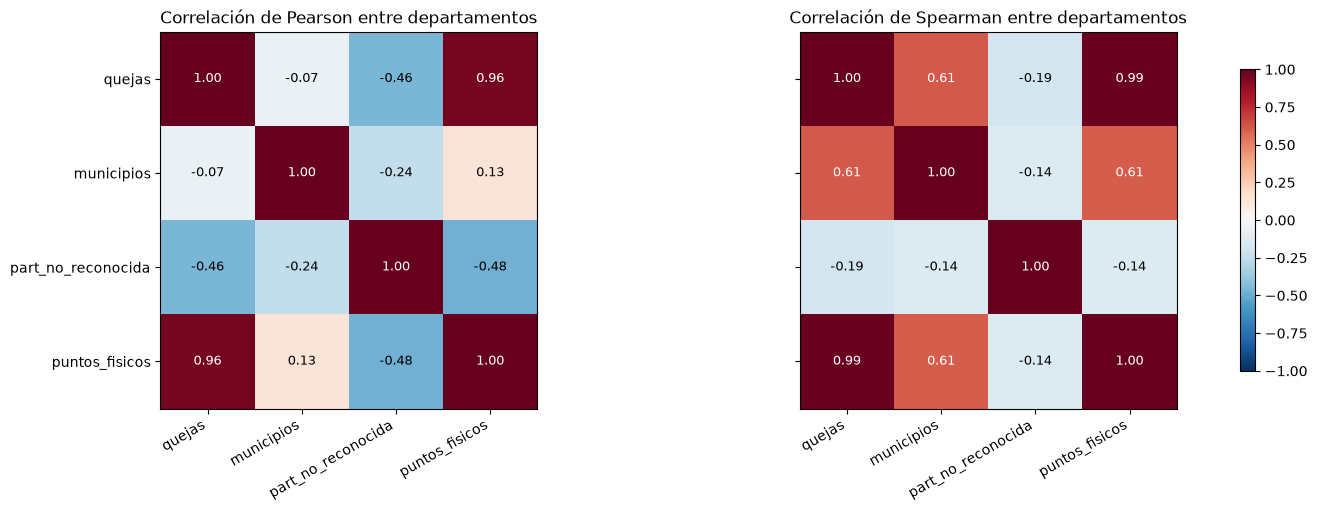

In [26]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
for eje, (titulo, matriz) in zip(ejes, [("Pearson", corr_pearson), ("Spearman", corr_spearman)]):
    imagen = eje.imshow(matriz, cmap="RdBu_r", vmin=-1, vmax=1)
    eje.set_xticks(range(len(matriz)), matriz.columns, rotation=30, ha="right")
    eje.set_yticks(range(len(matriz)), matriz.index if eje is ejes[0] else [])
    for i in range(len(matriz)):
        for j in range(len(matriz)):
            valor = matriz.iloc[i, j]
            eje.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=9,
                     color="white" if abs(valor) > 0.6 else "black")
    eje.set_title(f"Correlación de {titulo} entre departamentos")
    eje.grid(False)
fig.colorbar(imagen, ax=ejes, shrink=0.8)
plt.show()

### Notas sobre asociación

🤖 **Producto y desenlace (P1).** Entre 2010T2 y 2022T2, el 74,4 % de las quejas con desenlace se resolvió a favor del consumidor, pero la tasa cambia mucho según el producto. Entre los diez productos con más quejas finalizadas, Cuenta de ahorros tiene la tasa más alta (80,0 %), seguida de cuenta corriente (73,5 %), crédito de consumo y/o comercial (72,8 %) y tarjetas de crédito (70,6 %). En el otro extremo están pensión voluntaria (33,5 %), leasing (33,8 %) y fondos de valores y/o de inversión (43,0 %). La V de Cramér es 0,139, una asociación débil en el total, porque los productos de mayor volumen tienen tasas parecidas al promedio. Aun así, la diferencia entre productos justifica usar una tasa propia para cada producto en la vista minable, y no una tasa única.

**Producto y motivo.** Aquí la asociación es más fuerte (V de Cramér de 0,334): cada producto tiene su propio patrón de quejas. En Cuenta de ahorro (66,9 %) y en tarjetas de crédito (73,6 %) domina la transacción no reconocida. En créditos comerciales, el 52,5 % de las quejas es por revisión y/o liquidación del producto. En "Otros productos de Establecimientos de Crédito y SEDPE" pesan las fallas de los canales (22,4 %), y un 33,9 % de las quejas se reparte en motivos que no están entre los ocho principales. Los depósitos de bajo monto mezclan transacción no reconocida (29,5 %), inconsistencias en el movimiento y saldo (22,3 %) e inconsistencias en los pagos (16,3 %).

**Departamentos.** Las quejas y los puntos físicos están muy correlacionados: 0,958 con Pearson y 0,986 con Spearman. La relación se mantiene sin Bogotá (0,931 y 0,984), así que no depende de un solo departamento. Es la evidencia de que comparar departamentos por quejas absolutas mide sobre todo tamaño, y de que hace falta normalizar por puntos de atención (sección 4.2). En las otras dos variables, Pearson y Spearman no coinciden:
- **Municipios con quejas:** Pearson da −0,07 y Spearman 0,61. La diferencia viene de Bogotá, que es un solo municipio con 790.410 quejas. Sin Bogotá, Pearson sube a 0,67.
- **Participación de la transacción no reconocida:** Pearson da −0,46 y Spearman −0,19. Los dos departamentos con más quejas tienen las participaciones más bajas (Antioquia 39,5 %, Bogotá 48,9 %) frente a una mediana de 65,5 %, y eso arrastra a Pearson. Sin Bogotá sigue en −0,54, porque Antioquia también pesa. En rangos, la relación es débil.

**Covarianza.** Confirma el signo de cada relación, pero no sirve para comparar intensidades porque depende de las unidades. La covarianza entre quejas y puntos físicos supera los 21 millones, mientras que las de la participación de la transacción no reconocida son cercanas a cero aunque su correlación con las quejas sea −0,46: esa variable es una proporción entre 0 y 1. Por eso la comparación entre pares se hace con la correlación.

**Para las secciones siguientes.**
- **5.4:** Bogotá y Antioquia son puntos de alta influencia; los cálculos por departamento deben revisarse con y sin ellos.
- **6.2:** como la tasa a favor del consumidor varía entre 33 % y 80 % según el producto, homologar bien los productos cambia directamente la tasa que recibe cada fila de la vista.
- **6.3:** la correlación de 0,96 entre quejas y puntos físicos respalda la variable de quejas por cada 100 puntos de atención.
- **7:** el contraste entre productos (desenlace y motivo) es material para los gráficos de la P1.

### **5.4 Análisis de calidad**

🤖 Las secciones 3 a 5.3 fueron dejando problemas anotados; esta subsección los mide todos con el mismo criterio y agrega los que no se habían revisado. La calidad se revisa en cinco dimensiones: **completitud** (qué falta), **unicidad** (qué se repite), **validez** (qué valores son imposibles), **consistencia** (qué no cuadra entre columnas o entre fuentes) y **oportunidad** (qué tan al día está cada fuente). Para los datos faltantes se usan los tres mecanismos vistos en clase: MCAR, cuando faltan completamente al azar; MAR, cuando que falten depende de otra variable observada; y MNAR, cuando depende del propio valor que falta. Para los atípicos se usa la regla de Tukey (por debajo de Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR), pero un atípico no es un error por ser extremo: la P2 busca justamente los picos. La sección cierra con una tabla **problema → mecanismo → decisión**. Aquí no se corrige nada; la sección 6.1 aplica las decisiones.

In [27]:
GRANOS = {"quejas_ss": (quejas_ss, ["fecha", "tipo_entidad", "codigo_entidad", "instancia_recepcion", "producto",
                                    "motivo", "departamento", "municipio"], "cantidad_quejas_recibidas"),
          "quejas_sfc": (quejas_sfc, ["codigo_entidad", "fecha_corte", "nombre_unidad_captura", "codigo_producto",
                                      "codigo_motivo"], "quejas_recibidas"),
          "puntos": (puntos, ["fecha_corte", "codigo_canal", "codigo_municipio"], None),
          "sanciones": (sanciones, ["res_sancion", "multado"], None)}
chequeos = []
for fuente, (df, grano, peso) in GRANOS.items():
    for col in df.columns[df.isna().any()]:
        nulos = df[col].isna()
        chequeos.append({"fuente": fuente, "chequeo": f"nulos en {col}", "filas": nulos.sum(),
                         "quejas_afectadas": df.loc[nulos, peso].sum() if peso else None})
    chequeos.append({"fuente": fuente, "chequeo": "filas duplicadas completas", "filas": df.duplicated().sum()})
    chequeos.append({"fuente": fuente, "chequeo": "filas que repiten el grano", "filas": df.duplicated(grano).sum()})
print(f"{'─'*70}\nCompletitud y unicidad:")
tabla_chequeos = pd.DataFrame(chequeos)
display(tabla_chequeos.assign(quejas_afectadas=tabla_chequeos["quejas_afectadas"].map(lambda v: "—" if pd.isna(v) else f"{v:,.0f}")))

sin_depto = quejas_ss["departamento"].isna()
evidencia = (quejas_ss.assign(sin_depto=quejas_ss["cantidad_quejas_recibidas"].where(sin_depto, 0))
             .groupby("instancia_recepcion")[["sin_depto", "cantidad_quejas_recibidas"]].sum())
evidencia["part_sin_depto"] = (evidencia["sin_depto"] / evidencia["cantidad_quejas_recibidas"]).map("{:.1%}".format)
print(f"\n{'─'*70}\nQuejas sin departamento según instancia de recepción (evidencia del mecanismo):")
display(evidencia.sort_values("sin_depto", ascending=False))
print("Quejas sin departamento por año:", quejas_ss.loc[sin_depto].groupby(quejas_ss["fecha"].dt.year)["cantidad_quejas_recibidas"].sum().to_dict())

──────────────────────────────────────────────────────────────────────
Completitud y unicidad:


,fuente,chequeo,filas,quejas_afectadas
0,quejas_ss,nulos en departamento,1194,"17,457"
1,quejas_ss,nulos en municipio,1194,"17,457"
2,quejas_ss,filas duplicadas completas,0,—
3,quejas_ss,filas que repiten el grano,0,—
4,quejas_sfc,nulos en quejas_pendientes,1,0
5,quejas_sfc,filas duplicadas completas,0,—
6,quejas_sfc,filas que repiten el grano,0,—
7,puntos,filas duplicadas completas,0,—
8,puntos,filas que repiten el grano,0,—
9,sanciones,filas duplicadas completas,0,—



──────────────────────────────────────────────────────────────────────
Quejas sin departamento según instancia de recepción (evidencia del mecanismo):


,sin_depto,cantidad_quejas_recibidas,part_sin_depto
instancia_recepcion,,,
Entidad vigilada,16943,1104344,1.5%
Superintendencia Financiera de Colombia,486,76890,0.6%
Defensor del consumidor financiero,25,55916,0.0%
Otra (remisión por competencia),3,1648,0.2%


Quejas sin departamento por año: {2023: 2694, 2024: 5490, 2025: 4494, 2026: 4779}


In [28]:
f = quejas_sfc
con_desenlace = f["quejas_finalizad_favor_consum"] + f["quejas_finalizad_favor_entidad"]
REGLAS = {
    ("quejas_ss", "cantidad de quejas ≤ 0"): quejas_ss["cantidad_quejas_recibidas"] <= 0,
    ("quejas_ss", "mes fuera de 1 a 12"): ~quejas_ss["mes_creacion"].between(1, 12),
    ("quejas_sfc", "algún conteo negativo"): (f.select_dtypes("number") < 0).any(axis=1),
    ("quejas_sfc", "favor consumidor + favor entidad < finalizadas"): con_desenlace < f["quejas_finalizadas"],
    ("quejas_sfc", "favor consumidor + favor entidad > finalizadas"): con_desenlace > f["quejas_finalizadas"],
    ("quejas_sfc", "aceptadas + no aceptadas ≠ favor consumidor"):
        f["quejas_favor_consum_acep"] + f["quejas_favor_consum_noacep"] != f["quejas_finalizad_favor_consum"],
    ("puntos", "puntos activos > puntos totales"):
        puntos["cantidad_puntos_antecion_activos"] > puntos["cantidad_puntos_atencion"],
    ("puntos", "puntos ≤ 0"): puntos["cantidad_puntos_atencion"] <= 0,
    ("sanciones", "multa ≤ 0"): sanciones["valor"] <= 0,
    ("sanciones", "fecha fuera de 2013–2026"): ~sanciones["fecha_emitida"].between("2013-01-01", "2026-12-31"),
}
print(f"{'─'*70}\nValidez y consistencia interna:")
display(pd.DataFrame([{"fuente": fuente, "regla": regla, "filas_que_incumplen": int(falla.sum())}
                      for (fuente, regla), falla in REGLAS.items()]))

brecha = f["quejas_finalizadas"] - con_desenlace
print(f"Quejas finalizadas sin desenlace asignado: {brecha.sum():,} de {f['quejas_finalizadas'].sum():,} "
      f"({brecha.sum() / f['quejas_finalizadas'].sum():.2%}) en {(brecha > 0).sum():,} filas")
print("Filas con brecha por año:", f.loc[brecha > 0].groupby(f["fecha_corte"].dt.year).size().to_dict())

──────────────────────────────────────────────────────────────────────
Validez y consistencia interna:


,fuente,regla,filas_que_incumplen
0,quejas_ss,cantidad de quejas ≤ 0,0
1,quejas_ss,mes fuera de 1 a 12,0
2,quejas_sfc,algún conteo negativo,0
3,quejas_sfc,favor consumidor + favor entidad < finalizadas,1153
4,quejas_sfc,favor consumidor + favor entidad > finalizadas,0
5,quejas_sfc,aceptadas + no aceptadas ≠ favor consumidor,0
6,puntos,puntos activos > puntos totales,0
7,puntos,puntos ≤ 0,0
8,sanciones,multa ≤ 0,0
9,sanciones,fecha fuera de 2013–2026,0


Quejas finalizadas sin desenlace asignado: 2,684 de 1,342,444 (0.20%) en 1,153 filas
Filas con brecha por año: {2010: 11, 2011: 29, 2012: 42, 2013: 50, 2014: 73, 2015: 99, 2016: 128, 2017: 128, 2018: 101, 2019: 145, 2020: 140, 2021: 128, 2022: 79}


In [29]:
import re
clave = lambda texto: normalizar_nombre(re.sub(r"\(.*?\)", "", texto))
variantes = []
for fuente, df in [("quejas_ss", quejas_ss), ("quejas_sfc", quejas_sfc), ("puntos", puntos), ("sanciones", sanciones)]:
    for col in [c for c in df.columns if pd.api.types.is_string_dtype(df[c])]:
        valores = df[col].dropna()
        if col == "municipio":
            valores = df.loc[valores.index, "departamento"] + " / " + valores
        unicos = pd.Series(valores.unique())
        grupos = unicos.groupby(unicos.map(clave)).agg(list)
        for lista in grupos[grupos.map(len) > 1]:
            variantes.append({"fuente": fuente, "columna": col, "variantes": " | ".join(lista)})
print(f"{'─'*70}\nValores que coinciden al quitar tildes, mayúsculas, espacios y paréntesis:")
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(variantes))

identicas = (puntos["cantidad_puntos_atencion"] == puntos["cantidad_puntos_antecion_activos"]).all()
print(f"\n{'─'*70}\nRedundancia: puntos totales y puntos activos idénticos en todas las filas: {identicas}")
print("Variantes de nombre_entidad en puntos de atención por periodo:")
display(puntos.groupby("nombre_entidad")["fecha_corte"].agg(desde="min", hasta="max", cortes="nunique"))

prod_ss, prod_sfc = set(quejas_ss["producto"].map(clave)), set(quejas_sfc["producto"].map(clave))
print(f"Productos: {len(prod_ss)} en Smartsupervision y {len(prod_sfc)} en el histórico SFC; "
      f"coinciden tras normalizar: {len(prod_ss & prod_sfc)} → {sorted(prod_ss & prod_sfc)}")

──────────────────────────────────────────────────────────────────────
Valores que coinciden al quitar tildes, mayúsculas, espacios y paréntesis:


,fuente,columna,variantes
0,quejas_ss,motivo,NEGACIÓN INJUSTIFICADA A LA APERTURA DEL PRODUCTO | Negación injustificada a la apertura del producto
1,quejas_ss,producto,Fondos de inversión colectiva | Fondos de Inversión Colectiva (FIC)



──────────────────────────────────────────────────────────────────────
Redundancia: puntos totales y puntos activos idénticos en todas las filas: True
Variantes de nombre_entidad en puntos de atención por periodo:


,desde,hasta,cortes
nombre_entidad,,,
BANCO DAVIVIENDA,2023-01-31,2024-02-29,14
BANCO DAVIVIENDA S.A.,2024-03-31,2026-06-30,28


Productos: 33 en Smartsupervision y 31 en el histórico SFC; coinciden tras normalizar: 8 → ['ADMINISTRACION DE VALORES', 'CDT', 'CUENTA CORRIENTE', 'FIDUCIA DE ADMINISTRACION', 'FIDUCIA DE INVERSION', 'INTERMEDIACION DE VALORES', 'LEASING HABITACIONAL', 'TARJETAS DE CREDITO']


In [30]:
def tukey(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    return serie[(serie < q1 - 1.5 * (q3 - q1)) | (serie > q3 + 1.5 * (q3 - q1))]

meses_esperados = pd.date_range(quejas_mes.index.min(), quejas_mes.index.max(), freq="MS")
trim = quejas_sfc.groupby("trimestre")["quejas_recibidas"].sum()
bajos_mes = quejas_mes[quejas_mes < 0.5 * quejas_mes.rolling(6, min_periods=3).median().shift(1)]
bajos_trim = trim[trim < 0.5 * trim.rolling(4, min_periods=2).median().shift(1)]
print(f"{'─'*70}\nPeriodos incompletos (menos del 50 % de la mediana de los periodos anteriores):")
print(f"quejas_ss · meses faltantes: {[f'{m:%Y-%m}' for m in meses_esperados.difference(quejas_mes.index)]} · "
      f"meses bajos: {({f'{m:%Y-%m}': v for m, v in bajos_mes.items()})}")
print(f"quejas_sfc · trimestres bajos: {({str(t): v for t, v in bajos_trim.items()})}")

print(f"\n{'─'*70}\nAtípicos según la regla de Tukey:")
for nombre, serie in [("quejas por mes (nacional)", quejas_mes),
                      ("quejas por fila (quejas_ss)", quejas_ss["cantidad_quejas_recibidas"]),
                      ("valor de las multas (sanciones)", sanciones["valor"])]:
    atipicos = tukey(serie)
    print(f"{nombre}: {len(atipicos):,} de {len(serie):,} valores · {atipicos.sum() / serie.sum():.1%} del total")
print("Meses atípicos:", {f"{m:%Y-%m}": v for m, v in tukey(quejas_mes).items()})

descarga = pd.Timestamp(metadatos["fecha_descarga"])
print(f"\n{'─'*70}\nOportunidad (datos descargados el {descarga:%Y-%m-%d}):")
print(f"Último dato · quejas_ss: {quejas_ss['fecha'].max():%Y-%m} · puntos: {puntos['fecha_corte'].max():%Y-%m} · "
      f"sanciones: {sanciones['fecha_emitida'].max():%Y-%m-%d} · quejas_sfc: {quejas_sfc['trimestre'].max()}")

──────────────────────────────────────────────────────────────────────
Periodos incompletos (menos del 50 % de la mediana de los periodos anteriores):
quejas_ss · meses faltantes: ['2026-02'] · meses bajos: {'2026-10': 905}
quejas_sfc · trimestres bajos: {'2022Q3': 23, '2022Q4': 0}

──────────────────────────────────────────────────────────────────────
Atípicos según la regla de Tukey:
quejas por mes (nacional): 3 de 45 valores · 2.7% del total
quejas por fila (quejas_ss): 14,865 de 113,327 valores · 86.9% del total
valor de las multas (sanciones): 34 de 281 valores · 65.5% del total
Meses atípicos: {'2023-01': 15734, '2023-02': 16651, '2026-10': 905}

──────────────────────────────────────────────────────────────────────
Oportunidad (datos descargados el 2026-11-19):
Último dato · quejas_ss: 2026-10 · puntos: 2026-06 · sanciones: 2026-05-29 · quejas_sfc: 2022Q4


In [31]:
PROBLEMAS = [
    ("quejas_ss", "Departamento y municipio vacíos", "completitud", "MAR: depende de la instancia de recepción", "1.194 filas · 17.457 quejas (1,4 %); 1,5 % en entidad vigilada, 0,0 % en defensor", "Mantener en totales nacionales; excluir de los cálculos por departamento", "6.1"),
    ("quejas_ss", "Febrero de 2026 sin registros", "completitud", "Corte de la fuente", "1 mes faltante en 2023-01 a 2026-10", "Dejar como faltante, no imputar 0; excluir de las referencias de la P2", "6.1"),
    ("quejas_ss", "Octubre de 2026 incompleto", "oportunidad", "Corte de la fuente (mes en curso al descargar)", "905 quejas; atípico de Tukey", "Excluir de la vista minable", "6.1"),
    ("quejas_ss", "Enero y febrero de 2023 bajos", "consistencia", "Posible arranque del sistema (por confirmar)", "15.734 y 16.651 quejas; atípicos de Tukey", "Mantener y marcar como arranque; no usar como referencia (la 6.4 lo amplió hasta septiembre de 2023)", "6.3 · 6.4"),
    ("quejas_ss", "Motivo escrito de dos formas", "consistencia", "Error de captura", "1 motivo en mayúsculas y en tipo oración", "Unificar", "6.1"),
    ("quejas_ss", "Producto FIC con dos nombres", "consistencia", "Cambio de nombre en el catálogo", "«Fondos de Inversión Colectiva (FIC)» y «Fondos de inversión colectiva»", "Unificar", "6.2"),
    ("quejas_ss", "Concentración en Bogotá", "consistencia", "Fenómeno real o lugar de registro (por confirmar)", "63,8 % de las quejas; depósitos de bajo monto 12,6 % vs. 1,1 %", "Mantener; normalizar por puntos y revisar con y sin Bogotá", "6.3 · 8.2"),
    ("quejas_ss", "Registros con volumen extremo", "validez", "Fenómeno real", "Tukey marca 14.865 de 113.327 filas (86,9 % de las quejas)", "Mantener; aplicar Tukey sobre la serie agregada, no por fila", "6.4"),
    ("quejas_sfc", "2022T3 y 2022T4 sin quejas recibidas", "oportunidad", "Corte de la fuente (paso a Smartsupervision)", "23 y 0 quejas recibidas", "Excluir; serie útil 2010T2–2022T2", "6.1"),
    ("quejas_sfc", "Quejas finalizadas sin desenlace", "consistencia", "Error de captura (por confirmar)", "1.153 filas · 2.684 de 1.342.444 quejas (0,20 %)", "Calcular la tasa sobre favor consumidor + favor entidad", "6.3"),
    ("quejas_sfc", "Nulo en quejas_pendientes", "completitud", "MCAR probable: una sola fila", "1 fila con 0 quejas recibidas", "No requiere acción: la columna no se usa", "6.1"),
    ("quejas_sfc", "Posible doble conteo entidad / defensor", "unicidad", "No verificable con datos agregados", "El defensor recibe el 5,4 % de las quejas (4.1)", "Sumar ambas instancias y declarar el supuesto", "6.1 · 8.2"),
    ("quejas_sfc", "Catálogo de productos distinto", "consistencia", "Fuentes con catálogos distintos", "Solo 8 productos coinciden tras normalizar (33 vs. 31)", "Homologar", "6.2"),
    ("puntos", "Códigos de canal sin documentar", "validez", "Falta de metadatos en la fuente", "3 canales; 4 y 14 inferidos como físicos (4.2)", "Mantener la inferencia y declararla", "8.2"),
    ("puntos", "Puntos totales y activos idénticos", "unicidad", "Columna redundante (con error en el nombre)", "Iguales en todas las filas", "Eliminar la columna de activos", "6.1"),
    ("puntos", "nombre_entidad con dos escrituras", "consistencia", "Cambio de nombre en la fuente", "Hasta 2024-02 sin «S.A.», desde 2024-03 con «S.A.»", "Ignorar el nombre; filtrar por código de entidad", "6.1"),
    ("puntos", "Sin datos después de junio de 2026", "oportunidad", "Corte de la fuente", "Último corte 2026-06", "Usar el denominador fijo por departamento", "6.3"),
    ("puntos", "Departamentos sin puntos físicos", "completitud", "Fenómeno real", "6 departamentos · 632 quejas (0,05 %) (4.2)", "Dejar sin indicador normalizado", "6.3"),
    ("sanciones", "Radicados repetidos", "unicidad", "Fenómeno real: varias sanciones por expediente", "8 expedientes; res_sancion × multado sin repeticiones", "Contar por res_sancion × multado", "6.1"),
    ("sanciones", "Multas extremas", "validez", "Fenómeno real", "34 de 281 multas atípicas (65,5 % del valor)", "Mantener; la vista usa el conteo, no el valor", "6.3"),
    ("sanciones", "Posible rezago de publicación", "oportunidad", "Corte de la fuente (por confirmar)", "Última sanción 2026-05-29; descarga 2026-11-19", "Documentar que la ventana de 12 meses puede bajar al final", "8.2")]
print(f"{'─'*70}\nProblemas de calidad: problema → mecanismo → decisión ({len(PROBLEMAS)} problemas)")
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(PROBLEMAS, columns=["fuente", "problema", "dimension", "mecanismo", "magnitud", "decision_propuesta", "seccion"]))

──────────────────────────────────────────────────────────────────────
Problemas de calidad: problema → mecanismo → decisión (21 problemas)


,fuente,problema,dimension,mecanismo,magnitud,decision_propuesta,seccion
0,quejas_ss,Departamento y municipio vacíos,completitud,MAR: depende de la instancia de recepción,"1.194 filas · 17.457 quejas (1,4 %); 1,5 % en entidad vigilada, 0,0 % en defensor",Mantener en totales nacionales; excluir de los cálculos por departamento,6.1
1,quejas_ss,Febrero de 2026 sin registros,completitud,Corte de la fuente,1 mes faltante en 2023-01 a 2026-10,"Dejar como faltante, no imputar 0; excluir de las referencias de la P2",6.1
2,quejas_ss,Octubre de 2026 incompleto,oportunidad,Corte de la fuente (mes en curso al descargar),905 quejas; atípico de Tukey,Excluir de la vista minable,6.1
3,quejas_ss,Enero y febrero de 2023 bajos,consistencia,Posible arranque del sistema (por confirmar),15.734 y 16.651 quejas; atípicos de Tukey,Mantener y marcar como arranque; no usar como referencia (la 6.4 lo amplió hasta septiembre de 2023),6.3 · 6.4
4,quejas_ss,Motivo escrito de dos formas,consistencia,Error de captura,1 motivo en mayúsculas y en tipo oración,Unificar,6.1
5,quejas_ss,Producto FIC con dos nombres,consistencia,Cambio de nombre en el catálogo,«Fondos de Inversión Colectiva (FIC)» y «Fondos de inversión colectiva»,Unificar,6.2
6,quejas_ss,Concentración en Bogotá,consistencia,Fenómeno real o lugar de registro (por confirmar),"63,8 % de las quejas; depósitos de bajo monto 12,6 % vs. 1,1 %",Mantener; normalizar por puntos y revisar con y sin Bogotá,6.3 · 8.2
7,quejas_ss,Registros con volumen extremo,validez,Fenómeno real,"Tukey marca 14.865 de 113.327 filas (86,9 % de las quejas)","Mantener; aplicar Tukey sobre la serie agregada, no por fila",6.4
8,quejas_sfc,2022T3 y 2022T4 sin quejas recibidas,oportunidad,Corte de la fuente (paso a Smartsupervision),23 y 0 quejas recibidas,Excluir; serie útil 2010T2–2022T2,6.1
9,quejas_sfc,Quejas finalizadas sin desenlace,consistencia,Error de captura (por confirmar),"1.153 filas · 2.684 de 1.342.444 quejas (0,20 %)",Calcular la tasa sobre favor consumidor + favor entidad,6.3


### Notas sobre la calidad

🤖 **Lo que es error y lo que es fenómeno real.** Las fuentes no tienen duplicados, ni filas que repitan su grano, ni valores imposibles: ningún conteo es negativo, ningún mes está fuera de rango, ninguna multa es cero y los puntos activos nunca superan a los totales. La mayoría de los problemas son de **oportunidad**, es decir, cortes de la fuente: octubre de 2026 incompleto (905 quejas), febrero de 2026 ausente, 2022T3 y 2022T4 casi vacíos en el histórico de la SFC, puntos de atención hasta junio de 2026 y sanciones hasta mayo de 2026. Esos periodos se tratan como faltantes, no como caídas reales. En cambio, los atípicos de volumen se mantienen. La regla de Tukey aplicada a cada fila de Smartsupervision marca 14.865 registros que suman el 86,9 % de las quejas, lo que muestra que a ese nivel la regla no distingue nada: con mediana de 1 queja por fila, casi todo el volumen parece extremo. Por eso la detección de picos de la P2 se hará sobre la serie agregada (6.4). En la serie mensual nacional, Tukey marca solo tres meses: octubre de 2026, que es un error de corte, y enero y febrero de 2023 (15.734 y 16.651 quejas), que coinciden con el arranque del sistema y se marcan para no usarlos como referencia. La 6.4 mostró después que el arranque se extendió por más tiempo en varios departamentos, y el periodo se amplió hasta septiembre de 2023.

**Mecanismos de los faltantes.** Los 1.194 registros sin departamento ni municipio (17.457 quejas) no faltan al azar: el 1,5 % de las quejas recibidas por la entidad vigilada no tiene ubicación, frente al 0,6 % de las que llegan por la SFC y el 0,0 % de las del defensor. Que falte depende de una variable observada, la instancia, así que el mecanismo es **MAR**. Además aparecen en todos los años (2.694 en 2023 y entre 4.494 y 5.490 en los siguientes). Excluirlos de los cálculos por departamento no sesga la comparación entre departamentos, pero sí subestima un poco los totales regionales, y por eso se mantienen en los totales nacionales. El único nulo del histórico de la SFC está en una fila sin quejas recibidas y en una columna que no se usa.

**Decisiones que cambian los resultados.**
- **P1:** en 1.153 filas del histórico, las quejas a favor del consumidor más las a favor de la entidad no llegan al total de finalizadas. Son solo 2.684 quejas (0,20 %), pero definen el denominador: la tasa se calcula sobre las quejas con desenlace asignado, como ya se hizo en la 5.3. La homologación de productos sigue siendo la decisión que más pesa: solo 8 productos coinciden por nombre entre las dos fuentes.
- **P2:** excluir octubre de 2026, no rellenar febrero de 2026 con cero y no usar el periodo de arranque como referencia (enero y febrero de 2023, ampliado después hasta septiembre en la 6.4) evita alertas falsas. La concentración en Bogotá se mantiene, pero los resultados por departamento se revisan con y sin Bogotá.
- **Limpieza menor (6.1):** unificar el motivo escrito de dos formas y el producto FIC con dos nombres, y eliminar la columna de puntos activos, que es idéntica a la de puntos totales en todas las filas.

**Lo que queda como limitación (8.2).** Sin datos individuales no se puede verificar si una misma queja aparece en la entidad vigilada y en el defensor. Tampoco se puede confirmar qué significa cada código de canal, ni si la concentración en Bogotá refleja dónde viven los clientes o dónde se registran las quejas. Las sanciones de los últimos meses pueden estar incompletas por rezago de publicación.

---
## **6. Preparación de los datos**

🤖 Responde al punto 5 del reporte: variables derivadas y transformaciones. La preparación sigue un orden fijo, en el que cada paso parte del anterior: **6.1** aplica la limpieza que decidió la sección 5.4; **6.2** homologa productos y motivos entre las dos fuentes de quejas; **6.3** construye las variables derivadas; **6.4** aplica las técnicas del curso (regla de Tukey, winsorización, transformaciones y discretización); y **6.5** arma y exporta la vista minable con los cruces diseñados en la 4.4. Los datos originales no se sobrescriben: cada paso trabaja sobre copias, de modo que siempre se puede comparar el antes y el después.

### **6.1 Limpieza aplicada**

🤖 Esta subsección aplica solo las decisiones que la tabla de problemas de la 5.4 asignó a la 6.1, sobre copias con el sufijo `_limpio`. Cada decisión queda en una bitácora con las filas y las quejas antes y después, y al final unas verificaciones comprueban que la limpieza hizo lo que dice. Lo demás se resuelve más adelante: la homologación de productos (incluido el producto FIC con dos nombres) en la 6.2; la tasa sobre quejas con desenlace y el denominador de puntos en la 6.3; la marca del periodo de arranque y la regla de Tukey en la 6.4; y el filtro de Banco Davivienda y del periodo de la vista en la 6.5. Por eso las copias limpias conservan las tres entidades del grupo: el histórico de la SFC las necesita para la P1.

In [32]:
bitacora_limpieza = []
def registrar(fuente, decision, antes, despues, quejas_antes=None, quejas_despues=None):
    bitacora_limpieza.append({"fuente": fuente, "decision": decision, "filas_antes": antes, "filas_despues": despues,
                              "quejas_antes": quejas_antes, "quejas_despues": quejas_despues})
q_ss = lambda df: df["cantidad_quejas_recibidas"].sum()

ss_limpio = quejas_ss.copy()
filas, quejas = len(ss_limpio), q_ss(ss_limpio)
ss_limpio = ss_limpio[ss_limpio["fecha"] != "2026-10-01"].copy()
registrar("quejas_ss", "Excluir octubre de 2026 (mes incompleto)", filas, len(ss_limpio), quejas, q_ss(ss_limpio))

ss_limpio["sin_ubicacion"] = ss_limpio["departamento"].isna()
registrar("quejas_ss", f"Marcar sin_ubicacion en {ss_limpio['sin_ubicacion'].sum():,} filas, sin eliminarlas",
          len(ss_limpio), len(ss_limpio), q_ss(ss_limpio), q_ss(ss_limpio))

peso_escritura = ss_limpio.groupby("motivo")["cantidad_quejas_recibidas"].sum()
forma_canonica = peso_escritura.groupby(peso_escritura.index.map(normalizar_nombre)).idxmax()
motivo_unificado = ss_limpio["motivo"].map(normalizar_nombre).map(forma_canonica)
reescritas, motivos_antes = (motivo_unificado != ss_limpio["motivo"]).sum(), ss_limpio["motivo"].nunique()
ss_limpio["motivo"] = motivo_unificado
registrar("quejas_ss", f"Unificar escrituras de motivo: {motivos_antes} → {ss_limpio['motivo'].nunique()} motivos, "
          f"{reescritas} filas reescritas", len(ss_limpio), len(ss_limpio), q_ss(ss_limpio), q_ss(ss_limpio))
registrar("quejas_ss", "Febrero de 2026 queda sin filas: no se rellena con cero",
          len(ss_limpio), len(ss_limpio), q_ss(ss_limpio), q_ss(ss_limpio))
print(f"{'─'*70}\nss_limpio: {len(ss_limpio):,} filas · {q_ss(ss_limpio):,} quejas")

──────────────────────────────────────────────────────────────────────
ss_limpio: 113,033 filas · 1,237,893 quejas


In [33]:
sfc_limpio = quejas_sfc[quejas_sfc["trimestre"] <= pd.Period("2022Q2")].copy()
registrar("quejas_sfc", "Restringir a la serie útil 2010T2–2022T2 (excluye 2022T3 y 2022T4)",
          len(quejas_sfc), len(sfc_limpio), quejas_sfc["quejas_recibidas"].sum(), sfc_limpio["quejas_recibidas"].sum())
registrar("quejas_sfc", f"Nulos en quejas_pendientes: {sfc_limpio['quejas_pendientes'].isna().sum()} tras el corte; "
          "sin acción, la columna no se usa", len(sfc_limpio), len(sfc_limpio),
          sfc_limpio["quejas_recibidas"].sum(), sfc_limpio["quejas_recibidas"].sum())

puntos_limpio = puntos.drop(columns="cantidad_puntos_antecion_activos")
registrar("puntos", "Eliminar cantidad_puntos_antecion_activos (idéntica a cantidad_puntos_atencion)",
          len(puntos), len(puntos_limpio))
nombre_actual = puntos_limpio.sort_values("fecha_corte")["nombre_entidad"].iloc[-1]
filas_renombradas = (puntos_limpio["nombre_entidad"] != nombre_actual).sum()
puntos_limpio["nombre_entidad"] = nombre_actual
registrar("puntos", f"Unificar nombre_entidad como «{nombre_actual}» ({filas_renombradas:,} filas reescritas)",
          len(puntos_limpio), len(puntos_limpio))

sanciones_limpio = sanciones.copy()
registrar("sanciones", "Sin cambios: los radicados repetidos son sanciones distintas; la llave es res_sancion × multado",
          len(sanciones), len(sanciones_limpio))
print(f"{'─'*70}\nsfc_limpio: {len(sfc_limpio):,} filas · puntos_limpio: {len(puntos_limpio):,} filas · "
      f"sanciones_limpio: {len(sanciones_limpio):,} filas")

──────────────────────────────────────────────────────────────────────
sfc_limpio: 9,795 filas · puntos_limpio: 60,998 filas · sanciones_limpio: 281 filas


In [34]:
formato = lambda v: "—" if v is None or pd.isna(v) else f"{v:,.0f}"
tabla_bitacora = pd.DataFrame(bitacora_limpieza)
for col in ["quejas_antes", "quejas_despues"]:
    tabla_bitacora[col] = tabla_bitacora[col].map(formato)
print(f"{'─'*70}\nBitácora de limpieza ({len(tabla_bitacora)} decisiones):")
with pd.option_context("display.max_colwidth", None):
    display(tabla_bitacora)

resumen = []
for fuente, original, limpio, peso in [("quejas_ss", quejas_ss, ss_limpio, "cantidad_quejas_recibidas"),
                                       ("quejas_sfc", quejas_sfc, sfc_limpio, "quejas_recibidas"),
                                       ("puntos", puntos, puntos_limpio, None),
                                       ("sanciones", sanciones, sanciones_limpio, None)]:
    resumen.append({"fuente": fuente, "filas_original": len(original), "filas_limpio": len(limpio),
                    "columnas_original": original.shape[1], "columnas_limpio": limpio.shape[1],
                    "quejas_original": formato(original[peso].sum()) if peso else "—",
                    "quejas_limpio": formato(limpio[peso].sum()) if peso else "—"})
print(f"\n{'─'*70}\nResumen antes / después por fuente:")
display(pd.DataFrame(resumen).set_index("fuente"))

──────────────────────────────────────────────────────────────────────
Bitácora de limpieza (9 decisiones):


,fuente,decision,filas_antes,filas_despues,quejas_antes,quejas_despues
0,quejas_ss,Excluir octubre de 2026 (mes incompleto),113327,113033,"1,238,798","1,237,893"
1,quejas_ss,"Marcar sin_ubicacion en 1,191 filas, sin eliminarlas",113033,113033,"1,237,893","1,237,893"
2,quejas_ss,"Unificar escrituras de motivo: 111 → 110 motivos, 1 filas reescritas",113033,113033,"1,237,893","1,237,893"
3,quejas_ss,Febrero de 2026 queda sin filas: no se rellena con cero,113033,113033,"1,237,893","1,237,893"
4,quejas_sfc,Restringir a la serie útil 2010T2–2022T2 (excluye 2022T3 y 2022T4),9953,9795,"1,340,069","1,340,046"
5,quejas_sfc,"Nulos en quejas_pendientes: 0 tras el corte; sin acción, la columna no se usa",9795,9795,"1,340,046","1,340,046"
6,puntos,Eliminar cantidad_puntos_antecion_activos (idéntica a cantidad_puntos_atencion),60998,60998,—,—
7,puntos,"Unificar nombre_entidad como «BANCO DAVIVIENDA S.A.» (20,320 filas reescritas)",60998,60998,—,—
8,sanciones,Sin cambios: los radicados repetidos son sanciones distintas; la llave es res_sancion × multado,281,281,—,—



──────────────────────────────────────────────────────────────────────
Resumen antes / después por fuente:


,filas_original,filas_limpio,columnas_original,columnas_limpio,quejas_original,quejas_limpio
fuente,,,,,,
quejas_ss,113327,113033,11,12,"1,238,798","1,237,893"
quejas_sfc,9953,9795,19,19,"1,340,069","1,340,046"
puntos,60998,60998,11,10,—,—
sanciones,281,281,7,7,—,—


In [35]:
originales = [("quejas_smartsupervision", quejas_ss), ("quejas_sfc", quejas_sfc),
              ("puntos_atencion", puntos), ("sanciones_sic", sanciones)]
VERIFICACIONES = {
    "No queda octubre de 2026 en ss_limpio": (ss_limpio["fecha"] == "2026-10-01").sum() == 0,
    "Febrero de 2026 sigue sin filas (no se rellenó)": (ss_limpio["fecha"] == "2026-02-01").sum() == 0,
    "sin_ubicacion coincide con departamento vacío": ss_limpio["sin_ubicacion"].equals(ss_limpio["departamento"].isna()),
    "motivo sin variantes tras normalizar":
        ss_limpio["motivo"].nunique() == ss_limpio["motivo"].map(normalizar_nombre).nunique(),
    "sfc_limpio termina en 2022T2": sfc_limpio["trimestre"].max() == pd.Period("2022Q2"),
    "puntos_limpio sin la columna de activos": "cantidad_puntos_antecion_activos" not in puntos_limpio.columns,
    "nombre_entidad con un solo valor": puntos_limpio["nombre_entidad"].nunique() == 1,
    "sanciones_limpio igual a sanciones": sanciones_limpio.equals(sanciones),
    "Originales con el tamaño registrado en metadatos":
        all(len(df) == metadatos["datasets"][n]["cantidad_registros"] for n, df in originales),
}
print(f"{'─'*70}\nVerificaciones de la limpieza:")
for nombre, cumple in VERIFICACIONES.items():
    assert cumple, f"Falla: {nombre}"
    print(f"✓ {nombre}")

──────────────────────────────────────────────────────────────────────
Verificaciones de la limpieza:
✓ No queda octubre de 2026 en ss_limpio
✓ Febrero de 2026 sigue sin filas (no se rellenó)
✓ sin_ubicacion coincide con departamento vacío
✓ motivo sin variantes tras normalizar
✓ sfc_limpio termina en 2022T2
✓ puntos_limpio sin la columna de activos
✓ nombre_entidad con un solo valor
✓ sanciones_limpio igual a sanciones
✓ Originales con el tamaño registrado en metadatos


### Notas sobre la limpieza

🤖 **Qué cambió.** La bitácora registra nueve decisiones.
- **Smartsupervision:** salir de octubre de 2026 quita 294 filas y 905 quejas, y deja 113.033 filas con 1.237.893 quejas. La unificación de escrituras de `motivo` reescribe una sola fila y deja 110 motivos en lugar de 111.
- **Histórico de la SFC:** el corte a 2010T2–2022T2 quita 158 filas pero solo 23 quejas recibidas (de 1.340.069 a 1.340.046), porque 2022T3 y 2022T4 casi no tenían quejas nuevas. El único nulo de `quejas_pendientes` estaba en esos trimestres, así que desaparece con el corte.
- **Puntos de atención:** se elimina la columna de puntos activos, idéntica a la de puntos totales, y se unifica `nombre_entidad` como «BANCO DAVIVIENDA S.A.», lo que reescribe 20.320 filas del periodo anterior a marzo de 2024.

**Qué se mantuvo a propósito.**
- **Registros sin ubicación:** no se eliminan; se marcan con `sin_ubicacion`. Son 1.191 y no 1.194 como en la 5.4, porque 3 eran de octubre de 2026, que ya salió. Siguen contando en los totales nacionales y se excluirán solo de los cálculos por departamento.
- **Febrero de 2026:** queda sin filas. Rellenarlo con cero haría ver un desplome que no ocurrió.
- **Atípicos de volumen:** no se tocan, porque son lo que busca la P2.
- **Sanciones:** quedan iguales, porque sus radicados repetidos son sanciones distintas.
- **Las tres entidades del grupo:** se conservan, porque el histórico de la SFC las necesita para la P1. El filtro de Banco Davivienda se aplica en la 6.5.

**Qué sigue.**
- **6.2:** la homologación de productos, incluido el producto FIC con dos nombres, y la de motivos entre las dos fuentes.
- **6.3:** la tasa sobre quejas con desenlace asignado, el denominador fijo de puntos físicos y el tratamiento de los departamentos sin puntos.
- **6.3 y 6.4:** la marca del periodo de arranque y la regla de Tukey sobre la serie agregada. La 5.4 detectó enero y febrero de 2023 como arranque; la 6.4 lo amplió hasta septiembre de 2023.

### **6.2 Homologación de producto y motivo**

🤖 Smartsupervision y el histórico de la SFC nombran los productos y los motivos con catálogos distintos. En la 4.4, comparando nombres idénticos, solo el 34,7 % de las quejas de la vista encontraba pareja. Homologar es asignar cada valor de las dos fuentes a una **categoría común**, escrita a mano y justificada, en lugar de esperar que los nombres coincidan. Las dos homologaciones cumplen papeles distintos:
- **`eq_producto`** es la llave de la vista minable: permite llevar la tasa histórica de quejas a favor del consumidor de cada producto a las quejas de 2023 a 2026.
- **`eq_motivo`** no entra a la vista, pero permite comparar la composición de las quejas entre 2010–2022 y 2023–2026 para la P1.

Cada asignación de producto se clasifica como **directa** (el mismo producto con otro nombre), **conceptual** (el producto cae dentro de una categoría más amplia de la otra fuente) o **sin equivalente** (la otra fuente no tiene la categoría). Lo que no tiene equivalente recibe la tasa general del banco y se declara como supuesto.

In [36]:
llave = lambda texto: " ".join(normalizar_nombre(texto).split())
INVERSION_SS = ["Fondos de Inversión Colectiva (FIC)", "Fondos de inversión colectiva", "Fiducia de administración",
                "Fiducia de inversión", "Fiducia en garantía", "Fiducia inmobiliaria", "Negocios fiduciarios con entidades públicas",
                "Fiducia con recursos del sistema general de seguridad social y otros relacionados",
                "Otros productos de Fiduciarias", "Administración de portafolio de terceros", "Administración de valores",
                "Colocación de valores", "Custodia de Valores",
                "Intermediación de valores (renta variable, renta fija, derivados y apalancamiento)",
                "Otros productos de Sociedades Comisionistas de Bolsa de Valores y Agropecuaria"]
INVERSION_SFC = ["FONDOS DE VALORES Y/O DE INVERSIÓN", "FONDOS COMUNES ORDINARIOS Y ESPECIALES (FCO Y FCE)",
                 "FIDUCIA DE ADMINISTRACIÓN", "FIDUCIA DE INVERSIÓN", "FIDUCIA DE GARANTÍA",
                 "FIDUCIA ADMÓN. INMOBILIARIA PROYECTOS DE CONSTRUCCIÓN", "OTROS NEGOCIOS FIDUCIARIOS",
                 "ADMINISTRACIÓN OTROS FONDOS (MUTUOS, PORTAFOLIOS DE TERCEROS Y/O DE CAPITAL EXTRANJERO)",
                 "ADMINISTRACIÓN DE VALORES", "INTERMEDIACIÓN DE VALORES", "ACCIONES", "CONTRATO DE COMISIÓN",
                 "OTROS VALORES INSCRITOS EN EL REGISTRO (BONOS, PAPELES COMERCIALES, ETC)"]
# (categoría homologada, fuente, tipo de equivalencia, justificación, productos originales)
EQUIVALENCIAS = [
    ("Cuenta de ahorros", "quejas_ss", "directa", "Mismo producto; solo cambia singular y plural", ["Cuenta de ahorro"]),
    ("Cuenta de ahorros", "quejas_ss", "conceptual", "La cuenta AFC es una cuenta de ahorro con destinación específica", ["Cuenta AFC"]),
    ("Cuenta de ahorros", "quejas_sfc", "directa", "Mismo producto", ["CUENTA DE AHORROS"]),
    ("Tarjeta de crédito", "quejas_ss", "directa", "Mismo producto", ["Tarjetas de crédito"]),
    ("Tarjeta de crédito", "quejas_sfc", "directa", "Mismo producto", ["TARJETAS DE CRÉDITO"]),
    ("Crédito de consumo y comercial", "quejas_ss", "conceptual", "El histórico agrupaba consumo, comercial y microcrédito",
     ["Créditos comerciales", "Creditos de consumo", "Créditos de consumo de bajo monto", "Microcrédito"]),
    ("Crédito de consumo y comercial", "quejas_sfc", "directa", "Categoría de referencia", ["CRÉDITO DE CONSUMO Y/O COMERCIAL"]),
    ("Crédito de consumo y comercial", "quejas_sfc", "conceptual", "Crédito de bajo monto; volumen marginal", ["MICROCRÉDITOS"]),
    ("Crédito de vivienda", "quejas_ss", "directa", "Mismo producto", ["Créditos de vivienda"]),
    ("Crédito de vivienda", "quejas_sfc", "directa", "Mismo producto", ["CRÉDITO DE VIVIENDA"]),
    ("Leasing habitacional", "quejas_ss", "directa", "Mismo producto", ["Leasing habitacional"]),
    ("Leasing habitacional", "quejas_sfc", "directa", "Mismo producto", ["LEASING HABITACIONAL"]),
    ("Leasing no habitacional", "quejas_ss", "directa", "El histórico llamaba LEASING al no habitacional",
     ["Leasing financiero diferente de habitacional"]),
    ("Leasing no habitacional", "quejas_sfc", "directa", "Leasing distinto del habitacional", ["LEASING"]),
    ("Cuenta corriente", "quejas_ss", "directa", "Mismo producto", ["Cuenta corriente"]),
    ("Cuenta corriente", "quejas_sfc", "directa", "Mismo producto", ["CUENTA CORRIENTE"]),
    ("CDT y CDAT", "quejas_ss", "directa", "Mismo producto", ["CDT"]),
    ("CDT y CDAT", "quejas_sfc", "directa", "Mismo producto", ["CDT"]),
    ("CDT y CDAT", "quejas_sfc", "conceptual", "Depósito a término de corto plazo", ["CDAT"]),
    ("Depósitos de bajo monto y ordinarios", "quejas_ss", "sin equivalente",
     "Depósitos del Título 15 del Decreto 2555 de 2010; el histórico no tiene esta categoría",
     ["Depósitos de bajo monto (Capítulo I del Título 15 del Decreto 2555 de 2010)",
      "Depósitos de bajo monto inclusivos (Capítulo I del Título 15 del Decreto 2555 de 2010)",
      "Depósitos ordinarios (Capítulo II del Título 15 del Decreto 2555 de 2010)"]),
    ("Otros productos bancarios", "quejas_ss", "sin equivalente", "Categoría residual sin desagregar en Smartsupervision",
     ["Otros productos de Establecimientos de Crédito y SEDPE"]),
    ("Giros, divisas y corresponsales", "quejas_ss", "conceptual", "Servicio prestado a través de corresponsales", ["Corresponsalía"]),
    ("Giros, divisas y corresponsales", "quejas_sfc", "conceptual", "Servicios transaccionales distintos de cuentas y créditos",
     ["GIROS ESTABLECIMIENTOS DE CRÉDITO", "INTERMEDIACIÓN DE MERCADO CAMBIARIO (GIROS, COMPRAVENTA DE DIVISAS)",
      "SERVICIOS DE CORRESPONSALES NO BANCARIOS (CNB)", "CONTRATO DE CORRESPONSALÍA"]),
    ("Inversión, fiducia y valores", "quejas_ss", "conceptual", "Productos de fiduciaria y comisionista; incluye los dos nombres de FIC", INVERSION_SS),
    ("Inversión, fiducia y valores", "quejas_sfc", "conceptual", "Productos de fiduciaria y comisionista", INVERSION_SFC),
    ("Pensión voluntaria", "quejas_ss", "directa", "Mismo producto", ["Fondos de Pensiones Voluntarias"]),
    ("Pensión voluntaria", "quejas_sfc", "directa", "Mismo producto", ["PENSIÓN VOLUNTARIA"]),
    ("Pensión voluntaria", "quejas_sfc", "conceptual", "Producto pensional; volumen marginal", ["PENSIÓN DE VEJEZ"]),
    ("Seguros", "quejas_ss", "conceptual", "Categoría residual de seguros", ["Otros productos de seguros"]),
    ("Seguros", "quejas_sfc", "conceptual", "Seguros vendidos por el grupo", ["OTROS SEGUROS", "SEGURO DE VIDA INDIVIDUAL"]),
]
eq_producto = pd.DataFrame([{"fuente": fuente, "producto_original": producto, "producto_homologado": categoria,
                             "tipo_equivalencia": tipo, "justificacion": justificacion}
                            for categoria, fuente, tipo, justificacion, productos in EQUIVALENCIAS for producto in productos])
for fuente, df in [("quejas_ss", ss_limpio), ("quejas_sfc", sfc_limpio)]:
    faltan = set(df["producto"].map(llave)) - set(eq_producto.loc[eq_producto["fuente"] == fuente, "producto_original"].map(llave))
    assert not faltan, f"{fuente}: productos sin asignar {faltan}"

print(f"{'─'*70}\neq_producto: {len(eq_producto)} productos originales en {eq_producto['producto_homologado'].nunique()} categorías")
display(eq_producto.groupby(["fuente", "tipo_equivalencia"]).size().unstack(fill_value=0))
with pd.option_context("display.max_colwidth", None, "display.max_rows", 100):
    display(eq_producto)

──────────────────────────────────────────────────────────────────────
eq_producto: 65 productos originales en 14 categorías


tipo_equivalencia,conceptual,directa,sin equivalente
fuente,,,
quejas_sfc,22,9,0
quejas_ss,22,8,4


,fuente,producto_original,producto_homologado,tipo_equivalencia,justificacion
0,quejas_ss,Cuenta de ahorro,Cuenta de ahorros,directa,Mismo producto; solo cambia singular y plural
1,quejas_ss,Cuenta AFC,Cuenta de ahorros,conceptual,La cuenta AFC es una cuenta de ahorro con destinación específica
2,quejas_sfc,CUENTA DE AHORROS,Cuenta de ahorros,directa,Mismo producto
3,quejas_ss,Tarjetas de crédito,Tarjeta de crédito,directa,Mismo producto
4,quejas_sfc,TARJETAS DE CRÉDITO,Tarjeta de crédito,directa,Mismo producto
5,quejas_ss,Créditos comerciales,Crédito de consumo y comercial,conceptual,"El histórico agrupaba consumo, comercial y microcrédito"
6,quejas_ss,Creditos de consumo,Crédito de consumo y comercial,conceptual,"El histórico agrupaba consumo, comercial y microcrédito"
7,quejas_ss,Créditos de consumo de bajo monto,Crédito de consumo y comercial,conceptual,"El histórico agrupaba consumo, comercial y microcrédito"
8,quejas_ss,Microcrédito,Crédito de consumo y comercial,conceptual,"El histórico agrupaba consumo, comercial y microcrédito"
9,quejas_sfc,CRÉDITO DE CONSUMO Y/O COMERCIAL,Crédito de consumo y comercial,directa,Categoría de referencia


In [37]:
mapa_producto = lambda fuente: (eq_producto[eq_producto["fuente"] == fuente]
                                .assign(llave=lambda d: d["producto_original"].map(llave))
                                .set_index("llave")["producto_homologado"])

referencia = sfc_limpio[(sfc_limpio["codigo_entidad"] == 39) & (sfc_limpio["trimestre"] >= pd.Period("2019Q1"))]
referencia = referencia.assign(producto_homologado=referencia["producto"].map(llave).map(mapa_producto("quejas_sfc")))
tasas_ref = (referencia.groupby("producto_homologado")[["quejas_finalizad_favor_consum", "quejas_finalizad_favor_entidad"]].sum()
             .set_axis(["favor_consumidor", "favor_entidad"], axis=1))
tasas_ref["con_desenlace"] = tasas_ref["favor_consumidor"] + tasas_ref["favor_entidad"]
tasas_ref["tasa_propia"] = tasas_ref["favor_consumidor"] / tasas_ref["con_desenlace"]

VOLUMEN_MINIMO = 1_000
TASA_GENERAL = tasas_ref["favor_consumidor"].sum() / tasas_ref["con_desenlace"].sum()
tasas_ref["origen_tasa"] = np.where(tasas_ref["con_desenlace"] >= VOLUMEN_MINIMO, "propia", "general (volumen bajo)")
tasas_ref["tasa_referencia"] = np.where(tasas_ref["origen_tasa"] == "propia", tasas_ref["tasa_propia"], TASA_GENERAL)

print(f"{'─'*70}\nTasa de referencia por categoría · Banco Davivienda, 2019T1–2022T2, sobre quejas con desenlace")
display(tasas_ref.sort_values("con_desenlace", ascending=False)
        .assign(tasa_propia=lambda d: d["tasa_propia"].map("{:.1%}".format),
                tasa_referencia=lambda d: d["tasa_referencia"].map("{:.1%}".format)))
print(f"Tasa general del banco: {TASA_GENERAL:.1%} · volumen mínimo para tasa propia: {VOLUMEN_MINIMO:,} quejas con desenlace")

──────────────────────────────────────────────────────────────────────
Tasa de referencia por categoría · Banco Davivienda, 2019T1–2022T2, sobre quejas con desenlace


,favor_consumidor,favor_entidad,con_desenlace,tasa_propia,origen_tasa,tasa_referencia
producto_homologado,,,,,,
Cuenta de ahorros,267261,62460,329721,81.1%,propia,81.1%
Tarjeta de crédito,196337,68803,265140,74.1%,propia,74.1%
Crédito de consumo y comercial,60396,17877,78273,77.2%,propia,77.2%
Cuenta corriente,12140,4404,16544,73.4%,propia,73.4%
Crédito de vivienda,10952,3900,14852,73.7%,propia,73.7%
"Giros, divisas y corresponsales",3337,815,4152,80.4%,propia,80.4%
Leasing habitacional,2368,1460,3828,61.9%,propia,61.9%
CDT y CDAT,1020,437,1457,70.0%,propia,70.0%
Leasing no habitacional,547,707,1254,43.6%,propia,43.6%


Tasa general del banco: 77.5% · volumen mínimo para tasa propia: 1,000 quejas con desenlace


In [38]:
filas_ss, filas_sfc = len(ss_limpio), len(sfc_limpio)
ss_limpio["producto_homologado"] = ss_limpio["producto"].map(llave).map(mapa_producto("quejas_ss"))
sfc_limpio["producto_homologado"] = sfc_limpio["producto"].map(llave).map(mapa_producto("quejas_sfc"))
assert len(ss_limpio) == filas_ss and ss_limpio["producto_homologado"].notna().all()
assert len(sfc_limpio) == filas_sfc and sfc_limpio["producto_homologado"].notna().all()
registrar("quejas_ss", f"Agregar producto_homologado: {ss_limpio['producto'].nunique()} productos → "
          f"{ss_limpio['producto_homologado'].nunique()} categorías", filas_ss, len(ss_limpio))
registrar("quejas_sfc", f"Agregar producto_homologado: {sfc_limpio['producto'].nunique()} productos → "
          f"{sfc_limpio['producto_homologado'].nunique()} categorías", filas_sfc, len(sfc_limpio))

alcance = ss_limpio[(ss_limpio["codigo_entidad"] == 39) & (ss_limpio["fecha"] <= "2026-09-01")]
cobertura = alcance.groupby("producto_homologado")["cantidad_quejas_recibidas"].sum().to_frame("quejas")
cobertura["participacion"] = cobertura["quejas"] / cobertura["quejas"].sum()
cobertura["origen_tasa"] = cobertura.index.map(tasas_ref["origen_tasa"]).fillna("general (sin equivalente)")
cobertura["tasa_referencia"] = cobertura.index.map(tasas_ref["tasa_referencia"]).fillna(TASA_GENERAL)

print(f"{'─'*70}\nCobertura en el alcance de la vista · Banco Davivienda, 2023-01 a 2026-09 ({cobertura['quejas'].sum():,} quejas)")
display(cobertura.sort_values("quejas", ascending=False)
        .assign(participacion=lambda d: d["participacion"].map("{:.1%}".format),
                tasa_referencia=lambda d: d["tasa_referencia"].map("{:.1%}".format)))
por_origen = cobertura.groupby("origen_tasa")["participacion"].sum()
print("Quejas según el origen de su tasa:", {k: f"{v:.1%}" for k, v in por_origen.items()},
      "· con nombres idénticos (4.4): 34.7%")

──────────────────────────────────────────────────────────────────────
Cobertura en el alcance de la vista · Banco Davivienda, 2023-01 a 2026-09 (1,231,059 quejas)


,quejas,participacion,origen_tasa,tasa_referencia
producto_homologado,,,,
Cuenta de ahorros,445414,36.2%,propia,81.1%
Tarjeta de crédito,403965,32.8%,propia,74.1%
Otros productos bancarios,174482,14.2%,general (sin equivalente),77.5%
Depósitos de bajo monto y ordinarios,135984,11.0%,general (sin equivalente),77.5%
Crédito de consumo y comercial,36262,2.9%,propia,77.2%
Cuenta corriente,11739,1.0%,propia,73.4%
Crédito de vivienda,11318,0.9%,propia,73.7%
Leasing habitacional,9756,0.8%,propia,61.9%
CDT y CDAT,1351,0.1%,propia,70.0%


Quejas según el origen de su tasa: {'general (sin equivalente)': '25.2%', 'general (volumen bajo)': '0.0%', 'propia': '74.8%'} · con nombres idénticos (4.4): 34.7%


In [39]:
DEPOSITOS = "Depósitos de bajo monto y ordinarios"
opciones = {"a) tasa general del banco": TASA_GENERAL,
            "b) tasa de cuenta de ahorros": tasas_ref.loc["Cuenta de ahorros", "tasa_referencia"]}
sensibilidad = []
for opcion, tasa_depositos in opciones.items():
    tasas_opcion = cobertura["tasa_referencia"].copy()
    tasas_opcion[DEPOSITOS] = tasa_depositos
    fundadas = (cobertura["quejas"] * tasas_opcion).sum()
    sensibilidad.append({"opcion": opcion, "tasa_depositos": f"{tasa_depositos:.1%}",
                         "quejas_fundadas_estimadas": round(fundadas),
                         "tasa_implicita_vista": f"{fundadas / cobertura['quejas'].sum():.2%}"})
sensibilidad = pd.DataFrame(sensibilidad).set_index("opcion")

print(f"{'─'*70}\nSensibilidad a la tasa de los depósitos de bajo monto "
      f"({cobertura.loc[DEPOSITOS, 'quejas']:,} quejas, {cobertura.loc[DEPOSITOS, 'participacion']:.1%} de la vista):")
display(sensibilidad)
diferencia = sensibilidad["quejas_fundadas_estimadas"].diff().iloc[-1]
print(f"Diferencia entre opciones: {diferencia:,.0f} quejas fundadas estimadas "
      f"({diferencia / cobertura['quejas'].sum() * 100:.2f} puntos porcentuales de la tasa implícita de la vista)")

TASA_DEPOSITOS_BAJO_MONTO = TASA_GENERAL
print(f"Decisión: TASA_DEPOSITOS_BAJO_MONTO = tasa general del banco ({TASA_DEPOSITOS_BAJO_MONTO:.1%})")

──────────────────────────────────────────────────────────────────────
Sensibilidad a la tasa de los depósitos de bajo monto (135,984 quejas, 11.0% de la vista):


,tasa_depositos,quejas_fundadas_estimadas,tasa_implicita_vista
opcion,,,
a) tasa general del banco,77.5%,953151,77.43%
b) tasa de cuenta de ahorros,81.1%,957980,77.82%


Diferencia entre opciones: 4,829 quejas fundadas estimadas (0.39 puntos porcentuales de la tasa implícita de la vista)
Decisión: TASA_DEPOSITOS_BAJO_MONTO = tasa general del banco (77.5%)


In [40]:
# Reglas en orden: gana el primer grupo cuya palabra clave aparezca en el motivo normalizado
GRUPOS_MOTIVO = {
    "Transacciones no reconocidas y fraude": ["NO RECONOCID", "SUPLANTACION", "FRAUDE", "HURTO", "ROBO", "CLONACION", "FALSIFIC"],
    "Cobros, comisiones y descuentos": ["COMISION", "DESCUENTO", "COBRO", "TARIFA", "CUOTA DE MANEJO"],
    "Transacciones y pagos mal aplicados": ["MAL APLICAD", "APLICACION DEL PAGO", "CONSIGNACION", "PAGOS A TERCEROS",
                                            "CONVENIO", "MOVIMIENTO Y SALDO", "TRANSFERENCIA", "CHEQUE"],
    "Fallas de canales y cajeros": ["FALLA", "CAJERO", "DATAFONO", "DISPONIBILIDAD", "CANAL"],
    "Crédito, liquidación y cobranza": ["LIQUIDACION", "COBRANZA", "CREDITO", "REESTRUCTURA", "PREPAGO", "ABONO", "TASAS DE INTERES",
                                        "GARANTIA", "GRAVAMEN"],
    "Centrales de riesgo y datos": ["CENTRALES", "DATOS PERSONALES", "HABEAS"],
    "Apertura, cancelación y bloqueos": ["APERTURA", "CANCELACION", "BLOQUEO", "EMBARGO", "VINCULACION", "ENTREGA Y ACTIVACION"],
    "Información, publicidad y contrato": ["INFORMACION", "PUBLICIDAD", "CONTRACTUAL", "CONTRATO", "CLAUSULA",
                                           "DIFERENCIA DEL PRODUCTO", "SIMULADO", "EXTRACTO"],
    "Atención y servicio": ["ATENCION", "MAL TRATO", "ASESOR", "DEMORA", "RESPUESTA", "SERVICIO"],
}
grupo_motivo = lambda motivo: next((grupo for grupo, claves in GRUPOS_MOTIVO.items()
                                    if any(clave in llave(motivo) for clave in claves)), "Otros")
for df in (ss_limpio, sfc_limpio):
    df["motivo_homologado"] = df["motivo"].map({m: grupo_motivo(m) for m in df["motivo"].unique()})
registrar("quejas_ss", f"Agregar motivo_homologado: {ss_limpio['motivo'].nunique()} motivos → "
          f"{ss_limpio['motivo_homologado'].nunique()} grupos", len(ss_limpio), len(ss_limpio))
registrar("quejas_sfc", f"Agregar motivo_homologado: {sfc_limpio['motivo'].nunique()} motivos → "
          f"{sfc_limpio['motivo_homologado'].nunique()} grupos", len(sfc_limpio), len(sfc_limpio))

composicion = pd.DataFrame({
    "quejas_sfc 2010–2022": sfc_limpio[sfc_limpio["codigo_entidad"] == 39].groupby("motivo_homologado")["quejas_recibidas"].sum(),
    "quejas_ss 2023–2026": alcance.assign(motivo_homologado=alcance.index.map(ss_limpio["motivo_homologado"]))
                                  .groupby("motivo_homologado")["cantidad_quejas_recibidas"].sum()}).fillna(0)
print(f"{'─'*70}\nComposición de las quejas de Banco Davivienda por grupo de motivo:")
display((composicion / composicion.sum()).sort_values("quejas_ss 2023–2026", ascending=False).map("{:.1%}".format))
for nombre, df, peso in [("quejas_ss", ss_limpio, "cantidad_quejas_recibidas"), ("quejas_sfc", sfc_limpio, "quejas_recibidas")]:
    otros = df[df["motivo_homologado"] == "Otros"].groupby("motivo")[peso].sum().nlargest(5)
    print(f"{nombre} · motivos con más quejas en «Otros»: {otros.to_dict()}")
descuentos = sfc_limpio[(sfc_limpio["codigo_entidad"] == 39) & (sfc_limpio["motivo"] == "DESCUENTOS INJUSTIFICADOS")]
print("«DESCUENTOS INJUSTIFICADOS» en el histórico (Banco Davivienda) por producto:",
      (descuentos.groupby("producto_homologado")["quejas_recibidas"].sum() / descuentos["quejas_recibidas"].sum())
      .nlargest(3).map("{:.1%}".format).to_dict())

──────────────────────────────────────────────────────────────────────
Composición de las quejas de Banco Davivienda por grupo de motivo:


,quejas_sfc 2010–2022,quejas_ss 2023–2026
motivo_homologado,,
Transacciones no reconocidas y fraude,3.4%,55.7%
Transacciones y pagos mal aplicados,7.5%,19.4%
Fallas de canales y cajeros,24.5%,8.0%
"Crédito, liquidación y cobranza",12.0%,7.4%
"Información, publicidad y contrato",5.9%,3.2%
Centrales de riesgo y datos,2.3%,2.1%
Otros,0.2%,2.0%
Atención y servicio,1.9%,1.3%
"Cobros, comisiones y descuentos",39.6%,0.5%


quejas_ss · motivos con más quejas en «Otros»: {'Otros motivos': 24720, 'Inconvenientes con la dación en pago': 239, 'Inconformidad con procesos internos de conocimiento del cliente y SARLAFT': 180, 'Inconsistencia en el valor de rendimientos': 154, 'Dificultad en la comunicación con la entidad': 104}
quejas_sfc · motivos con más quejas en «Otros»: {'APORTES': 2243, 'PAGO IRREGULAR EN CAJA': 727, 'NEGATIVA O DILACIÓN EN EL PAGO': 482, 'ADMINISTRACIÓN DEL FONDO': 265, 'DIFERENCIAS EN MONETIZACIÓN': 264}
«DESCUENTOS INJUSTIFICADOS» en el histórico (Banco Davivienda) por producto: {'Tarjeta de crédito': '60.5%', 'Cuenta de ahorros': '34.7%', 'Cuenta corriente': '4.8%'}


### Notas sobre la homologación

🤖 **Cobertura de productos.** `eq_producto` asigna los 65 productos originales de las dos fuentes a 14 categorías comunes: 17 asignaciones son directas, 44 conceptuales y 4 de Smartsupervision quedan sin equivalente. En el alcance de la vista (Banco Davivienda, 2023-01 a 2026-09, 1.231.059 quejas), el **74,8 %** de las quejas recibe la tasa propia de su categoría, frente al 34,7 % que encontraba pareja con nombres idénticos en la 4.4. El salto viene sobre todo de Cuenta de ahorros (36,2 %) y Tarjeta de crédito (32,8 %), que tienen equivalente directo aunque se escriban distinto. Las tasas de referencia van de 43,6 % (leasing no habitacional) a 81,1 % (cuenta de ahorros), con una tasa general del banco de 77,5 %. Crédito de vivienda (73,7 %) y leasing habitacional (61,9 %) se dejaron como categorías separadas porque sus tasas son distintas.

**Lo que queda sin equivalente y cuánto pesa.** El 25,2 % de las quejas de la vista recibe la tasa general del banco porque el histórico no tiene su categoría: «Otros productos bancarios» (14,2 %), una categoría residual de Smartsupervision sin desagregar, y los depósitos de bajo monto y ordinarios (11,0 %), productos del Decreto 2555 de 2010 que no existían como categoría en el histórico. Tres categorías pequeñas (inversión y fiducia, pensión voluntaria y seguros) también usan la tasa general porque no alcanzan las 1.000 quejas con desenlace; juntas no llegan al 0,1 % de la vista.

**Decisión sobre los depósitos de bajo monto.** Asignarles la tasa de cuenta de ahorros (81,1 %) en lugar de la general (77,5 %) cambia las quejas fundadas estimadas de la vista en 4.829 (de 953.151 a 957.980), es decir, 0,39 puntos porcentuales de la tasa implícita. Como la diferencia es pequeña y no hay evidencia histórica de que estos depósitos se comporten como una cuenta de ahorros, se elige la opción conservadora: `TASA_DEPOSITOS_BAJO_MONTO` = tasa general del banco.

**Motivos.** `eq_motivo` agrupa los motivos en 10 grupos temáticos con reglas de palabras clave; en «Otros» queda el 0,2 % de las quejas del histórico y el 2,0 % de Smartsupervision, casi todo en el motivo literal «Otros motivos». La composición, sin embargo, **no es comparable** entre periodos en dos grupos:
- **Transacciones no reconocidas y fraude:** pasan de 3,4 % a 55,7 %.
- **Cobros, comisiones y descuentos:** caen de 39,6 % a 0,5 %.

El motivo que explica el cambio es «DESCUENTOS INJUSTIFICADOS» del histórico, que se concentra en tarjeta de crédito (60,5 %) y cuenta de ahorros (34,7 %), los mismos productos donde hoy domina la transacción no reconocida. Lo más probable es que el catálogo anterior registrara como «descuentos injustificados» lo que el actual llama «transacción no reconocida», pero los datos no permiten confirmarlo. Para la P1, la comparación entre periodos debe hacerse sumando esos dos grupos (43,0 % en el histórico y 56,2 % en Smartsupervision) y no por separado. La caída de las fallas de canales y cajeros (de 24,5 % a 8,0 %) puede ser real o del mismo tipo, y se reporta con esa salvedad.

**Supuestos para la 8.2.**
- Las tasas de 2019T1–2022T2 se mantienen en 2023–2026.
- Las equivalencias conceptuales comparten tasa con su categoría; por ejemplo, créditos comerciales con el crédito de consumo y comercial del histórico.
- El 25,2 % de las quejas sin equivalente recibe la tasa general del banco.
- La comparación de motivos entre periodos depende de cómo cada catálogo nombró los cargos no reconocidos.

### **6.3 Variables derivadas**

🤖 Cada variable se calcula en el grano donde tiene sentido y no repetida en cada fila de la vista. Por ejemplo, el índice de picos de un departamento es uno solo por mes, no uno por producto. Por eso esta subsección construye cuatro tablas y la 6.5 solo las une con los `left join` diseñados en la 4.4:
- **`tabla_p1`** (año × producto homologado, histórico de la SFC): tasas de quejas a favor del consumidor y de resolución. Responde la P1.
- **`tabla_producto`** (mes × departamento × producto): quejas, participación del producto y quejas fundadas estimadas con la tasa de referencia de la 6.2.
- **`tabla_depto`** (mes × departamento): quejas por cada 100 puntos de atención y los índices frente a la mediana de los seis meses anteriores. Es la base de la P2.
- **`tabla_mes`** (mes): la serie nacional, su índice y las sanciones del sector.

Una regla atraviesa las tablas: **se completa con ceros la grilla mes × departamento**, porque un departamento sin quejas en un mes es un dato real y los índices lo necesitan. **No se completa la grilla con producto**, donde solo se guardan las combinaciones observadas. Febrero de 2026 no se rellena: las ventanas de seis meses son de meses calendario y simplemente tienen un mes menos con dato.

In [41]:
MEDIDAS_P1 = ["quejas_recibidas", "quejas_finalizadas", "quejas_en_tramite",
              "quejas_finalizad_favor_consum", "quejas_finalizad_favor_entidad"]
def tasas_p1(df, grupo):
    t = df.groupby(["año", grupo])[MEDIDAS_P1].sum()
    t["tasa_favor_consumidor"] = t["quejas_finalizad_favor_consum"] / (t["quejas_finalizad_favor_consum"]
                                                                        + t["quejas_finalizad_favor_entidad"])
    t["tasa_resolucion"] = t["quejas_finalizadas"] / (t["quejas_finalizadas"] + t["quejas_en_tramite"])
    return t

CARGOS = "Cargos no reconocidos o injustificados"
p1 = sfc_limpio[sfc_limpio["codigo_entidad"] == 39].assign(año=lambda d: d["fecha_corte"].dt.year)
p1["motivo_comparable"] = p1["motivo_homologado"].replace({"Transacciones no reconocidas y fraude": CARGOS,
                                                           "Cobros, comisiones y descuentos": CARGOS})
tabla_p1 = tasas_p1(p1, "producto_homologado")
tabla_p1_motivo = tasas_p1(p1, "motivo_comparable")

print(f"{'─'*70}\ntabla_p1: {len(tabla_p1):,} filas (año × producto) · tabla_p1_motivo: {len(tabla_p1_motivo):,} filas (año × motivo)")
principales = p1.groupby("producto_homologado")["quejas_recibidas"].sum().nlargest(5).index
print("Tasa a favor del consumidor por año, cinco productos con más quejas:")
display(tabla_p1["tasa_favor_consumidor"].unstack()[principales].map("{:.1%}".format))

──────────────────────────────────────────────────────────────────────
tabla_p1: 132 filas (año × producto) · tabla_p1_motivo: 117 filas (año × motivo)
Tasa a favor del consumidor por año, cinco productos con más quejas:


producto_homologado,Cuenta de ahorros,Tarjeta de crédito,Crédito de consumo y comercial,Cuenta corriente,Crédito de vivienda
año,,,,,
2010,83.4%,83.3%,64.9%,78.3%,47.4%
2011,60.0%,67.1%,38.7%,48.8%,27.0%
2012,79.6%,68.9%,47.3%,77.4%,57.0%
2013,84.9%,73.5%,58.5%,83.3%,59.5%
2014,77.3%,74.0%,67.5%,81.9%,69.4%
2015,77.7%,64.2%,56.2%,70.2%,64.2%
2016,77.4%,56.5%,58.5%,65.4%,47.4%
2017,77.0%,62.0%,71.2%,72.2%,68.6%
2018,80.2%,68.9%,77.9%,77.5%,77.6%


In [42]:
tasa_producto = pd.DataFrame(index=pd.Index(sorted(ss_limpio["producto_homologado"].unique()), name="producto_homologado"))
tasa_producto["tasa_fundadas_ref"] = tasa_producto.index.map(tasas_ref["tasa_referencia"])
tasa_producto["origen_tasa"] = tasa_producto.index.map(tasas_ref["origen_tasa"])
sin_equivalente = tasa_producto["tasa_fundadas_ref"].isna()
tasa_producto.loc[sin_equivalente, "tasa_fundadas_ref"] = TASA_GENERAL
tasa_producto.loc[sin_equivalente, "origen_tasa"] = "general (sin equivalente)"
tasa_producto.loc[DEPOSITOS, "tasa_fundadas_ref"] = TASA_DEPOSITOS_BAJO_MONTO

vista_ss = ss_limpio[(ss_limpio["codigo_entidad"] == 39) & (ss_limpio["fecha"] <= "2026-09-01")]
con_ubicacion = vista_ss[~vista_ss["sin_ubicacion"]].assign(
    departamento_norm=lambda d: d["departamento"].map(normalizar_nombre))
tabla_producto = (con_ubicacion.groupby(["fecha", "departamento_norm", "producto_homologado"], as_index=False)
                  ["cantidad_quejas_recibidas"].sum()
                  .rename(columns={"fecha": "mes", "cantidad_quejas_recibidas": "quejas"}))
tabla_producto["participacion_producto"] = (tabla_producto["quejas"] /
                                            tabla_producto.groupby(["mes", "departamento_norm"])["quejas"].transform("sum"))
tabla_producto["quejas_fundadas_estimadas"] = (tabla_producto["quejas"] *
                                               tabla_producto["producto_homologado"].map(tasa_producto["tasa_fundadas_ref"]))

print(f"{'─'*70}\ntasa_producto: {len(tasa_producto)} categorías")
display(tasa_producto.assign(tasa_fundadas_ref=lambda d: d["tasa_fundadas_ref"].map("{:.1%}".format)))
print(f"tabla_producto: {len(tabla_producto):,} filas (mes × departamento × producto observados) · "
      f"{tabla_producto['quejas'].sum():,} quejas · {tabla_producto['quejas_fundadas_estimadas'].sum():,.0f} fundadas estimadas")
display(tabla_producto.head(3))

──────────────────────────────────────────────────────────────────────
tasa_producto: 14 categorías


,tasa_fundadas_ref,origen_tasa
producto_homologado,,
CDT y CDAT,70.0%,propia
Crédito de consumo y comercial,77.2%,propia
Crédito de vivienda,73.7%,propia
Cuenta corriente,73.4%,propia
Cuenta de ahorros,81.1%,propia
Depósitos de bajo monto y ordinarios,77.5%,general (sin equivalente)
"Giros, divisas y corresponsales",80.4%,propia
"Inversión, fiducia y valores",77.5%,general (volumen bajo)
Leasing habitacional,61.9%,propia


tabla_producto: 8,647 filas (mes × departamento × producto observados) · 1,213,649 quejas · 939,567 fundadas estimadas


,mes,departamento_norm,producto_homologado,quejas,participacion_producto,quejas_fundadas_estimadas
0,2023-01-01,AMAZONAS,Cuenta de ahorros,1,1.00,0.81
1,2023-01-01,ANTIOQUIA,CDT y CDAT,7,0.00,4.90
2,2023-01-01,ANTIOQUIA,Crédito de consumo y comercial,312,0.13,240.74


In [43]:
# Periodo de arranque de Smartsupervision: no se usa como referencia para detectar picos. La 5.4 detectó enero y
# febrero de 2023 como atípicos bajos; la 6.4 mostró que 17 de 20 alertas caían en 2023, así que se amplía a septiembre.
MESES_ARRANQUE = pd.date_range("2023-01-01", "2023-09-01", freq="MS")

def indice_vs_mediana(serie, meses=6, minimo=4):
    """Mediana de los `meses` meses calendario anteriores (al menos `minimo` con dato, sin el periodo de arranque)
    e índice del mes frente a ella."""
    completa = serie.reindex(pd.date_range(serie.index.min(), serie.index.max(), freq="MS"))
    referencia = completa.mask(completa.index.isin(MESES_ARRANQUE)).rolling(meses, min_periods=minimo).median().shift(1)
    indice = (completa / referencia).where(referencia > 0)
    return referencia.reindex(serie.index), indice.reindex(serie.index)

quejas_nacionales = vista_ss.groupby("fecha")["cantidad_quejas_recibidas"].sum().rename_axis("mes")
tabla_mes = quejas_nacionales.to_frame("quejas_nacionales")
tabla_mes["referencia_6m_nacional"], tabla_mes["indice_nacional_vs_6m"] = indice_vs_mediana(quejas_nacionales)

sanciones_por_mes = sanciones_limpio.groupby(sanciones_limpio["fecha_emitida"].dt.to_period("M").dt.to_timestamp()).size()
sanciones_por_mes = sanciones_por_mes.reindex(pd.date_range(sanciones_por_mes.index.min(), tabla_mes.index.max(),
                                                            freq="MS"), fill_value=0)
tabla_mes["sanciones_sector_12m"] = tabla_mes.index.map(sanciones_por_mes.rolling(12).sum())

print(f"{'─'*70}\ntabla_mes: {len(tabla_mes)} meses ({tabla_mes.index.min():%Y-%m} a {tabla_mes.index.max():%Y-%m}, "
      f"sin febrero de 2026) · {tabla_mes['quejas_nacionales'].sum():,} quejas")
print(f"Meses sin índice nacional (ventana con menos de 4 meses fuera del arranque): "
      f"{[f'{m:%Y-%m}' for m in tabla_mes.index[tabla_mes['indice_nacional_vs_6m'].isna()]]}")
print("Tres meses con mayor índice nacional:")
display(tabla_mes.nlargest(3, "indice_nacional_vs_6m"))

──────────────────────────────────────────────────────────────────────
tabla_mes: 44 meses (2023-01 a 2026-09, sin febrero de 2026) · 1,231,059 quejas
Meses sin índice nacional (ventana con menos de 4 meses fuera del arranque): ['2023-01', '2023-02', '2023-03', '2023-04', '2023-05', '2023-06', '2023-07', '2023-08', '2023-09', '2023-10', '2023-11', '2023-12', '2024-01']
Tres meses con mayor índice nacional:


,quejas_nacionales,referencia_6m_nacional,indice_nacional_vs_6m,sanciones_sector_12m
mes,,,,
2025-10-01,34575,"28,016.50",1.23,12.00
2026-03-01,35811,"29,704.00",1.21,10.00
2026-04-01,34946,"29,704.00",1.18,7.00


In [44]:
departamentos = sorted(con_ubicacion["departamento_norm"].unique())
grilla = pd.MultiIndex.from_product([tabla_mes.index, departamentos], names=["mes", "departamento_norm"])
tabla_depto = (con_ubicacion.groupby(["fecha", "departamento_norm"])["cantidad_quejas_recibidas"].sum()
               .rename_axis(["mes", "departamento_norm"]).reindex(grilla, fill_value=0)
               .to_frame("quejas_depto").reset_index())

fisicos = (puntos_limpio[puntos_limpio["codigo_canal"].isin(CANALES_FISICOS)]
           .groupby(["codigo_departamento", "fecha_corte"])["cantidad_puntos_atencion"].sum()
           .groupby("codigo_departamento").mean())
fisicos.index = fisicos.index.map(divipola.set_index("codigo_departamento")["departamento_norm"])
tabla_depto["puntos_fisicos"] = tabla_depto["departamento_norm"].map(fisicos)
tabla_depto["quejas_depto_por_100_puntos"] = tabla_depto["quejas_depto"] / tabla_depto["puntos_fisicos"] * 100

ancho = tabla_depto.pivot(index="mes", columns="departamento_norm", values="quejas_depto")
indices = pd.concat({d: pd.DataFrame(dict(zip(["referencia_6m_depto", "indice_vs_6m"], indice_vs_mediana(ancho[d]))))
                     for d in ancho.columns}, names=["departamento_norm", "mes"]).reset_index()
tabla_depto = tabla_depto.merge(indices, on=["mes", "departamento_norm"], how="left", validate="one_to_one")
tabla_depto["indice_nacional_vs_6m"] = tabla_depto["mes"].map(tabla_mes["indice_nacional_vs_6m"])
tabla_depto["indice_relativo"] = tabla_depto["indice_vs_6m"] / tabla_depto["indice_nacional_vs_6m"]

print(f"{'─'*70}\ntabla_depto: {len(tabla_depto):,} filas ({len(departamentos)} departamentos × {len(tabla_mes)} meses) · "
      f"meses × departamento en cero: {(tabla_depto['quejas_depto'] == 0).sum():,}")
print(f"Con indice_vs_6m > 1,5: {(tabla_depto['indice_vs_6m'] > 1.5).sum():,} · con indice_relativo > 1,5: "
      f"{(tabla_depto['indice_relativo'] > 1.5).sum():,} · referencia en cero (índice vacío): {(tabla_depto['referencia_6m_depto'] == 0).sum():,}")
display(tabla_depto.dropna(subset=["indice_relativo"]).nlargest(3, "indice_relativo"))

──────────────────────────────────────────────────────────────────────
tabla_depto: 1,452 filas (33 departamentos × 44 meses) · meses × departamento en cero: 59
Con indice_vs_6m > 1,5: 77 · con indice_relativo > 1,5: 69 · referencia en cero (índice vacío): 16


,mes,departamento_norm,quejas_depto,puntos_fisicos,quejas_depto_por_100_puntos,referencia_6m_depto,indice_vs_6m,indice_nacional_vs_6m,indice_relativo
526,2024-04-01,VAUPES,4,NaN,NaN,0.50,8.00,1.13,7.10
1135,2025-11-01,CHOCO,9,1.00,900.00,2.00,4.50,0.99,4.55
1451,2026-09-01,VICHADA,2,NaN,NaN,0.50,4.00,0.98,4.07


In [45]:
tasas_p1_todas = pd.concat([tabla_p1[["tasa_favor_consumidor", "tasa_resolucion"]],
                            tabla_p1_motivo[["tasa_favor_consumidor", "tasa_resolucion"]]]).stack()
suma_participacion = tabla_producto.groupby(["mes", "departamento_norm"])["participacion_producto"].sum()
quejas_nacionales_con_ubicacion = tabla_mes["quejas_nacionales"].sum() - vista_ss.loc[vista_ss["sin_ubicacion"],
                                                                                      "cantidad_quejas_recibidas"].sum()
indice_vacio = tabla_depto["indice_vs_6m"].isna()
referencia_sin_valor = tabla_depto["referencia_6m_depto"].isna() | (tabla_depto["referencia_6m_depto"] == 0)
VERIFICACIONES = {
    "Tasas de la P1 entre 0 y 1 (sin contar las vacías)": tasas_p1_todas.dropna().between(0, 1).all(),
    "tasa_favor_consumidor vacía solo sin quejas con desenlace": all(
        t["tasa_favor_consumidor"].isna().equals(t["quejas_finalizad_favor_consum"] + t["quejas_finalizad_favor_entidad"] == 0)
        for t in (tabla_p1, tabla_p1_motivo)),
    "tasa_fundadas_ref entre 0 y 1 en todas las categorías": tasa_producto["tasa_fundadas_ref"].between(0, 1).all(),
    "participacion_producto suma 1 en cada mes × departamento": np.allclose(suma_participacion, 1),
    "Quejas de tabla_producto = quejas de tabla_depto": tabla_producto["quejas"].sum() == tabla_depto["quejas_depto"].sum(),
    "Quejas de tabla_depto = nacionales menos sin_ubicacion": tabla_depto["quejas_depto"].sum() == quejas_nacionales_con_ubicacion,
    "Grilla completa: departamentos × meses": len(tabla_depto) == len(departamentos) * len(tabla_mes),
    "indice_vs_6m vacío solo sin referencia o con referencia en cero": indice_vacio.equals(referencia_sin_valor),
    "quejas_depto_por_100_puntos vacía solo sin puntos físicos":
        tabla_depto["quejas_depto_por_100_puntos"].isna().equals(tabla_depto["puntos_fisicos"].isna()),
}
print(f"{'─'*70}\nVerificaciones de las variables derivadas:")
for nombre, cumple in VERIFICACIONES.items():
    assert cumple, f"Falla: {nombre}"
    print(f"✓ {nombre}")
print(f"Tasas de la P1 vacías (0/0, sin quejas con desenlace): {tasas_p1_todas.isna().sum()} · "
      f"departamentos sin puntos físicos: {tabla_depto.loc[tabla_depto['puntos_fisicos'].isna(), 'departamento_norm'].nunique()}")

──────────────────────────────────────────────────────────────────────
Verificaciones de las variables derivadas:
✓ Tasas de la P1 entre 0 y 1 (sin contar las vacías)
✓ tasa_favor_consumidor vacía solo sin quejas con desenlace
✓ tasa_fundadas_ref entre 0 y 1 en todas las categorías
✓ participacion_producto suma 1 en cada mes × departamento
✓ Quejas de tabla_producto = quejas de tabla_depto
✓ Quejas de tabla_depto = nacionales menos sin_ubicacion
✓ Grilla completa: departamentos × meses
✓ indice_vs_6m vacío solo sin referencia o con referencia en cero
✓ quejas_depto_por_100_puntos vacía solo sin puntos físicos
Tasas de la P1 vacías (0/0, sin quejas con desenlace): 5 · departamentos sin puntos físicos: 6


In [46]:
TABLAS = {"tabla_p1": tabla_p1, "tasa_producto": tasa_producto, "tabla_producto": tabla_producto,
          "tabla_depto": tabla_depto, "tabla_mes": tabla_mes}
GRANOS_TABLA = {"tabla_p1": "año × producto homologado (también año × motivo comparable)", "tasa_producto": "producto homologado",
                "tabla_producto": "mes × departamento × producto", "tabla_depto": "mes × departamento", "tabla_mes": "mes"}
# (variable, tabla, fórmula, unidad, uso)
VARIABLES = [
    ("tasa_favor_consumidor", "tabla_p1", "favor consumidor / (favor consumidor + favor entidad)", "proporción", "P1"),
    ("tasa_resolucion", "tabla_p1", "finalizadas / (finalizadas + en trámite)", "proporción", "P1"),
    ("tasa_fundadas_ref", "tasa_producto", "tasa a favor del consumidor 2019T1–2022T2 de la categoría; general si no hay equivalente", "proporción", "P1 y P2"),
    ("quejas", "tabla_producto", "suma de quejas recibidas (sin registros sin_ubicacion)", "quejas", "P2"),
    ("participacion_producto", "tabla_producto", "quejas del producto / quejas del departamento en el mes", "proporción", "P2"),
    ("quejas_fundadas_estimadas", "tabla_producto", "quejas × tasa_fundadas_ref", "quejas", "P1 y P2"),
    ("quejas_depto", "tabla_depto", "suma de quejas del departamento en el mes (0 si no hubo)", "quejas", "P2"),
    ("puntos_fisicos", "tabla_depto", "promedio 2023–2026 de puntos en los canales 4 y 14", "puntos", "P2"),
    ("quejas_depto_por_100_puntos", "tabla_depto", "quejas_depto / puntos_fisicos × 100", "quejas por 100 puntos", "P2"),
    ("referencia_6m_depto", "tabla_depto", "mediana de los 6 meses calendario anteriores (mínimo 4 con dato)", "quejas", "P2"),
    ("indice_vs_6m", "tabla_depto", "quejas_depto / referencia_6m_depto", "razón", "P2"),
    ("indice_relativo", "tabla_depto", "indice_vs_6m / indice_nacional_vs_6m", "razón", "P2"),
    ("quejas_nacionales", "tabla_mes", "suma de quejas del mes (incluye sin_ubicacion)", "quejas", "P2"),
    ("referencia_6m_nacional", "tabla_mes", "mediana de los 6 meses calendario anteriores (mínimo 4 con dato)", "quejas", "P2"),
    ("indice_nacional_vs_6m", "tabla_mes", "quejas_nacionales / referencia_6m_nacional", "razón", "P2"),
    ("sanciones_sector_12m", "tabla_mes", "sanciones SIC del sector en los 12 meses que terminan en el mes", "sanciones", "contexto"),
]
diccionario = []
for variable, tabla, formula, unidad, uso in VARIABLES:
    valores = TABLAS[tabla][variable]
    diccionario.append({"variable": variable, "tabla": tabla, "grano": GRANOS_TABLA[tabla], "formula": formula,
                        "unidad": unidad, "uso": uso, "minimo": valores.min(), "mediana": valores.median(),
                        "maximo": valores.max(), "pct_vacio": f"{valores.isna().mean():.1%}"})
diccionario_variables = pd.DataFrame(diccionario)
print(f"{'─'*70}\nDiccionario de variables derivadas ({len(diccionario_variables)} variables):")
with pd.option_context("display.max_colwidth", None):
    display(diccionario_variables)

──────────────────────────────────────────────────────────────────────
Diccionario de variables derivadas (16 variables):


,variable,tabla,grano,formula,unidad,uso,minimo,mediana,maximo,pct_vacio
0,tasa_favor_consumidor,tabla_p1,año × producto homologado (también año × motivo comparable),favor consumidor / (favor consumidor + favor entidad),proporción,P1,0.00,0.63,0.85,3.8%
1,tasa_resolucion,tabla_p1,año × producto homologado (también año × motivo comparable),finalizadas / (finalizadas + en trámite),proporción,P1,0.00,0.86,1.00,0.0%
2,tasa_fundadas_ref,tasa_producto,producto homologado,tasa a favor del consumidor 2019T1–2022T2 de la categoría; general si no hay equivalente,proporción,P1 y P2,0.44,0.77,0.81,0.0%
3,quejas,tabla_producto,mes × departamento × producto,suma de quejas recibidas (sin registros sin_ubicacion),quejas,P2,1.00,8.00,"8,522.00",0.0%
4,participacion_producto,tabla_producto,mes × departamento × producto,quejas del producto / quejas del departamento en el mes,proporción,P2,0.00,0.04,1.00,0.0%
5,quejas_fundadas_estimadas,tabla_producto,mes × departamento × producto,quejas × tasa_fundadas_ref,quejas,P1 y P2,0.44,5.67,"6,907.65",0.0%
6,quejas_depto,tabla_depto,mes × departamento,suma de quejas del departamento en el mes (0 si no hubo),quejas,P2,0.00,141.00,"23,010.00",0.0%
7,puntos_fisicos,tabla_depto,mes × departamento,promedio 2023–2026 de puntos en los canales 4 y 14,puntos,P2,1.00,54.62,896.26,18.2%
8,quejas_depto_por_100_puntos,tabla_depto,mes × departamento,quejas_depto / puntos_fisicos × 100,quejas por 100 puntos,P2,0.00,425.23,"2,567.33",18.2%
9,referencia_6m_depto,tabla_depto,mes × departamento,mediana de los 6 meses calendario anteriores (mínimo 4 con dato),quejas,P2,0.00,181.50,"20,241.00",29.5%


### Notas sobre las variables derivadas

🤖 **Qué mide cada tabla.**
- **`tabla_p1`** (132 filas año × producto; 117 en la versión por motivo comparable): la base de la P1. La tasa a favor del consumidor no es estable en el tiempo: en crédito de vivienda va de 27,0 % (2011) a 81,0 % (2019), y en tarjeta de crédito de 56,5 % (2016) a 83,3 % (2010). Cuenta de ahorros es la más estable, casi siempre entre 77 % y 85 %. Por eso la P1 se responde con la serie anual y no con un promedio único.
- **`tabla_producto`** (8.647 combinaciones observadas): 1.213.649 quejas con ubicación y 939.567 quejas fundadas estimadas con las tasas de referencia.
- **`tabla_depto`** (1.452 filas, 33 departamentos × 44 meses): incluye 59 meses × departamento en cero, que son datos reales y no faltantes. La mediana es de 425,23 quejas por cada 100 puntos físicos al mes.
- **`tabla_mes`** (44 meses): la serie nacional con 1.231.059 quejas y las sanciones del sector en ventana de 12 meses, entre 7 y 38.

**Comportamiento de los índices.** Las referencias excluyen el periodo de arranque de Smartsupervision, de enero a septiembre de 2023 (la 5.4 detectó enero y febrero, y la 6.4 mostró que el arranque se extendió hasta septiembre en varios departamentos). Por eso los índices empiezan en febrero de 2024: la ventana necesita 4 meses con dato fuera del arranque. El índice nacional se mueve poco, entre 0,86 y 1,23; sus tres meses más altos son octubre de 2025 (1,23), marzo de 2026 (1,21) y abril de 2026 (1,18). Por departamento, 77 meses × departamento superan 1,5 en `indice_vs_6m` y 69 superan 1,5 en `indice_relativo`. Los índices relativos más altos, sin embargo, son de departamentos con muy pocas quejas: Vaupés en abril de 2024 tuvo 4 quejas frente a una referencia de 0,5 (índice 8,0), Chocó en noviembre de 2025 tuvo 9 frente a 2, y Vichada en septiembre de 2026 tuvo 2 frente a 0,5. En volúmenes tan bajos, una o dos quejas más multiplican el índice. Esto confirma que la 6.4 debe exigir un volumen mínimo en la referencia antes de convertir un índice en alerta. Aquí solo se describen los índices; las alertas son de la 6.4.

**Vacíos esperados.** Todos tienen una causa conocida y las verificaciones lo comprueban:
- **Índices (30,6 % vacío):** los 13 meses de enero de 2023 a enero de 2024 no tienen índice (29,5 %), porque la referencia excluye el periodo de arranque y exige 4 meses con dato. Además, 16 meses × departamento tienen referencia en cero, donde el índice sería infinito. Es el costo de no usar el arranque como referencia: la P2 se evalúa de febrero de 2024 a septiembre de 2026.
- **Quejas por cada 100 puntos (18,2 % vacío):** son los 6 departamentos sin puntos físicos (4.2), que quedan vacíos y no en cero.
- **Tasas de la P1 (5 vacías):** combinaciones año × categoría sin ninguna queja con desenlace (0/0), todas en productos marginales.

**Para la 6.4 y la 6.5.**
- **6.4:** las alertas de Tukey se calculan sobre `indice_relativo` en `tabla_depto`, con un volumen mínimo de referencia. El periodo de arranque (enero a septiembre de 2023) no entra en ninguna referencia y además se marca con `periodo_arranque`.
- **6.5:** solo une las tablas. `tabla_producto` es la base; recibe `tabla_depto` por mes y departamento, y `tabla_mes` por mes, con control de filas en cada cruce. El diccionario de esta sección alimenta el Anexo B.

### **6.4 Técnicas del curso**

🤖 Esta subsección aplica las técnicas de preparación vistas en clase sobre las tablas de la 6.3. Cada técnica agrega una columna nueva y nunca reemplaza la original, de modo que siempre se puede comparar el antes y el después:
- **Regla de Tukey:** construye la variable central de la P2, `alerta_iqr`. Un mes es alerta en un departamento cuando su índice relativo supera el bigote superior de la historia de ese mismo departamento. Se exige un volumen mínimo de referencia para que unas pocas quejas en un departamento pequeño no disparen alertas.
- **Winsorización y escalado robusto:** hacen comparables los departamentos sin que los extremos dominen.
- **`log1p`:** reduce el sesgo de los conteos.
- **Discretización con `qcut`:** convierte las quejas por cada 100 puntos en un nivel de riesgo.
- **Numerización:** el nivel de riesgo se codifica con su orden y el producto con one-hot, porque el producto no tiene orden.

In [47]:
copia_63 = {"tabla_depto": tabla_depto.copy(), "tabla_producto": tabla_producto.copy(), "tabla_mes": tabla_mes.copy()}
tabla_mes["periodo_arranque"] = tabla_mes.index.isin(MESES_ARRANQUE)
tabla_depto["periodo_arranque"] = tabla_depto["mes"].isin(MESES_ARRANQUE)
MESES_MINIMOS_DEPTO = 12   # con menos meses evaluables, el bigote de Tukey del departamento no es confiable

def alertas_por_depto(minimo, meses_minimos=MESES_MINIMOS_DEPTO):
    candidato = ((tabla_depto["referencia_6m_depto"] >= minimo) & ~tabla_depto["periodo_arranque"]
                 & tabla_depto["indice_relativo"].notna())
    meses = candidato.groupby(tabla_depto["departamento_norm"]).transform("sum")
    evaluable = candidato & (meses >= meses_minimos)
    base = tabla_depto[evaluable]
    cuartiles = base.groupby("departamento_norm")["indice_relativo"].quantile([0.25, 0.75]).unstack()
    bigote = cuartiles[0.75] + 1.5 * (cuartiles[0.75] - cuartiles[0.25])
    excluidos = tabla_depto.loc[candidato & (meses < meses_minimos), "departamento_norm"].nunique()
    return evaluable, base["indice_relativo"] > base["departamento_norm"].map(bigote), excluidos

sensibilidad_alertas = []
for minimo in [30, 50, 100, 200]:
    evaluable, alerta, excluidos = alertas_por_depto(minimo)
    sensibilidad_alertas.append({"volumen_minimo": minimo, "departamentos_evaluables": tabla_depto.loc[evaluable, "departamento_norm"].nunique(),
                                 "departamentos_excluidos_por_meses": excluidos, "meses_evaluables": evaluable.sum(),
                                 "alertas": alerta.sum(), "pct_alertas": f"{alerta.mean():.1%}"})
print(f"{'─'*70}\nSensibilidad de las alertas al volumen mínimo (al menos {MESES_MINIMOS_DEPTO} meses evaluables por departamento):")
display(pd.DataFrame(sensibilidad_alertas).set_index("volumen_minimo"))

VOLUMEN_MINIMO_ALERTA = 100
evaluable, alerta, _ = alertas_por_depto(VOLUMEN_MINIMO_ALERTA)
tabla_depto["alerta_iqr"] = pd.Series(pd.NA, index=tabla_depto.index, dtype="boolean")
tabla_depto.loc[alerta.index, "alerta_iqr"] = alerta
nacional = tabla_mes["indice_nacional_vs_6m"].where(~tabla_mes["periodo_arranque"])
q1, q3 = nacional.quantile([0.25, 0.75])
tabla_mes["alerta_nacional"] = (nacional > q3 + 1.5 * (q3 - q1)).astype("boolean").mask(nacional.isna())
print(f"VOLUMEN_MINIMO_ALERTA = {VOLUMEN_MINIMO_ALERTA} · alertas por departamento: {int(tabla_depto['alerta_iqr'].sum())} · "
      f"bigote nacional: {q3 + 1.5 * (q3 - q1):.2f} · meses con alerta nacional: "
      f"{[f'{m:%Y-%m}' for m in tabla_mes.index[tabla_mes['alerta_nacional'] == True]]}")

──────────────────────────────────────────────────────────────────────
Sensibilidad de las alertas al volumen mínimo (al menos 12 meses evaluables por departamento):


,departamentos_evaluables,departamentos_excluidos_por_meses,meses_evaluables,alertas,pct_alertas
volumen_minimo,,,,,
30,26,0,787,13,1.7%
50,24,1,735,13,1.8%
100,19,3,589,11,1.9%
200,16,1,478,9,1.9%


VOLUMEN_MINIMO_ALERTA = 100 · alertas por departamento: 11 · bigote nacional: 1.30 · meses con alerta nacional: []


In [48]:
por_100 = tabla_depto["quejas_depto_por_100_puntos"]
P5, P95 = por_100.quantile([0.05, 0.95])
tabla_depto["quejas_depto_por_100_puntos_w"] = por_100.clip(P5, P95)

tabla_producto["log_quejas"] = np.log1p(tabla_producto["quejas"])
tabla_depto["log_quejas_depto"] = np.log1p(tabla_depto["quejas_depto"])

# Escalado robusto: centra en la mediana y divide por el IQR. Con el sesgo que mostró la 5.2, min-max quedaría
# dominado por los extremos y el z-score usaría una media y una desviación arrastradas por la cola.
winsorizada = tabla_depto["quejas_depto_por_100_puntos_w"]
Q1_W, Q3_W = winsorizada.quantile([0.25, 0.75])
tabla_depto["quejas_depto_por_100_puntos_robusto"] = (winsorizada - winsorizada.median()) / (Q3_W - Q1_W)

print(f"{'─'*70}\nTransformaciones aplicadas:")
print(f"Winsorización p5–p95 de quejas_depto_por_100_puntos: límites {P5:,.2f} y {P95:,.2f} · "
      f"valores recortados: {(por_100 < P5).sum()} abajo y {(por_100 > P95).sum()} arriba")
print(f"log1p de quejas (tabla_producto) y de quejas_depto (tabla_depto)")
print(f"Escalado robusto de la variable winsorizada: mediana {winsorizada.median():,.2f} · IQR {Q3_W - Q1_W:,.2f}")

──────────────────────────────────────────────────────────────────────
Transformaciones aplicadas:
Winsorización p5–p95 de quejas_depto_por_100_puntos: límites 168.92 y 1,011.62 · valores recortados: 60 abajo y 60 arriba
log1p de quejas (tabla_producto) y de quejas_depto (tabla_depto)
Escalado robusto de la variable winsorizada: mediana 425.23 · IQR 237.73


In [49]:
import re
NIVELES = ["bajo", "medio", "alto", "muy alto"]
tabla_depto["nivel_riesgo"] = pd.qcut(tabla_depto["quejas_depto_por_100_puntos_w"], 4, labels=NIVELES)
tabla_depto["nivel_riesgo_cod"] = pd.Series(tabla_depto["nivel_riesgo"].cat.codes, dtype="Int64").mask(
    tabla_depto["nivel_riesgo"].isna())

nombre_columna = lambda categoria: "prod_" + re.sub(r"[^a-z0-9]+", "_", normalizar_nombre(categoria).lower()).strip("_")
one_hot = pd.get_dummies(tabla_producto["producto_homologado"], dtype=int)
one_hot.columns = [nombre_columna(c) for c in one_hot.columns]
tabla_producto = pd.concat([tabla_producto, one_hot], axis=1)

print(f"{'─'*70}\nDiscretización: nivel_riesgo (cuartiles de quejas por 100 puntos, winsorizada)")
limites = tabla_depto.groupby("nivel_riesgo", observed=True)["quejas_depto_por_100_puntos_w"].agg(["size", "min", "max"])
display(limites.rename(columns={"size": "filas", "min": "desde", "max": "hasta"}))
print(f"Sin nivel (departamentos sin puntos físicos): {tabla_depto['nivel_riesgo'].isna().sum()} filas")
print(f"\nNumerización: nivel_riesgo_cod ordinal (0 = bajo … 3 = muy alto) · one-hot de producto con "
      f"{one_hot.shape[1]} columnas en tabla_producto ({tabla_producto.shape[1]} columnas en total)")

──────────────────────────────────────────────────────────────────────
Discretización: nivel_riesgo (cuartiles de quejas por 100 puntos, winsorizada)


,filas,desde,hasta
nivel_riesgo,,,
bajo,297,168.92,316.35
medio,297,316.36,425.09
alto,297,425.37,553.83
muy alto,297,554.87,"1,011.62"


Sin nivel (departamentos sin puntos físicos): 264 filas

Numerización: nivel_riesgo_cod ordinal (0 = bajo … 3 = muy alto) · one-hot de producto con 13 columnas en tabla_producto (20 columnas en total)


In [50]:
COMPARACIONES = [("winsorización p5–p95", tabla_depto, "quejas_depto_por_100_puntos", "quejas_depto_por_100_puntos_w"),
                 ("log1p", tabla_producto, "quejas", "log_quejas"),
                 ("log1p", tabla_depto, "quejas_depto", "log_quejas_depto"),
                 ("escalado robusto", tabla_depto, "quejas_depto_por_100_puntos_w", "quejas_depto_por_100_puntos_robusto")]
antes_despues = []
for tecnica, tabla, original, nueva in COMPARACIONES:
    for etapa, columna in [("antes", original), ("después", nueva)]:
        f = forma(tabla[columna])
        antes_despues.append({"técnica": tecnica, "etapa": etapa, "variable": columna, "mínimo": tabla[columna].min(),
                              "mediana": f["mediana"], "máximo": tabla[columna].max(), "iqr": f["iqr"],
                              "sesgo": f["sesgo"], "curtosis": f["curtosis"], "forma": f["forma"]})
print(f"{'─'*70}\nTabla antes / después de las transformaciones:")
display(pd.DataFrame(antes_despues).set_index(["técnica", "etapa"]))

──────────────────────────────────────────────────────────────────────
Tabla antes / después de las transformaciones:


variable  mínimo  \
técnica              etapa                                                  
winsorización p5–p95 antes            quejas_depto_por_100_puntos    0.00   
                     después        quejas_depto_por_100_puntos_w  168.92   
log1p                antes                                 quejas    1.00   
                     después                           log_quejas    0.69   
                     antes                           quejas_depto    0.00   
                     después                     log_quejas_depto    0.00   
escalado robusto     antes          quejas_depto_por_100_puntos_w  168.92   
                     después  quejas_depto_por_100_puntos_robusto   -1.08   

                              mediana    máximo    iqr  sesgo  curtosis  \
técnica              etapa                                                
winsorización p5–p95 antes     425.23  2,567.33 237.73   3.09     11.58   
                     después   425.23  1,011.62 237.73   0.98      0.66   
log1p                antes       8.00  8,522.00  45.00   7.68     63.16   
                     después     2.20      9.05   2.77   0.95      0.36   
                     antes     141.00 23,010.00 344.25   5.44     28.88   
                     después     4.96     10.04   2.49  -0.28     -0.18   
escalado robusto     antes     425.23  1,011.62 237.73   0.98      0.66   
                     después     0.00      2.47   1.00   0.98      0.66   

                                                      forma  
técnica              etapa                                   
winsorización p5–p95 antes    sesgo positivo · leptocúrtica  
                     después        moderada · leptocúrtica  
log1p                antes    sesgo positivo · leptocúrtica  
                     después        moderada · leptocúrtica  
                     antes    sesgo positivo · leptocúrtica  
                     después       simétrica · platicúrtica  
escalado robusto     antes          moderada · leptocúrtica  
                     después        moderada · leptocúrtica

In [51]:
alertas = tabla_depto[tabla_depto["alerta_iqr"] == True]
coinciden_nacional = alertas["mes"].map(tabla_mes["alerta_nacional"]).fillna(False).astype(bool)
print(f"{'─'*70}\nAlertas de pico por departamento: {len(alertas)} en {alertas['departamento_norm'].nunique()} departamentos · "
      f"{len(alertas) / tabla_depto['alerta_iqr'].notna().sum():.1%} de los {tabla_depto['alerta_iqr'].notna().sum():,} "
      f"meses evaluables · {coinciden_nacional.sum()} coinciden con un mes de alerta nacional")
print("Alertas por departamento:", alertas["departamento_norm"].value_counts().to_dict())
print("Alertas por año:", alertas["mes"].dt.year.value_counts().sort_index().to_dict())
display(alertas.nlargest(10, "indice_relativo")[["mes", "departamento_norm", "quejas_depto", "referencia_6m_depto",
                                                  "indice_vs_6m", "indice_nacional_vs_6m", "indice_relativo"]])

columnas_63 = {n: copia.columns for n, copia in copia_63.items()}
actuales = {"tabla_depto": tabla_depto, "tabla_producto": tabla_producto, "tabla_mes": tabla_mes}
evaluables = tabla_depto["alerta_iqr"].notna()
VERIFICACIONES = {
    "Alertas solo con volumen mínimo, fuera del arranque y con meses suficientes": (
        (tabla_depto.loc[evaluables, "referencia_6m_depto"] >= VOLUMEN_MINIMO_ALERTA).all()
        and not tabla_depto.loc[evaluables, "periodo_arranque"].any()
        and (tabla_depto.loc[evaluables, "departamento_norm"].value_counts() >= MESES_MINIMOS_DEPTO).all()),
    "Valores winsorizados dentro de p5–p95": tabla_depto["quejas_depto_por_100_puntos_w"].dropna().between(P5, P95).all(),
    "log1p sin negativos ni vacíos nuevos": (tabla_depto["log_quejas_depto"] >= 0).all() and tabla_producto["log_quejas"].notna().all(),
    "Mediana del escalado robusto = 0": abs(tabla_depto["quejas_depto_por_100_puntos_robusto"].median()) < 1e-9,
    "nivel_riesgo con cuatro niveles de tamaño parecido": tabla_depto["nivel_riesgo"].value_counts().pipe(
        lambda c: len(c) == 4 and c.max() / c.min() < 1.1),
    "Cada fila del one-hot suma 1": (tabla_producto.filter(like="prod_").sum(axis=1) == 1).all(),
    "Ninguna variable de la 6.3 cambió": all(actuales[n][cols].equals(copia_63[n][cols]) for n, cols in columnas_63.items()),
}
print(f"\n{'─'*70}\nVerificaciones:")
for nombre, cumple in VERIFICACIONES.items():
    assert cumple, f"Falla: {nombre}"
    print(f"✓ {nombre}")

──────────────────────────────────────────────────────────────────────
Alertas de pico por departamento: 11 en 10 departamentos · 1.9% de los 589 meses evaluables · 0 coinciden con un mes de alerta nacional
Alertas por departamento: {'RISARALDA': 2, 'BOGOTA, D.C.': 1, 'MAGDALENA': 1, 'HUILA': 1, 'NORTE DE SANTANDER': 1, 'SANTANDER': 1, 'ANTIOQUIA': 1, 'ATLANTICO': 1, 'META': 1, 'CAUCA': 1}
Alertas por año: {2024: 3, 2025: 4, 2026: 4}


,mes,departamento_norm,quejas_depto,referencia_6m_depto,indice_vs_6m,indice_nacional_vs_6m,indice_relativo
1265,2026-04-01,CAUCA,182,119.00,1.53,1.18,1.30
653,2024-08-01,RISARALDA,571,385.00,1.48,1.14,1.30
1178,2025-12-01,NORTE DE SANTANDER,314,243.00,1.29,1.00,1.29
812,2025-01-01,MAGDALENA,217,190.00,1.14,0.89,1.28
1242,2026-03-01,META,467,302.00,1.55,1.21,1.28
1173,2025-12-01,HUILA,344,273.50,1.26,1.00,1.26
686,2024-09-01,RISARALDA,604,419.50,1.44,1.15,1.25
1182,2025-12-01,SANTANDER,689,558.50,1.23,1.00,1.23
1189,2026-01-01,ANTIOQUIA,2551,"2,087.50",1.22,1.00,1.22
1192,2026-01-01,ATLANTICO,1011,834.00,1.21,1.00,1.21



──────────────────────────────────────────────────────────────────────
Verificaciones:
✓ Alertas solo con volumen mínimo, fuera del arranque y con meses suficientes
✓ Valores winsorizados dentro de p5–p95
✓ log1p sin negativos ni vacíos nuevos
✓ Mediana del escalado robusto = 0
✓ nivel_riesgo con cuatro niveles de tamaño parecido
✓ Cada fila del one-hot suma 1
✓ Ninguna variable de la 6.3 cambió


In [52]:
TABLAS.update({"tabla_depto": tabla_depto, "tabla_producto": tabla_producto, "tabla_mes": tabla_mes})
NUEVAS = [
    ("alerta_iqr", "tabla_depto", "indice_relativo > Q3 + 1,5·IQR de la historia del departamento; solo con referencia ≥ VOLUMEN_MINIMO_ALERTA y fuera del arranque", "booleano", "P2"),
    ("alerta_nacional", "tabla_mes", "indice_nacional_vs_6m > Q3 + 1,5·IQR de la serie nacional (fuera del arranque)", "booleano", "P2"),
    ("periodo_arranque", "tabla_depto", "mes entre enero y septiembre de 2023 (arranque de Smartsupervision)", "booleano", "P2"),
    ("quejas_depto_por_100_puntos_w", "tabla_depto", "quejas_depto_por_100_puntos recortada a sus percentiles 5 y 95", "quejas por 100 puntos", "P2"),
    ("quejas_depto_por_100_puntos_robusto", "tabla_depto", "(valor winsorizado − mediana) / IQR", "unidades de IQR", "modelos futuros"),
    ("log_quejas", "tabla_producto", "log(1 + quejas)", "log de quejas", "modelos futuros"),
    ("log_quejas_depto", "tabla_depto", "log(1 + quejas_depto)", "log de quejas", "modelos futuros"),
    ("nivel_riesgo_cod", "tabla_depto", "cuartil de quejas_depto_por_100_puntos_w: 0 bajo, 1 medio, 2 alto, 3 muy alto", "nivel ordinal", "P2"),
]
for variable, tabla, formula, unidad, uso in NUEVAS:
    valores = TABLAS[tabla][variable].astype("Float64")
    diccionario.append({"variable": variable, "tabla": tabla, "grano": GRANOS_TABLA[tabla], "formula": formula,
                        "unidad": unidad, "uso": uso, "minimo": valores.min(), "mediana": valores.median(),
                        "maximo": valores.max(), "pct_vacio": f"{valores.isna().mean():.1%}"})
diccionario.append({"variable": "prod_* (one-hot)", "tabla": "tabla_producto", "grano": GRANOS_TABLA["tabla_producto"],
                    "formula": "1 si la fila es de esa categoría homologada, 0 si no", "unidad": "binaria", "uso": "modelos futuros",
                    "pct_vacio": "0.0%"})
diccionario_variables = pd.DataFrame(diccionario).drop_duplicates("variable", keep="last")
print(f"{'─'*70}\nDiccionario actualizado: {len(diccionario_variables)} variables (se agregan {len(NUEVAS) + 1})")
with pd.option_context("display.max_colwidth", None):
    display(diccionario_variables.tail(len(NUEVAS) + 1))

──────────────────────────────────────────────────────────────────────
Diccionario actualizado: 25 variables (se agregan 9)


,variable,tabla,grano,formula,unidad,uso,minimo,mediana,maximo,pct_vacio
16,alerta_iqr,tabla_depto,mes × departamento,"indice_relativo > Q3 + 1,5·IQR de la historia del departamento; solo con referencia ≥ VOLUMEN_MINIMO_ALERTA y fuera del arranque",booleano,P2,0.00,0.00,1.00,59.4%
17,alerta_nacional,tabla_mes,mes,"indice_nacional_vs_6m > Q3 + 1,5·IQR de la serie nacional (fuera del arranque)",booleano,P2,0.00,0.00,0.00,29.5%
18,periodo_arranque,tabla_depto,mes × departamento,mes entre enero y septiembre de 2023 (arranque de Smartsupervision),booleano,P2,0.00,0.00,1.00,0.0%
19,quejas_depto_por_100_puntos_w,tabla_depto,mes × departamento,quejas_depto_por_100_puntos recortada a sus percentiles 5 y 95,quejas por 100 puntos,P2,168.92,425.23,"1,011.62",18.2%
20,quejas_depto_por_100_puntos_robusto,tabla_depto,mes × departamento,(valor winsorizado − mediana) / IQR,unidades de IQR,modelos futuros,-1.08,0.00,2.47,18.2%
21,log_quejas,tabla_producto,mes × departamento × producto,log(1 + quejas),log de quejas,modelos futuros,0.69,2.20,9.05,0.0%
22,log_quejas_depto,tabla_depto,mes × departamento,log(1 + quejas_depto),log de quejas,modelos futuros,0.00,4.96,10.04,0.0%
23,nivel_riesgo_cod,tabla_depto,mes × departamento,"cuartil de quejas_depto_por_100_puntos_w: 0 bajo, 1 medio, 2 alto, 3 muy alto",nivel ordinal,P2,0.00,1.50,3.00,18.2%
24,prod_* (one-hot),tabla_producto,mes × departamento × producto,"1 si la fila es de esa categoría homologada, 0 si no",binaria,modelos futuros,NaN,NaN,NaN,0.0%


### Notas sobre las técnicas

🤖 **Periodo de arranque.** La primera versión de esta sección, con el arranque limitado a enero y febrero de 2023, dio 20 alertas, de las cuales 17 caían en 2023 y 12 entre julio y septiembre de ese año. El índice nacional también tenía su máximo en agosto de 2023. Esa concentración indicaba que la adopción de Smartsupervision se extendió por más tiempo en varios departamentos y que esas alertas detectaban la puesta en marcha del sistema, no picos de inconformidad. Por decisión del equipo, `MESES_ARRANQUE` se amplió a **enero–septiembre de 2023** (6.3): esos meses no se evalúan ni sirven de referencia. Como la ventana necesita 4 meses con dato fuera del arranque, la P2 se evalúa de febrero de 2024 a septiembre de 2026.

**Alertas de la P2.** Un mes es evaluable en un departamento si su referencia alcanza un volumen mínimo, no es periodo de arranque y el departamento tiene al menos 12 meses evaluables; con menos meses, el bigote de Tukey del departamento no es confiable. Según la tabla de sensibilidad, el número de alertas depende poco del umbral: 13 con 30 o 50 quejas de referencia, 11 con 100 y 9 con 200. Se fija `VOLUMEN_MINIMO_ALERTA` = 100 como punto medio: excluye las referencias pequeñas, donde unas decenas de quejas mueven mucho el índice, y conserva 19 departamentos evaluables (3 quedan fuera por tener menos de 12 meses).

Con ese umbral hay **11 alertas en 10 departamentos**, el 1,9 % de los 589 meses evaluables, repartidas en el tiempo: 3 en 2024, 4 en 2025 y 4 en 2026. Risaralda es el único departamento con dos (agosto y septiembre de 2024). Ninguna coincide con una alerta nacional: el índice nacional nunca supera su bigote (1,30), así que todas son picos locales. Son picos moderados, con índices relativos entre 1,21 y 1,30. Por ejemplo:
- Cauca, abril de 2026: 182 quejas frente a una referencia de 119.
- Risaralda, agosto de 2024: 571 frente a 385.
- Norte de Santander, diciembre de 2025: 314 frente a 243.

Diciembre de 2025 reúne tres alertas (Norte de Santander, Huila y Santander), y enero de 2026 dos (Antioquia y Atlántico). Las alertas son señales para revisar, no problemas confirmados; estas notas no les atribuyen causas.

**Efecto de las transformaciones.**
- **Winsorización p5–p95:** recorta 60 valores por abajo y 60 por arriba de las quejas por cada 100 puntos (límites de 168,92 y 1.011,62). El sesgo baja de 3,09 a 0,98 y la curtosis de 11,58 a 0,66.
- **`log1p`:** es lo que más corrige el sesgo. Las quejas por fila pasan de un sesgo de 7,68 a 0,95, y las quejas por departamento y mes, de 5,44 a −0,28, una distribución simétrica.
- **Escalado robusto:** deja la mediana en 0 y el IQR en 1, pero no cambia la forma (el sesgo sigue en 0,98), porque escalar solo cambia las unidades. Se prefirió a min-max y al z-score porque esos dos dependen de los extremos o de la media, que el sesgo arrastra.

**Discretización y numerización.** `nivel_riesgo` divide las quejas por cada 100 puntos en cuatro cuartiles de 297 filas cada uno, con cortes en 316,35, 425,09 y 553,83. Las 264 filas de los 6 departamentos sin puntos físicos quedan sin nivel. El nivel tiene un orden real, así que se codifica de 0 a 3. El producto no tiene orden, y por eso se codifica con one-hot en 13 columnas `prod_*`; asignarle números del 1 al 13 inventaría un orden que no existe.

**Balanceo y anonimización.** Las alertas son la clase minoritaria (1,9 % de los meses evaluables). No se balancean porque en este hito no se entrena ningún modelo: balancear cambiaría la proporción real de alertas que se reporta. Si en el futuro se entrena un clasificador, habrá que considerarlo. Los datos no requieren anonimización porque están agregados por mes, departamento y producto y no contienen información de personas.

**Para la 6.5 y la sección 7.**
- **6.5:** las columnas nuevas viajan con sus tablas: `alerta_iqr`, `nivel_riesgo` y las transformaciones en `tabla_depto`; `alerta_nacional` y `periodo_arranque` en `tabla_mes`; `log_quejas` y el one-hot en `tabla_producto`.
- **7.2:** el gráfico de la serie mensual debe sombrear el periodo de arranque y marcar las 11 alertas.

### **6.5 Vista minable**

🤖 La vista minable `vista_minable_reputacion` reúne en una sola tabla todo lo que necesita el monitoreo. Tiene grano **mes × departamento × producto homologado** y cubre Banco Davivienda de enero de 2023 a septiembre de 2026, sin febrero ni octubre de 2026. Responde la P2 directamente, con los índices, las alertas y el nivel de riesgo de cada departamento, y la P1 a través de la tasa histórica de quejas fundadas de cada producto. No se calcula nada nuevo: se unen las tablas de la 6.3 y la 6.4 con los `left join` diseñados en la 4.4, se verifica que ningún cruce gane ni pierda filas y se exporta a `datos/procesados/` con su diccionario y sus metadatos, igual que el cuaderno de extracción hace con los datos crudos.

In [53]:
control_cruces = []
def cruzar(izquierda, derecha, llaves, nombre):
    resultado = izquierda.merge(derecha, on=llaves, how="left", validate="many_to_one", indicator=True)
    control_cruces.append({"cruce": nombre, "llaves": " + ".join(llaves), "filas_antes": len(izquierda),
                           "filas_despues": len(resultado), "sin_pareja": (resultado["_merge"] == "left_only").sum()})
    if len(resultado) != len(izquierda):
        raise ValueError(f"El cruce «{nombre}» cambió el número de filas")
    return resultado.drop(columns="_merge")

departamentos_oficiales = (divipola[["departamento_norm", "codigo_departamento", "nombre_departamento"]]
                           .rename(columns={"nombre_departamento": "departamento"}))
columnas_mes = tabla_mes.reset_index()[["mes", "alerta_nacional", "sanciones_sector_12m"]]

vista = cruzar(tabla_producto, tasa_producto.reset_index(), ["producto_homologado"], "1. tasa por producto")
vista = cruzar(vista, departamentos_oficiales, ["departamento_norm"], "2. DIVIPOLA")
vista = cruzar(vista, tabla_depto, ["mes", "departamento_norm"], "3. variables por departamento y mes")
vista = cruzar(vista, columnas_mes, ["mes"], "4. variables nacionales por mes")

print(f"{'─'*70}\nControl de los cruces (left join desde tabla_producto):")
display(pd.DataFrame(control_cruces))

──────────────────────────────────────────────────────────────────────
Control de los cruces (left join desde tabla_producto):


,cruce,llaves,filas_antes,filas_despues,sin_pareja
0,1. tasa por producto,producto_homologado,8647,8647,0
1,2. DIVIPOLA,departamento_norm,8647,8647,0
2,3. variables por departamento y mes,mes + departamento_norm,8647,8647,0
3,4. variables nacionales por mes,mes,8647,8647,0


In [54]:
RENOMBRES = {"quejas": "quejas_recibidas", "quejas_depto": "quejas_depto_mes",
             "puntos_fisicos": "puntos_fisicos_prom", "nivel_riesgo": "nivel_riesgo_depto"}
# Esquema acordado por el equipo. Las sanciones van como sanciones_sector_12m y no como conteo mensual,
# porque la 4.3 mostró que el conteo mensual es demasiado disperso (18 de 45 meses en cero).
ESQUEMA = ["mes", "codigo_departamento", "departamento", "producto_homologado", "quejas_recibidas",
           "participacion_producto", "tasa_fundadas_ref", "quejas_fundadas_estimadas", "quejas_depto_mes",
           "puntos_fisicos_prom", "quejas_depto_por_100_puntos", "indice_vs_6m", "indice_nacional_vs_6m",
           "indice_relativo", "alerta_iqr", "nivel_riesgo_depto", "sanciones_sector_12m"]
ADICIONALES = (["origen_tasa", "referencia_6m_depto", "periodo_arranque", "alerta_nacional", "nivel_riesgo_cod",
                "log_quejas", "log_quejas_depto", "quejas_depto_por_100_puntos_w", "quejas_depto_por_100_puntos_robusto"]
               + sorted(c for c in vista.columns if c.startswith("prod_")))

vista_minable_reputacion = (vista.rename(columns=RENOMBRES)[ESQUEMA + ADICIONALES]
                            .sort_values(["mes", "departamento", "producto_homologado"]).reset_index(drop=True))
vista_minable_reputacion["mes"] = vista_minable_reputacion["mes"].dt.strftime("%Y-%m")

print(f"{'─'*70}\nvista_minable_reputacion: {len(vista_minable_reputacion):,} filas × {vista_minable_reputacion.shape[1]} columnas "
      f"({len(ESQUEMA)} del esquema acordado + {len(ADICIONALES)} adicionales)")
print("Columnas adicionales:", ADICIONALES[:9], f"+ {len(ADICIONALES) - 9} columnas one-hot prod_*")

──────────────────────────────────────────────────────────────────────
vista_minable_reputacion: 8,647 filas × 39 columnas (17 del esquema acordado + 22 adicionales)
Columnas adicionales: ['origen_tasa', 'referencia_6m_depto', 'periodo_arranque', 'alerta_nacional', 'nivel_riesgo_cod', 'log_quejas', 'log_quejas_depto', 'quejas_depto_por_100_puntos_w', 'quejas_depto_por_100_puntos_robusto'] + 13 columnas one-hot prod_*


In [55]:
v = vista_minable_reputacion
meses_esperados = [m.strftime("%Y-%m") for m in pd.date_range("2023-01-01", "2026-09-01", freq="MS") if m != pd.Timestamp("2026-02-01")]
VERIFICACIONES = {
    "Grano único: mes × departamento × producto": not v.duplicated(["mes", "departamento", "producto_homologado"]).any(),
    "Mismo número de filas que tabla_producto": len(v) == len(tabla_producto),
    "Misma suma de quejas que tabla_producto": v["quejas_recibidas"].sum() == tabla_producto["quejas"].sum(),
    "Meses de 2023-01 a 2026-09, sin 2026-02 ni 2026-10": sorted(v["mes"].unique()) == meses_esperados,
    "Todos los departamentos tienen codigo_departamento": v["codigo_departamento"].notna().all(),
    "tasa_fundadas_ref sin vacíos": v["tasa_fundadas_ref"].notna().all(),
    "alerta_iqr verdadera solo fuera del arranque": not v.loc[v["alerta_iqr"] == True, "periodo_arranque"].any(),
    "Columnas del esquema acordado completas y en orden": list(v.columns[:len(ESQUEMA)]) == ESQUEMA,
}
print(f"{'─'*70}\nVerificaciones de la vista minable:")
for nombre, cumple in VERIFICACIONES.items():
    assert cumple, f"Falla: {nombre}"
    print(f"✓ {nombre}")

──────────────────────────────────────────────────────────────────────
Verificaciones de la vista minable:
✓ Grano único: mes × departamento × producto
✓ Mismo número de filas que tabla_producto
✓ Misma suma de quejas que tabla_producto
✓ Meses de 2023-01 a 2026-09, sin 2026-02 ni 2026-10
✓ Todos los departamentos tienen codigo_departamento
✓ tasa_fundadas_ref sin vacíos
✓ alerta_iqr verdadera solo fuera del arranque
✓ Columnas del esquema acordado completas y en orden


In [56]:
CAUSAS_VACIOS = {
    "puntos_fisicos_prom": "departamentos sin puntos físicos (4.2)",
    "quejas_depto_por_100_puntos": "departamentos sin puntos físicos (4.2)",
    "quejas_depto_por_100_puntos_w": "departamentos sin puntos físicos (4.2)",
    "quejas_depto_por_100_puntos_robusto": "departamentos sin puntos físicos (4.2)",
    "nivel_riesgo_depto": "departamentos sin puntos físicos (4.2)", "nivel_riesgo_cod": "departamentos sin puntos físicos (4.2)",
    "referencia_6m_depto": "arranque y meses sin ventana suficiente (6.3)",
    "indice_vs_6m": "sin referencia o referencia en cero (6.3)", "indice_relativo": "sin referencia o referencia en cero (6.3)",
    "indice_nacional_vs_6m": "arranque y meses sin ventana suficiente (6.3)",
    "alerta_iqr": "mes no evaluable: volumen, arranque o meses mínimos (6.4)", "alerta_nacional": "arranque y meses sin ventana (6.4)",
}
vacios = vista_minable_reputacion.isna().mean()
vacios = vacios[vacios > 0].sort_values(ascending=False)
print(f"{'─'*70}\nColumnas con vacíos y su causa:")
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame({"pct_vacio": vacios.map("{:.1%}".format), "causa": vacios.index.map(CAUSAS_VACIOS)}))
assert vacios.index.isin(list(CAUSAS_VACIOS)).all(), "Hay vacíos sin causa documentada"

print(f"\n{'─'*70}\nPrimeras filas (columnas del esquema acordado):")
display(vista_minable_reputacion[ESQUEMA].head(3))
con_alerta = vista_minable_reputacion[vista_minable_reputacion["alerta_iqr"] == True]
print(f"Filas con alerta_iqr: {len(con_alerta):,} ({con_alerta[['mes', 'departamento']].drop_duplicates().shape[0]} "
      f"meses × departamento) · {con_alerta['quejas_recibidas'].sum():,} quejas · "
      f"periodo {vista_minable_reputacion['mes'].min()} a {vista_minable_reputacion['mes'].max()} · "
      f"{vista_minable_reputacion['departamento'].nunique()} departamentos · {vista_minable_reputacion['producto_homologado'].nunique()} productos")

──────────────────────────────────────────────────────────────────────
Columnas con vacíos y su causa:


,pct_vacio,causa
alerta_iqr,46.1%,"mes no evaluable: volumen, arranque o meses mínimos (6.4)"
indice_vs_6m,29.8%,sin referencia o referencia en cero (6.3)
indice_relativo,29.8%,sin referencia o referencia en cero (6.3)
indice_nacional_vs_6m,29.6%,arranque y meses sin ventana suficiente (6.3)
referencia_6m_depto,29.6%,arranque y meses sin ventana suficiente (6.3)
alerta_nacional,29.6%,arranque y meses sin ventana (6.4)
puntos_fisicos_prom,4.3%,departamentos sin puntos físicos (4.2)
quejas_depto_por_100_puntos,4.3%,departamentos sin puntos físicos (4.2)
nivel_riesgo_depto,4.3%,departamentos sin puntos físicos (4.2)
nivel_riesgo_cod,4.3%,departamentos sin puntos físicos (4.2)



──────────────────────────────────────────────────────────────────────
Primeras filas (columnas del esquema acordado):


,mes,codigo_departamento,departamento,producto_homologado,quejas_recibidas,participacion_producto,tasa_fundadas_ref,quejas_fundadas_estimadas,quejas_depto_mes,puntos_fisicos_prom,quejas_depto_por_100_puntos,indice_vs_6m,indice_nacional_vs_6m,indice_relativo,alerta_iqr,nivel_riesgo_depto,sanciones_sector_12m
0,2023-01,91,AMAZONAS,Cuenta de ahorros,1,1.00,0.81,0.81,1,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,18.00
1,2023-01,05,ANTIOQUIA,CDT y CDAT,7,0.00,0.70,4.90,2340,261.98,893.21,NaN,NaN,NaN,<NA>,muy alto,18.00
2,2023-01,05,ANTIOQUIA,Crédito de consumo y comercial,312,0.13,0.77,240.74,2340,261.98,893.21,NaN,NaN,NaN,<NA>,muy alto,18.00


Filas con alerta_iqr: 88 (11 meses × departamento) · 24,622 quejas · periodo 2023-01 a 2026-09 · 33 departamentos · 13 productos


In [57]:
from datetime import datetime
DIR_PROCESADOS = BASE_DIR / "datos" / "procesados"
DIR_PROCESADOS.mkdir(parents=True, exist_ok=True)
ruta_vista = DIR_PROCESADOS / "vista_minable_reputacion.csv"
sha256 = lambda ruta: hashlib.sha256(ruta.read_bytes()).hexdigest()

vista_minable_reputacion.to_csv(ruta_vista, index=False, encoding="utf-8")
(diccionario_variables.assign(variable=diccionario_variables["variable"].replace(RENOMBRES))
 .to_csv(DIR_PROCESADOS / "diccionario_vista_minable.csv", index=False, encoding="utf-8"))
metadatos_vista = {
    "fecha_generacion": datetime.now().isoformat(timespec="seconds"), "archivo": ruta_vista.name,
    "filas": len(vista_minable_reputacion), "columnas": vista_minable_reputacion.shape[1], "hash_sha256": sha256(ruta_vista),
    "grano": "mes × departamento × producto homologado",
    "alcance": "Banco Davivienda (código 39), 2023-01 a 2026-09, sin 2026-02 (sin datos) ni 2026-10 (incompleto)",
    "fuentes": {n: {"id_dataset": metadatos["datasets"][n]["id_dataset"], "hash_sha256": metadatos["datasets"][n]["hash_sha256"]}
                for n in DATASETS_SPEC},
    "parametros": {"VOLUMEN_MINIMO_ALERTA": VOLUMEN_MINIMO_ALERTA, "MESES_MINIMOS_DEPTO": MESES_MINIMOS_DEPTO,
                   "MESES_ARRANQUE": [f"{m:%Y-%m}" for m in MESES_ARRANQUE], "TASA_GENERAL": round(TASA_GENERAL, 4),
                   "TASA_DEPOSITOS_BAJO_MONTO": round(TASA_DEPOSITOS_BAJO_MONTO, 4)}}
(DIR_PROCESADOS / "metadatos_vista_minable.json").write_text(json.dumps(metadatos_vista, ensure_ascii=False, indent=2), encoding="utf-8")

releida = pd.read_csv(ruta_vista)
assert releida.shape == vista_minable_reputacion.shape and sha256(ruta_vista) == metadatos_vista["hash_sha256"]
print(f"{'─'*70}\nExportado en datos/procesados/: {[r.name for r in sorted(DIR_PROCESADOS.iterdir())]}")
print(f"✓ Releída: {releida.shape[0]:,} filas × {releida.shape[1]} columnas · SHA-256 {metadatos_vista['hash_sha256'][:12]}… "
      f"· {ruta_vista.stat().st_size / 1024:,.0f} KB")

──────────────────────────────────────────────────────────────────────
Exportado en datos/procesados/: ['diccionario_vista_minable.csv', 'metadatos_vista_minable.json', 'vista_minable_reputacion.csv']
✓ Releída: 8,647 filas × 39 columnas · SHA-256 c80d23d74ca6… · 2,746 KB


### Notas sobre la vista minable

🤖 **Qué contiene.** `vista_minable_reputacion` tiene 8.647 filas y 39 columnas: las 17 del esquema acordado por el equipo y 22 adicionales (origen de la tasa, referencia del índice, marcas de arranque y de alerta nacional, el nivel de riesgo codificado, las transformaciones de la 6.4 y 13 columnas one-hot de producto). Cubre de 2023-01 a 2026-09, 33 departamentos y 13 categorías de producto homologado. Solo guarda las combinaciones mes × departamento × producto observadas; la grilla completa con ceros vive en `tabla_depto`, que es donde la necesitan los índices (6.3).

**Resultado de los cruces.** Los cuatro `left join` conservan las 8.647 filas y ninguna queda sin pareja:
- todas las categorías de producto tienen tasa de referencia;
- todos los departamentos encuentran su código en DIVIPOLA;
- todas las combinaciones mes × departamento existen en `tabla_depto`;
- todos los meses existen en `tabla_mes`.

La suma de quejas coincide con la de `tabla_producto` y el grano es único.

**Vacíos y su causa.** Cada columna con vacíos tiene una causa documentada, y la celda de perfil falla si aparece un vacío sin causa:
- **`alerta_iqr` (46,1 %):** meses no evaluables, por estar en el periodo de arranque, no tener ventana suficiente, no alcanzar el volumen mínimo o pertenecer a un departamento con menos de 12 meses evaluables. Quedan vacíos y no en falso.
- **Índices y referencias (29,6 % a 29,8 %):** el arranque de enero a septiembre de 2023, los meses sin ventana suficiente hasta enero de 2024 y unas pocas referencias en cero.
- **Variables normalizadas por puntos (4,3 %):** las filas de los 6 departamentos sin puntos físicos.

Las 11 alertas de la 6.4 corresponden a 88 filas de la vista (una por producto del departamento en ese mes), que suman 24.622 quejas.

**Diferencias con el diseño de la 4.4 y con el esquema acordado.**
- **Puntos de atención:** no se cruzan aparte; llegan dentro de `tabla_depto`, porque la 6.3 calcula allí las quejas por cada 100 puntos.
- **Tamaño:** la vista tiene 8.647 filas y no las 9.262 combinaciones que contó la 4.4, porque la homologación agrupa productos y se excluyen los registros sin ubicación.
- **Sanciones:** en lugar del conteo mensual del esquema original va `sanciones_sector_12m`, porque la 4.3 mostró que el conteo mensual es demasiado disperso.

**Exportación.** En `datos/procesados/` quedan la vista, su diccionario de variables (Anexo B) y un archivo de metadatos con el hash SHA-256 de la vista, el alcance, los IDs y hashes de las fuentes de origen y los parámetros de las decisiones (volumen mínimo, meses mínimos, periodo de arranque y tasas). Con eso, cualquiera puede comprobar que la vista analizada es la misma que está en el repositorio y con qué parámetros se generó.

**Cómo se usa en las secciones 7 y 8.**
- **7.2:** la vista alimenta los gráficos de la P2 (serie por departamento con las alertas marcadas y el periodo de arranque sombreado, y quejas por cada 100 puntos por departamento).
- **7.1:** los gráficos de la P1 salen de `tabla_p1`, porque la composición histórica de 2010 a 2022 no está en la vista.
- **8.1:** la respuesta a las dos preguntas parte de la vista y de `tabla_p1`.
- **8.2:** las limitaciones se apoyan en los vacíos y supuestos documentados aquí.

---
## **7. Visualización de los datos**

Responde al punto 6 del reporte. Gráficos para el lector de un periódico: un mensaje por gráfico, titular con el hallazgo, ejes en español y fuente.

### **7.1 Gráficos para P1**

> **Pendiente.** Evolución de quejas fundadas por producto; ranking de motivos.

### **7.2 Gráficos para P2**

> **Pendiente.** Serie mensual con alertas marcadas (distinguiendo picos locales de movimientos nacionales); quejas por cada 100 puntos de atención por departamento.

---
## **8. Conclusiones, limitaciones y trabajo futuro**

Cada conclusión cita la celda que la respalda.

### **8.1 Respuesta a las preguntas**

> **Pendiente.** Hallazgos de P1 y P2.

### **8.2 Limitaciones**

> **Pendiente.** Hueco de julio a diciembre de 2022 entre las dos fuentes; Smartsupervision sin desenlace de la queja (las quejas fundadas desde 2023 son estimadas y suponen que la tasa de cada producto se mantiene); categorías de producto sin equivalente histórico; departamentos sin puntos de atención; meses incompletos; SIC sin nombre de banco; tamaño del equipo.

### **8.3 Trabajo futuro**

> **Pendiente.** Modelado de alerta temprana (CRISP-DM fases 4–6).

---
## **9. Trabajo en equipo**

Esta sección responde al séptimo contenido mínimo del reporte: reglas del equipo, reuniones realizadas y evaluación del trabajo.

### **9.1 Integrantes y roles**

| Integrante | Rol | Responsabilidades principales |
|---|---|---|
| David | Ingeniería de datos | Carga, integración, calidad y preparación de los datos; reproducibilidad del cuaderno |
| Belky Junior | Análisis estadístico | Exploración de los datos, estadística descriptiva y técnicas del curso |
| Fabian | Comunicación | Elevator pitch, visualización, redacción del reporte y gestión del equipo |

> **Nota:** el enunciado indica grupos de cinco personas. Este equipo está conformado por tres integrantes; *[registrar aquí la comunicación con el docente]*.

### **9.2 Reglas del equipo**

1. Reunión diaria de quince minutos al inicio de la jornada y reunión de cierre al final. Quien no pueda asistir avisa con anticipación y deja su avance por escrito.
2. Existe una sola fuente de verdad: este cuaderno y la carpeta compartida del proyecto.
3. Nadie modifica la sección de otro integrante sin avisarle; las observaciones se dejan como comentario.
4. Toda cifra que se comunique proviene de una celda ejecutada.
5. Un bloqueo de más de treinta minutos se informa al grupo.
6. Los desacuerdos se resuelven con datos; si persisten, decide el responsable de la sección.

*Aprobadas por: David ☐ · Belky Junior ☐ · Fabian ☐ — fecha: [ ]*

### **9.3 Reuniones realizadas**

| N.º | Fecha y hora | Asistentes | Actividades desarrolladas | Decisiones y tareas |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |
| 5 | | | | |
| 6 | | | | |

### **9.4 Evaluación del trabajo**

Escala de 1 (muy bajo) a 5 (excelente). Cada integrante se autoevalúa y evalúa a los otros dos.

**Criterios:** C1 cumplimiento de tareas · C2 calidad técnica · C3 comunicación · C4 puntualidad · C5 aporte a las decisiones.

| Evaluador → evaluado | C1 | C2 | C3 | C4 | C5 | Promedio | Comentario |
|---|---|---|---|---|---|---|---|
| David → David (autoevaluación) | | | | | | | |
| David → Belky Junior | | | | | | | |
| David → Fabian | | | | | | | |
| Belky Junior → Belky Junior (autoevaluación) | | | | | | | |
| Belky Junior → David | | | | | | | |
| Belky Junior → Fabian | | | | | | | |
| Fabian → Fabian (autoevaluación) | | | | | | | |
| Fabian → David | | | | | | | |
| Fabian → Belky Junior | | | | | | | |

---
## **10. Enlaces a lo generado**

| Recurso | Enlace | Observación |
|---|---|---|
| Este cuaderno (Google Colab, acceso de lectura) | *[pendiente]* | |
| Versión PDF de este cuaderno | *[pendiente]* | Respaldo del reporte |
| Repositorio del proyecto | *[pendiente]* | |
| Presentación (diapositivas) | *[pendiente]* | |
| Video del elevator pitch | *[pendiente]* | Opcional según el enunciado |
| Vista minable exportada | *[pendiente]* | Salida de la sección 6.5 |
| Dataset principal `hjqv-fp48` | https://www.datos.gov.co/d/hjqv-fp48 | |
| Complementario `xyy7-rn7p` | https://www.datos.gov.co/d/xyy7-rn7p | |
| Complementario `vkbt-desu` | https://www.datos.gov.co/d/vkbt-desu | Puntos de atención por municipio |
| Complementario `73dx-n59j` | https://www.datos.gov.co/d/73dx-n59j | |
| Tabla de apoyo `vcjz-niiq` | https://www.datos.gov.co/d/vcjz-niiq | Códigos DIVIPOLA de departamentos |

> Antes de entregar, abrir cada enlace en una ventana de incógnito para confirmar que es accesible sin iniciar sesión.

---
## **11. Referencias**



- ESE Business School. (2023). Reputación corporativa: Su importancia real. ESE Blog. Recuperado de https://ese.cl/ese/blog/reputacion-corporativa-su-importancia-real/2023-02-02/131046.html

- Vargas Vega, L. (2026). Estos son los nuevos productos que ofrecerá Davivienda tras concluir la integración con DAVIbank. Forbes Colombia. https://forbes.co/2026/11/05/economia-y-finanzas/davivienda-completa-integracion-con-davibank/

---
## **Anexo A. Bitácora agéntica**

Registro del uso de agentes de IA: qué se pidió, con qué modelo y qué decidió o corrigió el equipo.

| # | Fecha | Sección | Prompt (Rol, Tarea, Formato) | Modelo | Resultado | Corrección o decisión humana |
|---|---|---|---|---|---|---|
| 1 | | | | | | |

## **Anexo B. Diccionario de variables derivadas**

| Variable | Fórmula | Tipo | Interpretación |
|---|---|---|---|
| `tasa_favor_consumidor` | *Pendiente* | Continua (0–1) | |
| `tasa_resolucion` | *Pendiente* | Continua (0–1) | |
| `tasa_fundadas_ref` | *Pendiente* | Continua (0–1) | |
| `quejas_fundadas_estimadas` | *Pendiente* | Continua | |
| `participacion_producto` | *Pendiente* | Continua (0–1) | |
| `quejas_depto_por_100_puntos` | *Pendiente* | Continua | |
| `indice_vs_6m` | *Pendiente* | Continua | |
| `indice_nacional_vs_6m` | *Pendiente* | Continua | |
| `indice_relativo` | *Pendiente* | Continua | |
| `alerta_iqr` | *Pendiente* | Binaria | |
| `nivel_riesgo` | *Pendiente* | Ordinal | |